# CREDIT PORTFOLIO SEGMENTATION AND RISK PATTERN ANALYSIS

## DATA UNDERSTANDING

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

df = pd.read_csv("loans_granting_model_dataset.csv", low_memory= False)

print("Rows and Columns", df.shape)
df.head()

Rows and Columns (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [15]:
print("Dataset Information:\n")
df.info()

print("Statistical Describtion:\n")
print(df.describe())

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 15 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1347681 non-null  int64  
 1   issue_d           1347681 non-null  object 
 2   revenue           1347681 non-null  float64
 3   dti_n             1347681 non-null  float64
 4   loan_amnt         1347681 non-null  int64  
 5   fico_n            1347681 non-null  float64
 6   experience_c      1347681 non-null  int64  
 7   emp_length        1347681 non-null  object 
 8   purpose           1347681 non-null  object 
 9   home_ownership_n  1347681 non-null  object 
 10  addr_state        1347681 non-null  object 
 11  zip_code          1347680 non-null  object 
 12  Default           1347681 non-null  int64  
 13  title             1331024 non-null  object 
 14  desc              119099 non-null   object 
dtypes: float64(3), int64(4), ob


### Initial Data Understanding – Observations

- **Dataset:** 1,347,681 records and 15 columns (7 numerical, 8 object).
- **Missing Values:** `desc` (91.16%), `title` (1.24%), and `zip_code` (1 record).
- **Income:** Mean (77,370) > median (65,000), suggesting right skewness.
- **DTI:** Maximum value of 999 requires validation.
- **Loan Amount:** Mean (14,408) > median (12,000), suggesting right skewness.
- **FICO Score:** Average 698.16, ranging from 612 to 847.5.
- **Default:** Approximately 19.98% of records are labeled 1.
- **Experience:** Nearly constant values; limited variation.
- **Date:** `issue_d` requires datetime conversion.

**Next Step:** Examine categorical values, distributions, and potential outliers before cleaning.


In [16]:

# Examine categorical columns
categorical_cols = [
    "emp_length",
    "purpose",
    "home_ownership_n",
    "addr_state",
    "experience_c",
    "Default"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts(dropna=False))



--- emp_length ---
Unique values: 12
emp_length
10+ years    442667
2 years      122091
< 1 year     108517
3 years      107862
1 year        88841
5 years       84326
4 years       80761
NI            78188
6 years       62877
8 years       60808
7 years       59724
9 years       51019
Name: count, dtype: int64

--- purpose ---
Unique values: 14
purpose
debt_consolidation    781206
credit_card           295551
home_improvement       87684
other                  78263
major_purchase         29543
medical                15606
small_business         15575
car                    14647
moving                  9520
vacation                9083
house                   7294
wedding                 2350
renewable_energy         936
educational              423
Name: count, dtype: int64

--- home_ownership_n ---
Unique values: 4
home_ownership_n
MORTGAGE    666594
RENT        535585
OWN         144985
OTHER          517
Name: count, dtype: int64

--- addr_state ---
Unique values: 51
addr_state


### Categorical Feature Analysis – Observations

- **Employment:** 10+ years is the largest category (32.8%); `NI` requires verification.
- **Loan Purpose:** Debt consolidation (58%) and credit card (21.9%) dominate.
- **Home Ownership:** Mortgage (49.5%) and Rent (39.7%) are the major categories.
- **Geography:** California has the highest loan count (196,805).
- **Experience:** Nearly constant (99.998% are 1); limited clustering value.
- **Default:** 19.98% of records are labeled 1.

**Next:** Investigate missing values, duplicates, and data validity before cleaning.


In [17]:

pd.crosstab(
    df["emp_length"],
    df["experience_c"]
)


experience_c,0,1
emp_length,,
1 year,3,88838
10+ years,3,442664
2 years,1,122090
3 years,2,107860
4 years,0,80761
5 years,0,84326
6 years,1,62876
7 years,0,59724
8 years,0,60808



### Experience vs Employment Length

- `experience_c` is highly imbalanced, with only 25 records labeled 0.
- Most 0 values occur among borrowers with less than 1 year of employment.
- Some borrowers with longer employment histories also have 0.
- The exact meaning of `experience_c` is unclear and requires verification.
- Due to very low variability, it may be excluded from clustering.


In [23]:
#Data Quality Summary

missing_summary = pd.DataFrame(
    {
        "Missing Count" : df.isnull().sum(),
        "Missing Percentage" : (df.isnull().mean()*100).round(2)
    }
)

display(missing_summary)

print("Exact Duplicate Rows",df.duplicated().sum())
print("Duplicate Loan ID's",df["id"].duplicated().sum())

,Missing Count,Missing Percentage
id,0,0.00
issue_d,0,0.00
revenue,0,0.00
dti_n,0,0.00
loan_amnt,0,0.00
fico_n,0,0.00
experience_c,0,0.00
emp_length,0,0.00
purpose,0,0.00
home_ownership_n,0,0.00


Exact Duplicate Rows 0
Duplicate Loan ID's 0



### Missing Values and Duplicate Analysis

- No exact duplicate records or duplicate loan IDs.
- `desc` has 91.16% missing values; `title` has 1.24%.
- `zip_code` has only one missing value.
- Core financial features have no null values.
- Further validation is required to identify invalid values and outliers.

**Decision:** Retain the original dataset and investigate data validity before cleaning.


In [25]:

# Check potentially invalid numerical values

print("Income <= 0:",
      (df["revenue"] <= 0).sum())

print("Loan Amount <= 0:",
      (df["loan_amnt"] <= 0).sum())

print("DTI < 0:",
      (df["dti_n"] < 0).sum())

print("DTI = 999:",
      (df["dti_n"] == 999).sum())

print("DTI > 100:",
      (df["dti_n"] > 100).sum())

print("FICO outside 300–850:",
      ((df["fico_n"] < 300) |
       (df["fico_n"] > 850)).sum())


Income <= 0: 0
Loan Amount <= 0: 0
DTI < 0: 0
DTI = 999: 38
DTI > 100: 533
FICO outside 300–850: 0



### Numerical Data Validation

- No zero/negative income or loan amounts.
- No negative DTI or out-of-range FICO scores.
- 533 records have DTI > 100, including 38 with DTI = 999.
- Extreme DTI values require investigation before cleaning.

**Decision:** No records removed at this stage.


In [26]:

# Investigate unusually high DTI values

print("DTI > 100 and < 999:",
      ((df["dti_n"] > 100) &
       (df["dti_n"] < 999)).sum())

print("\nMost frequent DTI values above 100:")
print(
    df.loc[df["dti_n"] > 100, "dti_n"]
      .value_counts()
      .head(15)
)

print("\nIncome statistics for DTI = 999:")
display(
    df.loc[df["dti_n"] == 999, "revenue"]
      .describe()
)

print("\nSample records with DTI = 999:")
display(
    df.loc[
        df["dti_n"] == 999,
        ["revenue", "dti_n", "loan_amnt", "fico_n"]
    ].head(10)
)


DTI > 100 and < 999: 495

Most frequent DTI values above 100:
dti_n
999.00    38
163.25     2
107.84     2
101.20     2
101.50     2
105.38     2
102.73     2
149.46     2
380.72     2
117.71     2
132.29     2
104.00     2
110.56     2
231.97     1
151.20     1
Name: count, dtype: int64

Income statistics for DTI = 999:


count        38.000000
mean     121625.026316
std       63820.668692
min       36020.000000
25%       67499.750000
50%      121000.000000
75%      158484.750000
max      243000.000000
Name: revenue, dtype: float64


Sample records with DTI = 999:


,revenue,dti_n,loan_amnt,fico_n
7767,62151.0,999.0,6550,672.0
381305,78800.0,999.0,8000,687.0
386273,66633.0,999.0,10250,712.0
394079,126665.0,999.0,14225,752.0
398115,58800.0,999.0,15000,717.0
398172,153000.0,999.0,26000,762.0
402650,76000.0,999.0,21000,692.0
404149,138100.0,999.0,10000,722.0
411443,160300.0,999.0,35000,672.0
417509,145600.0,999.0,35000,677.0



### DTI Outlier Investigation

- 533 records (0.04%) have DTI > 100.
- Of these, 38 have DTI = 999, suggesting a possible special/capped value.
- DTI = 999 records have positive reported income (36,020–243,000).
- The zero-income explanation is not supported by recorded income.
- High DTI values require further validation before clustering.

**Decision:** Retain records and investigate outlier treatment during preprocessing.


## EXPLORATARY DATA ANALYSIS

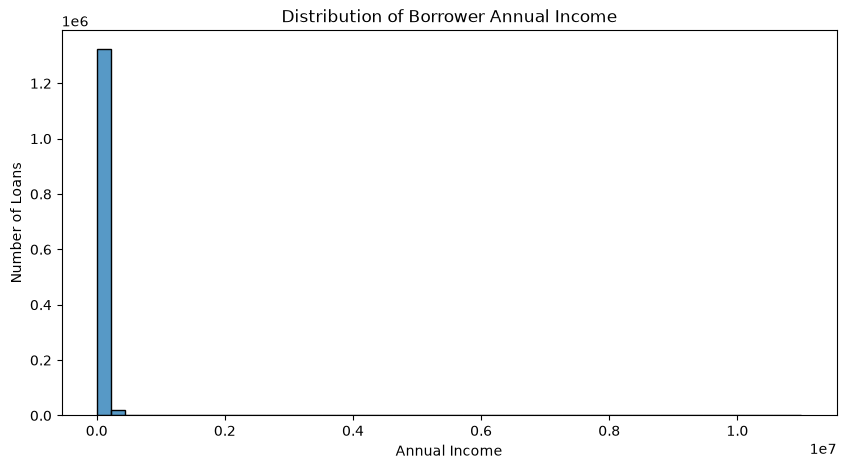

In [27]:
# Annual Income Distribution

plt.figure(figsize=(10,5))

sns.histplot(
    data = df,
    x = "revenue",
    bins = 50
    
)

plt.title("Distribution of Borrower Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Loans")

plt.show()


### Annual Income Distribution

- Annual income is highly right-skewed.
- Most loan records are concentrated in the lower income ranges.
- A small number of extremely high incomes extend the X-axis.
- The mean income (77,370) exceeds the median (65,000).
- Extreme values make the original histogram difficult to interpret.

**Decision:** Examine income within the 99th percentile for clearer visualization, without removing records from the dataset.


99th Percentile Income: 260000.0


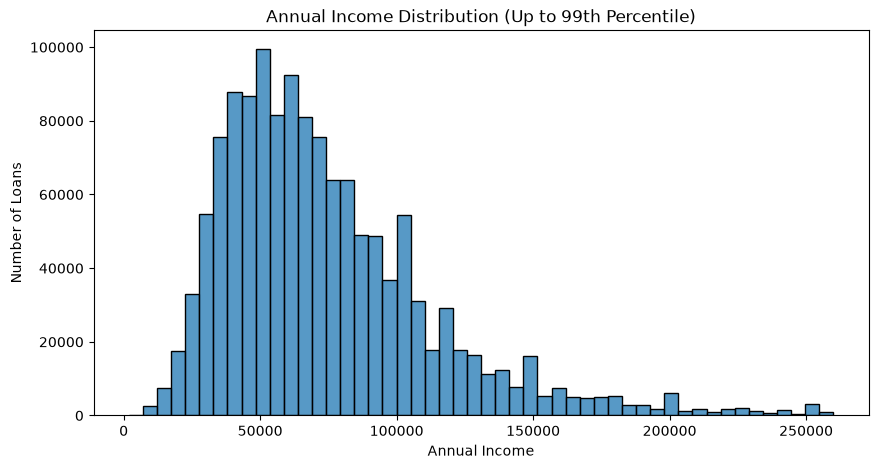

In [28]:

# Calculate the 99th percentile of annual income

income_p99 = df["revenue"].quantile(0.99)

print("99th Percentile Income:", income_p99)

# Visualize income within the 99th percentile

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df.loc[df["revenue"] <= income_p99],
    x="revenue",
    bins=50
)

plt.title("Annual Income Distribution (Up to 99th Percentile)")
plt.xlabel("Annual Income")
plt.ylabel("Number of Loans")

plt.show()



### Annual Income Distribution — 99th Percentile

- The 99th percentile of annual income is 260,000.
- Most loan records are concentrated around 40,000–70,000.
- The distribution remains right-skewed, with fewer high-income records.
- The original histogram was compressed by extreme income values.
- Restricting the visualization to the 99th percentile improved readability without modifying the original dataset.

**Business Insight:** The portfolio is concentrated in moderate-income ranges. Further analysis is needed to determine whether income levels are associated with different default rates.


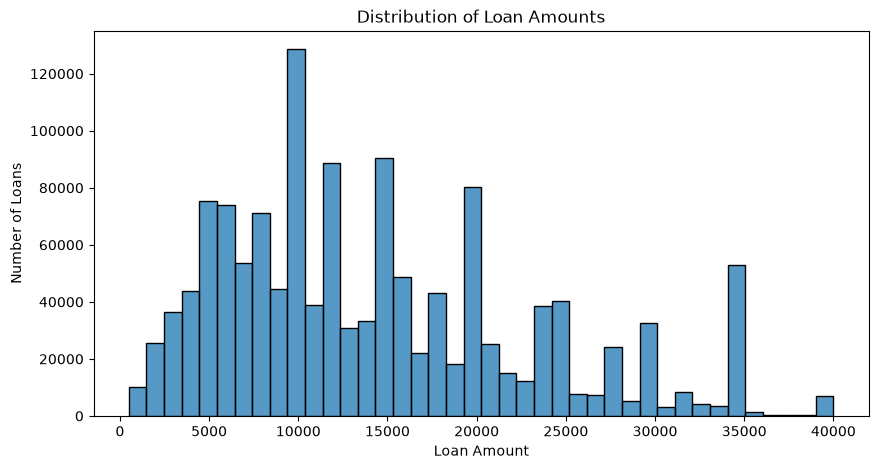

In [30]:

# Loan Amount Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="loan_amnt",
    bins=40
)

plt.title("Distribution of Loan Amounts")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Loans")

plt.show()



### Loan Amount Distribution

- Loan amounts range from 500 to 40,000.
- The highest concentration is around 10,000.
- Additional peaks appear near 15,000, 20,000 and 35,000.
- The distribution is right-skewed.
- Mean loan amount (14,408) exceeds the median (12,000).

**Business Insight:** The portfolio is concentrated in smaller and medium-sized loans. Larger loans are less frequent but may represent greater financial exposure per loan.


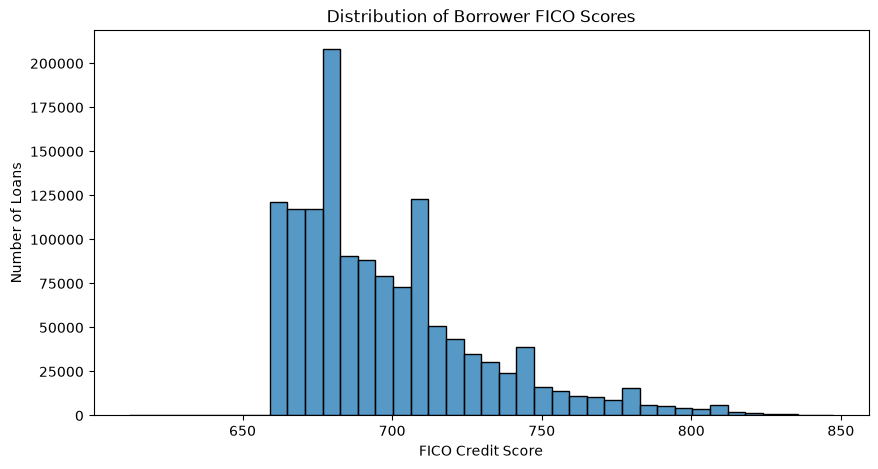

In [31]:

# FICO Credit Score Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="fico_n",
    bins=40
)

plt.title("Distribution of Borrower FICO Scores")
plt.xlabel("FICO Credit Score")
plt.ylabel("Number of Loans")

plt.show()



### FICO Credit Score Distribution

- FICO scores range from 612 to 847.5.
- Most loan records are concentrated around 660–715.
- The highest frequency occurs near a FICO score of 680.
- The distribution is right-skewed, with fewer very high-score borrowers.
- No FICO scores below 612 are observed.

**Business Insight:** The portfolio is concentrated among fair-to-good credit score borrowers. Further analysis is required to understand the relationship between credit scores and default risk.


99th Percentile DTI: 38.48


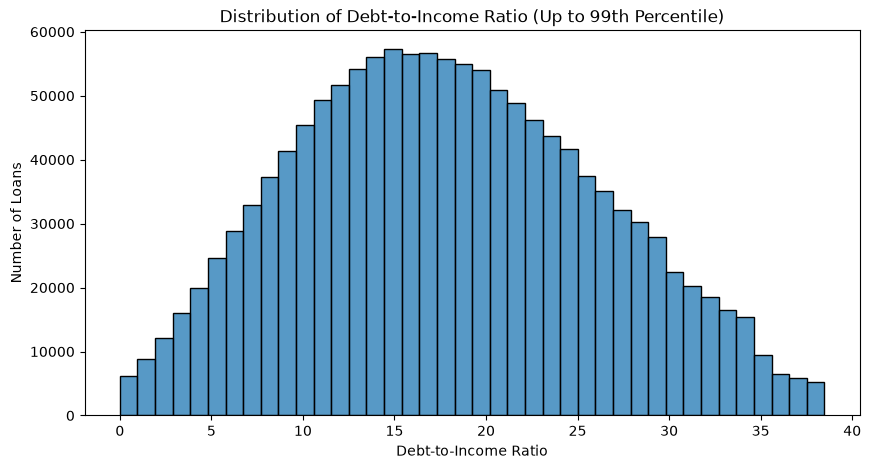

In [33]:

# DTI Distribution - focus on 99th percentile

dti_p99 = df["dti_n"].quantile(0.99)

print("99th Percentile DTI:", dti_p99)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df.loc[df["dti_n"] <= dti_p99],
    x="dti_n",
    bins=40
)

plt.title("Distribution of Debt-to-Income Ratio (Up to 99th Percentile)")
plt.xlabel("Debt-to-Income Ratio")
plt.ylabel("Number of Loans")

plt.show()



### Debt-to-Income (DTI) Distribution

- The 99th percentile DTI is 38.48.
- Most loan records are concentrated around DTI values of 14–20.
- The distribution is approximately bell-shaped, with a slight right skew.
- Both low- and high-DTI borrowers are represented.
- Extreme DTI values are excluded from this visualization only.

**Business Insight:** The portfolio contains borrowers with different debt burdens. Further analysis is required to determine whether higher DTI is associated with higher default rates.


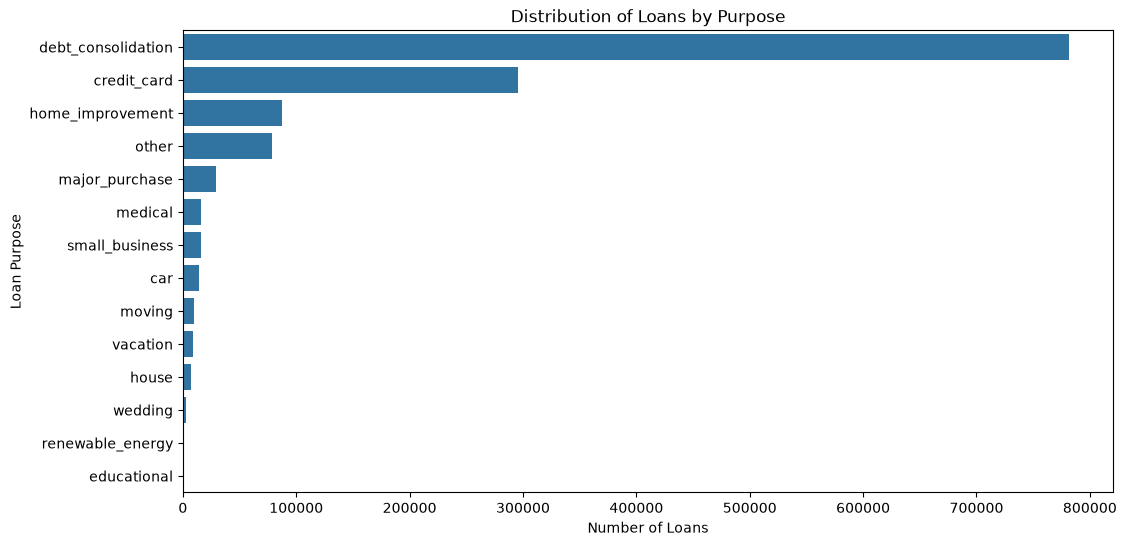

In [34]:

# Loan Purpose Distribution

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="purpose",
    order=df["purpose"].value_counts().index
)

plt.title("Distribution of Loans by Purpose")
plt.xlabel("Number of Loans")
plt.ylabel("Loan Purpose")

plt.show()



### Loan Purpose Distribution

- Debt consolidation is the most common purpose (58.0%).
- Credit card loans are second (21.9%).
- Together, these two purposes account for approximately 80% of loan records.
- Home improvement and other purposes have much smaller volumes.
- Educational and renewable energy loans are the least common.

**Business Insight:** The portfolio is heavily concentrated in debt-related borrowing. Further analysis is needed to compare loan exposure and default rates across purposes.


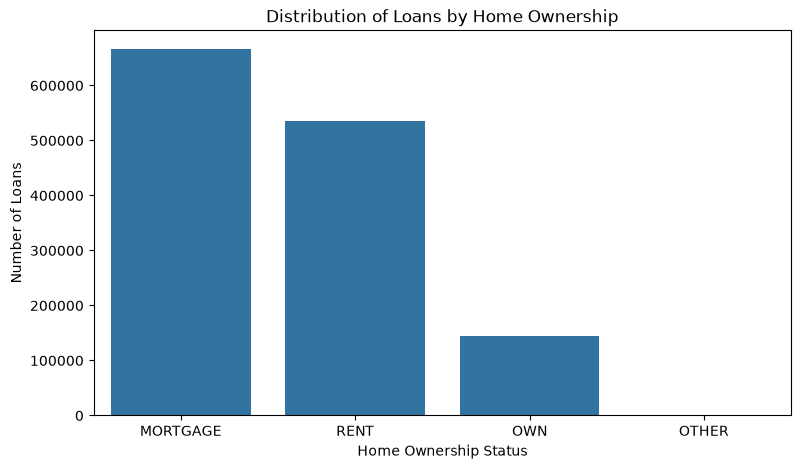

In [35]:

# Home Ownership Distribution

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="home_ownership_n",
    order=df["home_ownership_n"].value_counts().index
)

plt.title("Distribution of Loans by Home Ownership")
plt.xlabel("Home Ownership Status")
plt.ylabel("Number of Loans")

plt.show()



### Home Ownership Distribution

- Mortgage borrowers represent the largest category (49.5%).
- Renters account for 39.7% of loan records.
- Borrowers owning homes without mortgages represent 10.8%.
- The OTHER category is negligible (0.04%).
- Mortgage and rental categories together represent approximately 89% of the portfolio.

**Business Insight:** Most loans belong to borrowers with mortgage or rental housing arrangements. Housing status alone is insufficient to determine repayment risk.


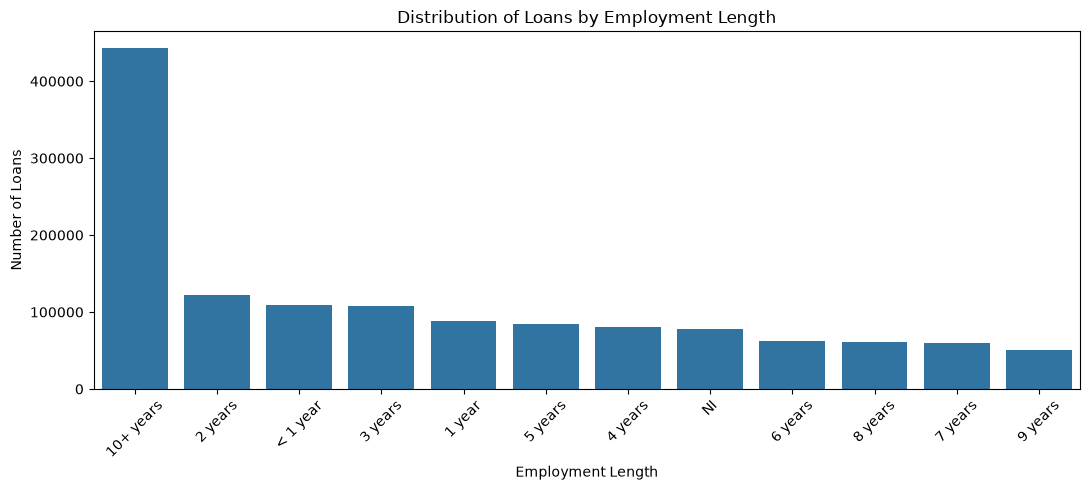

In [36]:

# Employment Length Distribution

plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="emp_length",
    order=df["emp_length"].value_counts().index
)

plt.title("Distribution of Loans by Employment Length")
plt.xlabel("Employment Length")
plt.ylabel("Number of Loans")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Employment Length Distribution

- Borrowers reporting 10+ years of employment represent the largest group (32.8%).
- Borrowers with 2 years and less than 1 year of employment also represent noticeable portions of the portfolio.
- The 9-year category has the lowest loan count.
- The NI category accounts for approximately 5.8% of records and requires definition verification.

**Business Insight:** The portfolio contains borrowers across different employment-tenure groups, with a strong concentration in the 10+ years category. Employment length alone cannot establish repayment risk.


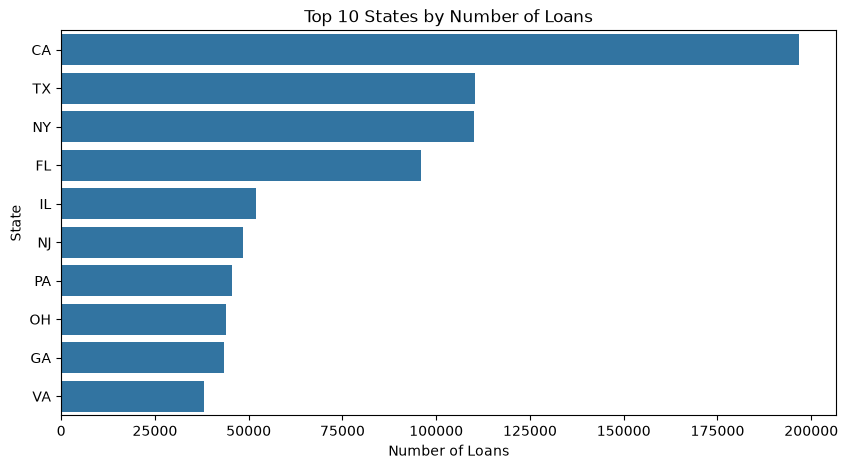

In [37]:

# Top 10 States by Loan Count

top_10_states = df["addr_state"].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_10_states.values,
    y=top_10_states.index
)

plt.title("Top 10 States by Number of Loans")
plt.xlabel("Number of Loans")
plt.ylabel("State")

plt.show()



### Geographic Distribution of Loans

- California has the highest loan volume (196,805 records; 14.6%).
- Texas and New York follow with approximately 110,000 loans each.
- Florida ranks fourth with approximately 95,800 loans.
- The top four states account for approximately 38.1% of the portfolio.
- Virginia ranks tenth among the states shown.

**Business Insight:** The portfolio shows geographic concentration, particularly in California. Further analysis is needed to understand regional lending exposure and default risk.


Default Counts:
Default
0    1078432
1     269249
Name: count, dtype: int64

Default Percentages:
Default
0    80.02
1    19.98
Name: proportion, dtype: float64


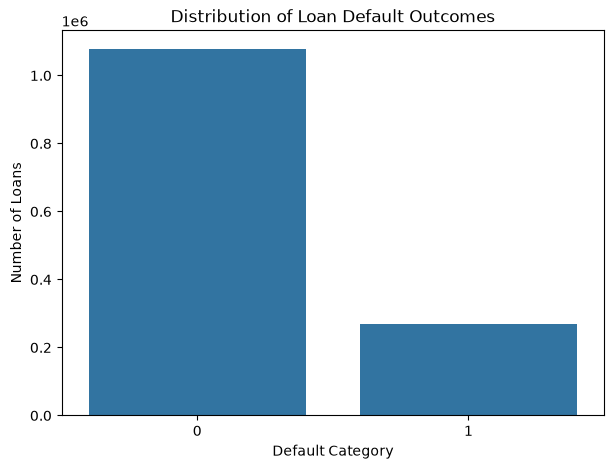

In [38]:

# Overall Default Distribution

default_counts = df["Default"].value_counts().sort_index()
default_percentages = df["Default"].value_counts(
    normalize=True
).sort_index() * 100

print("Default Counts:")
print(default_counts)

print("\nDefault Percentages:")
print(default_percentages.round(2))

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Default",
    order=[0, 1]
)

plt.title("Distribution of Loan Default Outcomes")
plt.xlabel("Default Category")
plt.ylabel("Number of Loans")

plt.show()



### Overall Default Distribution

- Non-default loans represent 80.02% of the portfolio.
- Default loans represent 19.98%.
- The dataset has an imbalanced default distribution, approximately 4:1.
- The overall observed default rate is 19.98%, assuming Default = 1 indicates default.

**Business Insight:** Approximately one in five loans is classified as defaulted. This provides a baseline for comparing default rates across borrower segments after clustering.


In [39]:

# Default rate by FICO score range

fico_bins = [300, 580, 670, 740, 800, 850]
fico_labels = ["Poor", "Fair", "Good", "Very Good", "Exceptional"]

df["FICO_Category"] = pd.cut(
    df["fico_n"],
    bins=fico_bins,
    labels=fico_labels,
    include_lowest=True,
    right=False
)

fico_default_analysis = df.groupby(
    "FICO_Category",
    observed=True
)["Default"].agg(
    Loan_Count="count",
    Default_Rate="mean"
)

fico_default_analysis["Default_Rate"] *= 100

display(fico_default_analysis.round(2))


,Loan_Count,Default_Rate
FICO_Category,,
Fair,238506,26.30
Good,963883,19.97
Very Good,129847,10.04
Exceptional,15445,6.41



### FICO Score vs Default Rate

- Fair FICO borrowers have the highest observed default rate (26.30%).
- Good FICO borrowers have the largest loan volume (963,883), with a default rate of 19.97%.
- Default rates decrease to 10.04% for Very Good and 6.41% for Exceptional borrowers.
- No borrowers fall into the Poor FICO category.
- Higher FICO scores are associated with lower observed default rates.

**Business Insight:** FICO score is strongly associated with repayment outcomes in this portfolio. However, credit risk should be assessed using multiple borrower characteristics rather than FICO alone.


In [40]:

# Default rate by DTI range

dti_bins = [-0.01, 10, 20, 30, 40, float("inf")]
dti_labels = ["0–10", "10–20", "20–30", "30–40", "40+"]

df["DTI_Category"] = pd.cut(
    df["dti_n"],
    bins=dti_bins,
    labels=dti_labels,
    right=False
)

dti_default_analysis = df.groupby(
    "DTI_Category",
    observed=True
)["Default"].agg(
    Loan_Count="count",
    Default_Rate="mean"
)

dti_default_analysis["Default_Rate"] *= 100

display(dti_default_analysis.round(2))


,Loan_Count,Default_Rate
DTI_Category,,
0–10,245174,14.84
10–20,563230,17.85
20–30,410172,23.07
30–40,122297,29.12
40+,6808,30.67



### DTI vs Default Rate

- Default rates increase consistently across DTI categories.
- Borrowers with DTI 0–10 have the lowest default rate (14.84%).
- Borrowers with DTI 40+ have the highest default rate (30.67%).
- The 10–20 category contains the highest loan volume (563,230).
- The 40+ category includes extreme DTI values requiring further validation.

**Business Insight:** Higher DTI is associated with greater observed default risk. DTI may be an important feature for borrower segmentation, subject to appropriate outlier treatment.


In [42]:

# Default rate by loan amount range

loan_bins = [0, 5000, 10000, 15000, 20000, 30000, 40001]

loan_labels = [
    "Below 5K",
    "5K–10K",
    "10K–15K",
    "15K–20K",
    "20K–30K",
    "30K–40K"
]

df["Loan_Category"] = pd.cut(
    df["loan_amnt"],
    bins=loan_bins,
    labels=loan_labels,
    right=False
)

loan_default_analysis = df.groupby(
    "Loan_Category",
    observed=True
)["Default"].agg(
    Loan_Count="count",
    Default_Rate="mean"
)

loan_default_analysis["Default_Rate"] *= 100

display(loan_default_analysis.round(2))


,Loan_Count,Default_Rate
Loan_Category,,
Below 5K,133847,15.52
5K–10K,323710,16.71
10K–15K,313750,20.40
15K–20K,214042,22.13
20K–30K,252203,22.34
30K–40K,110129,24.22



### Loan Amount vs Default Rate

- Default rates generally increase with loan amount.
- Loans below 5K have the lowest default rate (15.52%).
- Loans between 30K and 40K have the highest default rate (24.22%).
- The difference between these categories is 8.70 percentage points.
- The 5K–10K category has the highest loan volume but a relatively low default rate.

**Business Insight:** Larger loan amounts are associated with higher observed default rates. Loan amount may be an important segmentation feature, but its relationship with default should be interpreted alongside income, FICO and DTI.


In [43]:

# Default rate by income group

df["Income_Category"] = pd.qcut(
    df["revenue"],
    q=5,
    labels=["Lowest", "Low", "Middle", "High", "Highest"]
)

income_default_analysis = df.groupby(
    "Income_Category",
    observed=True
)["Default"].agg(
    Loan_Count="count",
    Default_Rate="mean",
    Min_Income=lambda x: df.loc[x.index, "revenue"].min(),
    Max_Income=lambda x: df.loc[x.index, "revenue"].max()
)

income_default_analysis["Default_Rate"] *= 100

display(income_default_analysis.round(2))


,Loan_Count,Default_Rate,Min_Income,Max_Income
Income_Category,,,,
Lowest,269539,23.32,1896.00,42675.0
Low,275302,21.49,42678.00,58000.0
Middle,287061,20.35,58000.08,75000.0
High,253569,18.47,75000.12,100000.0
Highest,262210,16.01,100000.16,10999200.0



### Income vs Default Rate

- Default rates decrease consistently as borrower income increases.
- The Lowest income group has the highest default rate (23.32%).
- The Highest income group has the lowest default rate (16.01%).
- The difference between these groups is 7.31 percentage points.
- Quantile-based grouping creates approximately equal-sized income segments.

**Business Insight:** Higher income is associated with lower observed default rates. Income may help distinguish borrower risk profiles, but it should be analysed alongside DTI, FICO and loan amount.


In [44]:

# Default rate by loan purpose

purpose_default_analysis = df.groupby(
    "purpose"
)["Default"].agg(
    Loan_Count="count",
    Default_Rate="mean"
)

purpose_default_analysis["Default_Rate"] *= 100

purpose_default_analysis = purpose_default_analysis.sort_values(
    by="Default_Rate",
    ascending=False
)

display(purpose_default_analysis.round(2))


,Loan_Count,Default_Rate
purpose,,
small_business,15575,29.86
renewable_energy,936,23.72
moving,9520,23.41
house,7294,21.91
medical,15606,21.84
debt_consolidation,781206,21.15
other,78263,21.08
educational,423,20.80
vacation,9083,19.19



### Loan Purpose vs Default Rate

- Small business loans have the highest observed default rate (29.86%).
- Wedding loans have the lowest observed default rate (12.43%).
- Debt consolidation has the highest loan volume (781,206) and a default rate of 21.15%.
- Credit card loans have a lower default rate (16.93%) than debt consolidation.
- Small categories such as renewable energy and educational loans require cautious interpretation.

**Business Insight:** Loan purpose is associated with different default patterns. High-volume categories and high-default-rate categories should be evaluated separately when assessing portfolio risk.


In [45]:

# Default rate by home ownership

home_default_analysis = df.groupby(
    "home_ownership_n"
)["Default"].agg(
    Loan_Count="count",
    Default_Rate="mean"
)

home_default_analysis["Default_Rate"] *= 100

home_default_analysis = home_default_analysis.sort_values(
    by="Default_Rate",
    ascending=False
)

display(home_default_analysis.round(2))


,Loan_Count,Default_Rate
home_ownership_n,,
RENT,535585,23.23
OWN,144985,20.63
OTHER,517,19.73
MORTGAGE,666594,17.23



### Home Ownership vs Default Rate

- RENT has the highest observed default r
- ate (23.23%).
- MORTGAGE has the lowest default rate (17.23%) and the highest loan volume (666,594).
- OWN has a default rate of 20.63%.
- The default rate difference between RENT and MORTGAGE is 6 percentage points.
- OTHER has only 517 loans, so its rate requires cautious interpretation.

**Business Insight:** Housing status is associated with differences in observed default rates. However, it should be interpreted alongside income, FICO and DTI rather than treated as an independent explanation of default risk.


In [47]:

# Default rate by employment length

employment_default_analysis = df.groupby(
    "emp_length"
)["Default"].agg(
    Loan_Count="count",
    Default_Rate="mean"
)

employment_default_analysis["Default_Rate"] *= 100

employment_default_analysis = employment_default_analysis.sort_values(
    by="Default_Rate",
    ascending=False
)

display(employment_default_analysis.round(2))


,Loan_Count,Default_Rate
emp_length,,
NI,78188,26.96
1 year,88841,20.59
< 1 year,108517,20.54
3 years,107862,19.99
8 years,60808,19.95
9 years,51019,19.91
2 years,122091,19.82
4 years,80761,19.76
5 years,84326,19.62



### Employment Length vs Default Rate

- NI has the highest observed default rate (26.96%), but its meaning requires verification.
- Borrowers with 10+ years of employment have the lowest default rate (18.80%).
- Default rates generally vary between 19% and 21% across the other employment categories.
- The relationship between employment length and default is not strictly decreasing.
- Employment length may help describe borrower segments, but should not be used alone to assess risk.

**Business Insight:** Longer employment history is associated with somewhat lower observed default rates, although the relationship is weaker and less consistent than the patterns observed for FICO and DTI.


In [48]:

# Default rate by state

state_default_analysis = df.groupby(
    "addr_state"
)["Default"].agg(
    Loan_Count="count",
    Default_Rate="mean"
)

state_default_analysis["Default_Rate"] *= 100

# Keep states with at least 1,000 loans
state_default_analysis = state_default_analysis[
    state_default_analysis["Loan_Count"] >= 1000
]

# Sort by highest default rate
state_default_analysis = state_default_analysis.sort_values(
    by="Default_Rate",
    ascending=False
)

display(state_default_analysis.round(2))


,Loan_Count,Default_Rate
addr_state,,
MS,6593,26.12
NE,3591,25.20
AR,10058,24.11
AL,16640,23.64
OK,12291,23.46
LA,15520,23.17
NY,110075,22.05
NV,20282,21.98
FL,95815,21.50


In [49]:

# Compare default counts and default rates by state

state_risk_summary = df.groupby(
    "addr_state"
)["Default"].agg(
    Loan_Count="count",
    Default_Count="sum",
    Default_Rate="mean"
)

state_risk_summary["Default_Rate"] *= 100

state_risk_summary = state_risk_summary.sort_values(
    by="Default_Count",
    ascending=False
)

display(state_risk_summary.head(10).round(2))


,Loan_Count,Default_Count,Default_Rate
addr_state,,,
CA,196805,38633,19.63
NY,110075,24267,22.05
TX,110307,21881,19.84
FL,95815,20599,21.50
NJ,48576,10258,21.12
PA,45640,9502,20.82
IL,51858,9394,18.11
OH,43935,9015,20.52
GA,43470,8011,18.43



### State-wise Default Count vs Default Rate

- California has the highest number of defaulted loans (38,633), with a default rate of 19.63%.
- New York ranks second by default count (24,267), followed by Texas (21,881).
- Mississippi has the highest default rate (26.12%) but does not appear among the top 10 states by default count.
- High default rates do not necessarily correspond to high default counts.

**Business Insight:** Portfolio risk should be evaluated using both default rates and default counts. Default rates describe the frequency of default, while default counts show the volume of affected loans.


In [50]:

# Correlation between numerical borrower features

numerical_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n"
]

correlation_matrix = df[numerical_features].corr()

display(correlation_matrix.round(2))


,revenue,dti_n,loan_amnt,fico_n
revenue,1.00,-0.11,0.32,0.08
dti_n,-0.11,1.00,0.03,-0.06
loan_amnt,0.32,0.03,1.00,0.10
fico_n,0.08,-0.06,0.10,1.00


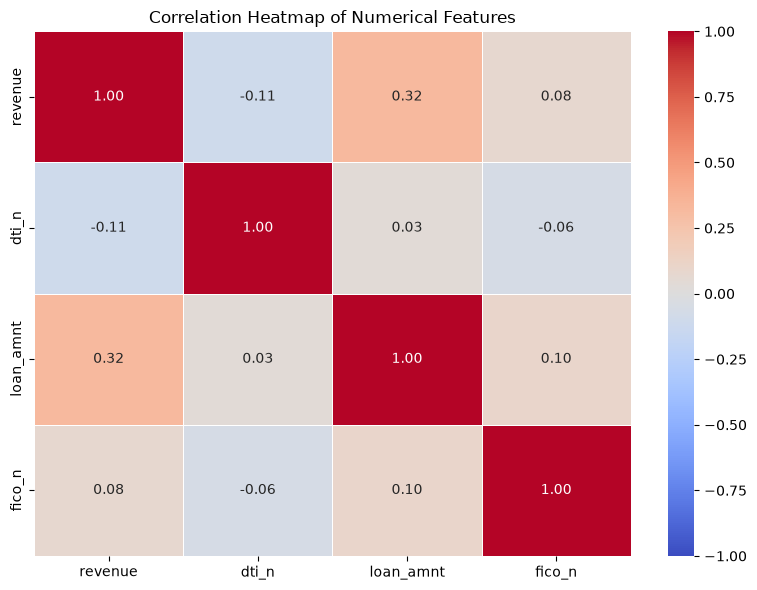

In [51]:

import matplotlib.pyplot as plt
import seaborn as sns

# Plot numerical feature correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()



### Numerical Feature Correlation Analysis

- Income and loan amount have the strongest positive correlation (0.32).
- Income and DTI have the strongest negative correlation (-0.11).
- Other feature pairs show very weak linear relationships.
- No strong pairwise linear correlation was observed among the four numerical features.

**Business Insight:** The numerical features provide different information about borrower characteristics. Feature scaling and outlier treatment will be important before distance-based clustering.


In [52]:

# Compare DTI = 999 records with other borrowers

dti_999_analysis = df.assign(
    DTI_Group=df["dti_n"].apply(
        lambda x: "DTI = 999" if x == 999 else "Other DTI"
    )
).groupby("DTI_Group")["Default"].agg(
    Loan_Count="count",
    Default_Rate="mean"
)

dti_999_analysis["Default_Rate"] *= 100

display(dti_999_analysis.round(2))


,Loan_Count,Default_Rate
DTI_Group,,
DTI = 999,38,23.68
Other DTI,1347643,19.98



### DTI = 999 Investigation

- Only 38 loans have DTI = 999.
- Their observed default rate is 23.68%, compared with 19.98% for other loans.
- The sample is too small for a reliable comparison.
- The meaning of DTI = 999 remains unverified.

**Data Quality Decision:** Flag DTI = 999 for further investigation before clustering. Avoid treating it as an ordinary DTI value without validation.


In [53]:

# Investigate extreme DTI values

extreme_dti = df.loc[df["dti_n"] > 100, "dti_n"]

print("Number of DTI values above 100:", len(extreme_dti))

print("\nSummary of extreme DTI values:")
display(extreme_dti.describe())

print("\nMost frequent extreme DTI values:")
display(extreme_dti.value_counts().head(10))


Number of DTI values above 100: 533

Summary of extreme DTI values:


count    533.000000
mean     266.213583
std      250.901005
min      100.040000
25%      119.590000
50%      161.940000
75%      265.600000
max      999.000000
Name: dti_n, dtype: float64


Most frequent extreme DTI values:


dti_n
999.00    38
163.25     2
107.84     2
101.20     2
101.50     2
105.38     2
102.73     2
149.46     2
380.72     2
117.71     2
Name: count, dtype: int64


### Extreme DTI Investigation

- 533 records (approximately 0.04%) have DTI values above 100.
- The median extreme DTI is 161.94, while the mean is 266.21.
- DTI = 999 occurs 38 times and may represent a special value.
- DTI above 100 is not necessarily invalid.
- Extreme DTI values may distort distance-based clustering.

**Data Quality Decision:** Preserve original DTI values and investigate the distribution before choosing an outlier treatment strategy.


In [54]:

# Examine DTI percentiles

dti_percentiles = df["dti_n"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.00]
)

display(dti_percentiles)


0.500     17.6300
0.750     24.0700
0.900     29.7800
0.950     32.9900
0.990     38.4800
0.995     40.1100
0.999     65.9992
1.000    999.0000
Name: dti_n, dtype: float64


### DTI Percentile Analysis

- Median DTI is 17.63.
- 99% of loans have DTI at or below 38.48.
- 99.9% of loans have DTI at or below approximately 66.
- The maximum DTI is 999, indicating an extreme upper tail.
- All 533 records with DTI above 100 fall beyond the 99.9th percentile.

**Preprocessing Insight:** Extreme DTI values may disproportionately affect distance-based clustering. An appropriate outlier treatment should be evaluated while preserving the original data.


In [55]:

# DTI percentile capping experiment

dti_cap = df["dti_n"].quantile(0.995)

df["DTI_Capped_Test"] = df["dti_n"].clip(
    upper=dti_cap
)

comparison = pd.DataFrame({
    "Original_DTI": df["dti_n"].describe(),
    "Capped_DTI": df["DTI_Capped_Test"].describe()
})

print("Capping threshold:", round(dti_cap, 2))

display(comparison.round(2))

print("Number of values modified:",
      (df["dti_n"] > dti_cap).sum())

print("Total borrowers remaining:", len(df))


Capping threshold: 40.11


,Original_DTI,Capped_DTI
count,1347681.00,1347681.00
mean,18.30,18.16
std,11.15,8.47
min,0.00,0.00
25%,11.82,11.82
50%,17.63,17.63
75%,24.07,24.07
max,999.00,40.11


Number of values modified: 6732
Total borrowers remaining: 1347681


**Observation:** Applying upper capping at the 99.5th percentile (DTI = 40.11) modified 6,732 records (0.50%). The mean decreased slightly from 18.30 to 18.16, while the standard deviation decreased from 11.15 to 8.47. The median remained unchanged, and all 1,347,681 borrower records were preserved. Capping reduced the influence of extreme DTI values, but its suitability for clustering still needs evaluation.

In [56]:

# Compare IQR and percentile capping thresholds

Q1 = df["dti_n"].quantile(0.25)
Q3 = df["dti_n"].quantile(0.75)

IQR = Q3 - Q1

iqr_upper = Q3 + 1.5 * IQR

percentile_upper = df["dti_n"].quantile(0.995)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))

print("\nIQR upper boundary:", round(iqr_upper, 2))
print("Percentile upper boundary:", round(percentile_upper, 2))

print("\nValues above IQR boundary:",
      (df["dti_n"] > iqr_upper).sum())

print("Values above percentile boundary:",
      (df["dti_n"] > percentile_upper).sum())


Q1: 11.82
Q3: 24.07
IQR: 12.25

IQR upper boundary: 42.44
Percentile upper boundary: 40.11

Values above IQR boundary: 5506
Values above percentile boundary: 6732


**Observation:** The IQR method produced an upper DTI boundary of 42.44, affecting 5,506 borrowers (0.41%). The 99.5th-percentile method produced a lower boundary of 40.11, affecting 6,732 borrowers (0.50%). IQR capping would preserve slightly more variation among high-DTI borrowers. Both methods require further evaluation before selecting a final preprocessing strategy.

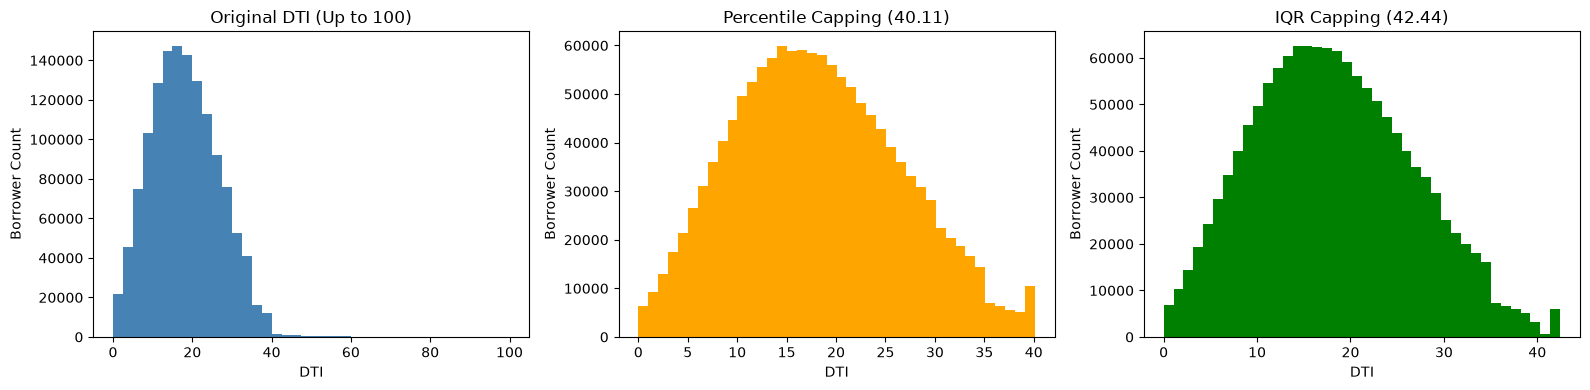

In [57]:

# Visual comparison of DTI capping methods

import matplotlib.pyplot as plt

df["DTI_IQR_Test"] = df["dti_n"].clip(upper=iqr_upper)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(
    df.loc[df["dti_n"] <= 100, "dti_n"],
    bins=40,
    color="steelblue"
)
axes[0].set_title("Original DTI (Up to 100)")

axes[1].hist(
    df["DTI_Capped_Test"],
    bins=40,
    color="orange"
)
axes[1].set_title("Percentile Capping (40.11)")

axes[2].hist(
    df["DTI_IQR_Test"],
    bins=40,
    color="green"
)
axes[2].set_title("IQR Capping (42.44)")

for ax in axes:
    ax.set_xlabel("DTI")
    ax.set_ylabel("Borrower Count")

plt.tight_layout()
plt.show()


**Observation:** Both capping methods preserve the main DTI distribution while limiting extreme upper values. The percentile method caps DTI at 40.11, whereas the IQR method caps it at 42.44. Both create a concentration of observations at their respective upper boundaries. The IQR method modifies fewer borrowers and preserves slightly more upper-tail variation. Further investigation is required before selecting a preprocessing method.

In [58]:

# Default rates across DTI capping boundaries

import numpy as np

df["DTI_Range_Test"] = pd.cut(
    df["dti_n"],
    bins=[-np.inf, percentile_upper, iqr_upper, np.inf],
    labels=[
        "DTI <= Percentile Cap",
        "Between Percentile and IQR Caps",
        "DTI > IQR Cap"
    ]
)

dti_risk_comparison = (
    df.groupby("DTI_Range_Test", observed=True)
      .agg(
          Loan_Count=("Default", "count"),
          Default_Rate=("Default", "mean")
      )
)

dti_risk_comparison["Default_Rate"] *= 100

display(dti_risk_comparison.round(2))


,Loan_Count,Default_Rate
DTI_Range_Test,,
DTI <= Percentile Cap,1340949,19.93
Between Percentile and IQR Caps,1226,31.89
DTI > IQR Cap,5506,30.37


**Observation:** Borrowers with DTI ≤ 40.11 had a default rate of 19.93%, compared with 31.89% for DTI between 40.11 and 42.44 and 30.37% for DTI above 42.44. This indicates an association between high DTI and increased default risk. Capping may reduce extreme-value influence on clustering but can also remove meaningful differences among high-DTI borrowers.

In [59]:

# Investigate DTI = 999 borrowers

dti_999 = df.loc[df["dti_n"] == 999]

print("Number of borrowers with DTI = 999:", len(dti_999))

print("\nStatistics for DTI = 999 borrowers:")
display(
    dti_999[
        ["revenue", "loan_amnt", "fico_n", "Default"]
    ].describe().round(2)
)

print("\nSample records:")
display(
    dti_999[
        ["revenue", "loan_amnt", "fico_n", "dti_n", "Default"]
    ].head(10)
)


Number of borrowers with DTI = 999: 38

Statistics for DTI = 999 borrowers:


,revenue,loan_amnt,fico_n,Default
count,38.00,38.00,38.00,38.00
mean,121625.03,21169.08,703.45,0.24
std,63820.67,10625.41,29.79,0.43
min,36020.00,5000.00,662.00,0.00
25%,67499.75,10062.50,678.25,0.00
50%,121000.00,20750.00,699.50,0.00
75%,158484.75,29900.00,722.00,0.00
max,243000.00,40000.00,777.00,1.00



Sample records:


,revenue,loan_amnt,fico_n,dti_n,Default
7767,62151.0,6550,672.0,999.0,0
381305,78800.0,8000,687.0,999.0,0
386273,66633.0,10250,712.0,999.0,0
394079,126665.0,14225,752.0,999.0,0
398115,58800.0,15000,717.0,999.0,0
398172,153000.0,26000,762.0,999.0,0
402650,76000.0,21000,692.0,999.0,0
404149,138100.0,10000,722.0,999.0,0
411443,160300.0,35000,672.0,999.0,0
417509,145600.0,35000,677.0,999.0,1


In [60]:

#Examine the extreme DTI tail

extreme_dti = df.loc[df["dti_n"] > 100, "dti_n"]

print("Number of DTI values above 100:", len(extreme_dti))

print("\nExtreme DTI summary:")
display(extreme_dti.describe().round(2))

print("\nMost frequently repeated extreme values:")
display(extreme_dti.value_counts().head(15))

print("\nDTI values by extreme range:")
display(
    pd.cut(
        extreme_dti,
        bins=[100, 150, 200, 300, 500, 999],
        include_lowest=False
    ).value_counts().sort_index()
)


Number of DTI values above 100: 533

Extreme DTI summary:


count    533.00
mean     266.21
std      250.90
min      100.04
25%      119.59
50%      161.94
75%      265.60
max      999.00
Name: dti_n, dtype: float64


Most frequently repeated extreme values:


dti_n
999.00    38
163.25     2
107.84     2
101.20     2
101.50     2
105.38     2
102.73     2
149.46     2
380.72     2
117.71     2
132.29     2
104.00     2
110.56     2
231.97     1
151.20     1
Name: count, dtype: int64


DTI values by extreme range:


dti_n
(100, 150]    246
(150, 200]     88
(200, 300]     86
(300, 500]     42
(500, 999]     71
Name: count, dtype: int64

**Observation:** A total of 533 borrowers (0.04%) have DTI above 100. Extreme values are distributed across several ranges, with the largest group between 100 and 150. However, DTI = 999 occurs 38 times, substantially more frequently than other individual extreme values. This may indicate a special code or system limit, but further documentation is required to confirm its meaning.

In [61]:

# Default rates across extreme DTI ranges

extreme_dti_df = df.loc[df["dti_n"] > 100].copy()

extreme_dti_df["Extreme_DTI_Group"] = pd.cut(
    extreme_dti_df["dti_n"],
    bins=[100, 150, 200, 300, 500, 999],
    labels=[
        "100-150",
        "150-200",
        "200-300",
        "300-500",
        "500-999"
    ]
)

extreme_risk = (
    extreme_dti_df
    .groupby("Extreme_DTI_Group", observed=True)
    .agg(
        Borrower_Count=("Default", "count"),
        Default_Rate=("Default", "mean")
    )
)

extreme_risk["Default_Rate"] *= 100

display(extreme_risk.round(2))


,Borrower_Count,Default_Rate
Extreme_DTI_Group,,
100-150,246,32.11
150-200,88,20.45
200-300,86,22.09
300-500,42,23.81
500-999,71,23.94


**Observation:** Default rates across DTI values above 100 ranged from 20.45% to 32.11%, without a consistent increasing pattern. The highest rate occurred in the 100–150 range. However, these groups contain relatively few borrowers, so the results should be interpreted cautiously. Extreme DTI values may influence clustering distances, but their treatment requires further evaluation.

In [62]:

#Compare original, percentile-capped and IQR-capped DTI

dti_comparison = pd.DataFrame({
    "Original_DTI": df["dti_n"].describe(),
    "Percentile_Capped": df["DTI_Capped_Test"].describe(),
    "IQR_Capped": df["DTI_IQR_Test"].describe()
})

display(dti_comparison.round(2))

print("Original DTI maximum:", df["dti_n"].max())
print("Percentile-capped maximum:", round(df["DTI_Capped_Test"].max(), 2))
print("IQR-capped maximum:", round(df["DTI_IQR_Test"].max(), 2))


,Original_DTI,Percentile_Capped,IQR_Capped
count,1347681.00,1347681.00,1347681.00
mean,18.30,18.16,18.17
std,11.15,8.47,8.50
min,0.00,0.00,0.00
25%,11.82,11.82,11.82
50%,17.63,17.63,17.63
75%,24.07,24.07,24.07
max,999.00,40.11,42.44


Original DTI maximum: 999.0
Percentile-capped maximum: 40.11
IQR-capped maximum: 42.44


**Observation:** Percentile capping reduced DTI standard deviation from 11.15 to 8.47, while IQR capping reduced it to 8.50. Both methods retained all 1,347,681 records and preserved the median of 17.63. Percentile capping produced slightly greater compression, while IQR capping retained more upper-tail variation. The final method should be selected based on clustering performance and business interpretability rather than standard deviation alone.

In [63]:
#Investigate annual income skewness

print("Annual income statistics:")
display(df["revenue"].describe().round(2))

print("\nAnnual income skewness:")
print(round(df["revenue"].skew(), 2))

print("\nAnnual income percentiles:")
display(
    df["revenue"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    ).round(2)
)


Annual income statistics:


count     1347681.00
mean        77369.68
std         70362.99
min          1896.00
25%         46600.00
50%         65000.00
75%         92000.00
max      10999200.00
Name: revenue, dtype: float64


Annual income skewness:
45.4

Annual income percentiles:


0.500     65000.0
0.750     92000.0
0.900    129000.0
0.950    160000.0
0.990    260000.0
0.999    585000.0
Name: revenue, dtype: float64

**Observation:** Annual income is extremely right-skewed, with skewness of 45.40. The mean income (77,369.68) exceeds the median (65,000), and the maximum income (10,999,200) is substantially higher than the 99th percentile (260,000). Extreme income values may disproportionately influence distance-based clustering. Log transformation will be evaluated to reduce skewness while retaining all borrower records.

In [64]:

# Log transformation of annual income

import numpy as np

df["Revenue_Log_Test"] = np.log1p(df["revenue"])

comparison = pd.DataFrame({
    "Original_Income": df["revenue"].describe(),
    "Log_Income": df["Revenue_Log_Test"].describe()
})

display(comparison.round(2))

print("Original income skewness:",
      round(df["revenue"].skew(), 2))

print("Log-transformed income skewness:",
      round(df["Revenue_Log_Test"].skew(), 2))

print("Total borrowers:", len(df))


,Original_Income,Log_Income
count,1347681.00,1347681.00
mean,77369.68,11.10
std,70362.99,0.54
min,1896.00,7.55
25%,46600.00,10.75
50%,65000.00,11.08
75%,92000.00,11.43
max,10999200.00,16.21


Original income skewness: 45.4
Log-transformed income skewness: 0.21
Total borrowers: 1347681


**Observation:** Log transformation reduced annual income skewness from 45.40 to 0.21 while preserving all 1,347,681 records. The transformation compressed the extreme right tail and produced a more symmetric income distribution. Log-transformed income is a promising feature for distance-based clustering, subject to further evaluation.

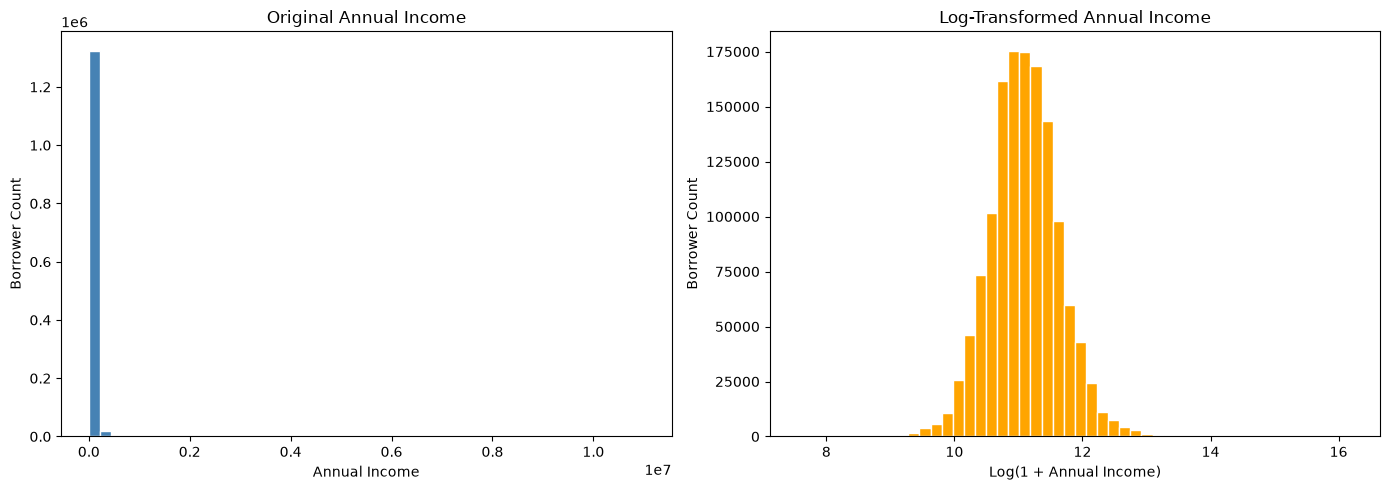

In [66]:

# Visual comparison of income distributions

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    df["revenue"],
    bins=50,
    color="steelblue",
    edgecolor="white"
)
axes[0].set_title("Original Annual Income")
axes[0].set_xlabel("Annual Income")
axes[0].set_ylabel("Borrower Count")

axes[1].hist(
    df["Revenue_Log_Test"],
    bins=50,
    color="orange",
    edgecolor="white"
)
axes[1].set_title("Log-Transformed Annual Income")
axes[1].set_xlabel("Log(1 + Annual Income)")
axes[1].set_ylabel("Borrower Count")

plt.tight_layout()
plt.show()


**Observation:** The original annual income histogram is highly compressed toward the left because a small number of extreme incomes stretch the x-axis. After log transformation, the distribution becomes substantially more symmetric, consistent with the reduction in skewness from 45.40 to 0.21. Log transformation is a promising preprocessing approach for clustering, although its effectiveness must be evaluated.

In [67]:

#Prepare numerical features for clustering

clustering_features = [
    "Revenue_Log_Test",
    "DTI_IQR_Test",
    "loan_amnt",
    "fico_n"
]

X_numeric = df[clustering_features].copy()

print("Shape of numerical feature dataset:")
print(X_numeric.shape)

print("\nMissing values:")
print(X_numeric.isnull().sum())

print("\nNumerical feature statistics:")
display(X_numeric.describe().round(2))


Shape of numerical feature dataset:
(1347681, 4)

Missing values:
Revenue_Log_Test    0
DTI_IQR_Test        0
loan_amnt           0
fico_n              0
dtype: int64

Numerical feature statistics:


,Revenue_Log_Test,DTI_IQR_Test,loan_amnt,fico_n
count,1347681.00,1347681.00,1347681.00,1347681.00
mean,11.10,18.17,14408.23,698.16
std,0.54,8.50,8715.35,31.85
min,7.55,0.00,500.00,612.00
25%,10.75,11.82,7975.00,672.00
50%,11.08,17.63,12000.00,692.00
75%,11.43,24.07,20000.00,712.00
max,16.21,42.44,40000.00,847.50


**Observation:** The numerical clustering dataset contains 1,347,681 borrower records and four features, with no missing values. Feature magnitudes differ substantially, particularly between loan amount, FICO, DTI and log-transformed income. Scaling is required before K-Means to prevent features with larger numerical ranges from dominating Euclidean distances.

In [68]:

#Compare StandardScaler and RobustScaler

from sklearn.preprocessing import StandardScaler, RobustScaler

standard_scaler = StandardScaler()
robust_scaler = RobustScaler()

X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X_numeric),
    columns=X_numeric.columns,
    index=X_numeric.index
)

X_robust = pd.DataFrame(
    robust_scaler.fit_transform(X_numeric),
    columns=X_numeric.columns,
    index=X_numeric.index
)

print("StandardScaler Statistics:")
display(X_standard.describe().round(2))

print("\nRobustScaler Statistics:")
display(X_robust.describe().round(2))


StandardScaler Statistics:


,Revenue_Log_Test,DTI_IQR_Test,loan_amnt,fico_n
count,1347681.00,1347681.00,1347681.00,1347681.00
mean,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-6.60,-2.14,-1.60,-2.71
25%,-0.65,-0.75,-0.74,-0.82
50%,-0.03,-0.06,-0.28,-0.19
75%,0.61,0.69,0.64,0.43
max,9.50,2.86,2.94,4.69



RobustScaler Statistics:


,Revenue_Log_Test,DTI_IQR_Test,loan_amnt,fico_n
count,1347681.00,1347681.00,1347681.00,1347681.00
mean,0.03,0.04,0.20,0.15
std,0.79,0.69,0.72,0.80
min,-5.20,-1.44,-0.96,-2.00
25%,-0.49,-0.47,-0.33,-0.50
50%,0.00,0.00,0.00,0.00
75%,0.51,0.53,0.67,0.50
max,7.54,2.03,2.33,3.89


**Observation:** StandardScaler transformed all four numerical features to approximately zero mean and unit standard deviation. RobustScaler centered the features at zero median and scaled their IQRs to approximately one. Both methods retained extreme observations. Since scaling affects Euclidean distances and K-Means cluster assignments, the final scaler should be selected through clustering evaluation rather than outlier presence alone.

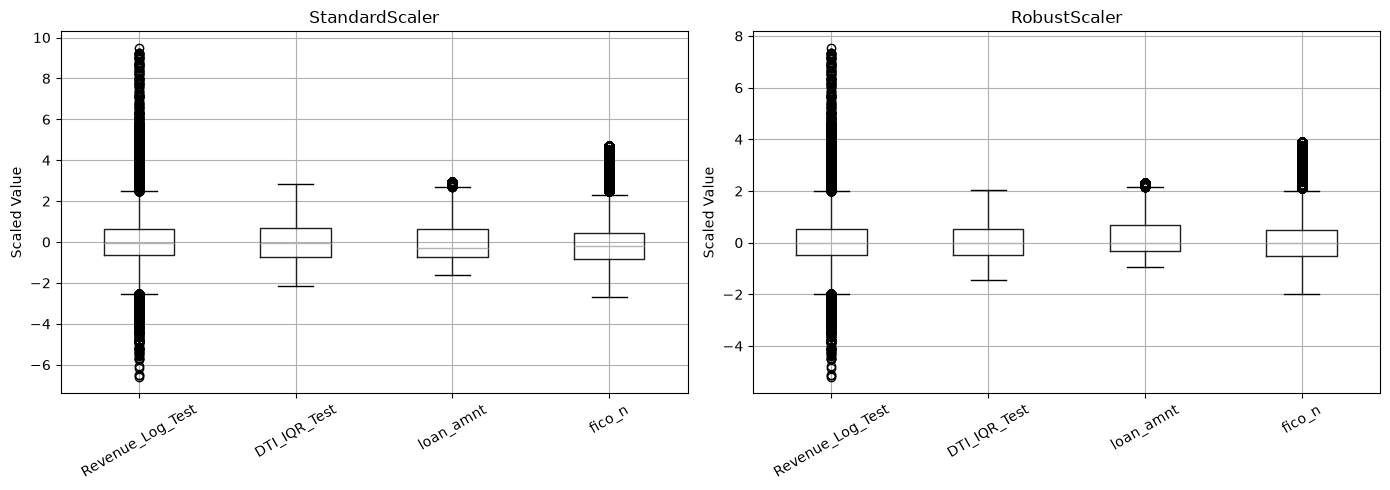

In [69]:

# Visual comparison of scaling methods

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

X_standard.boxplot(ax=axes[0], rot=30)
axes[0].set_title("StandardScaler")
axes[0].set_ylabel("Scaled Value")

X_robust.boxplot(ax=axes[1], rot=30)
axes[1].set_title("RobustScaler")
axes[1].set_ylabel("Scaled Value")

plt.tight_layout()
plt.show()


**Observation:** Boxplot comparisons show that StandardScaler and RobustScaler bring the numerical features into more comparable scales while preserving their distribution shapes and remaining extreme observations. Log-transformed income, loan amount and FICO retain outlier points. The IQR-capped DTI feature shows no outlier points because values above the original IQR upper boundary were capped rather than removed. Both methods are suitable candidates for further clustering evaluation.

In [70]:

# Compare feature spreads after scaling

comparison = pd.DataFrame({
    "StandardScaler_STD": X_standard.std(),
    "StandardScaler_IQR": X_standard.quantile(0.75) - X_standard.quantile(0.25),
    "RobustScaler_STD": X_robust.std(),
    "RobustScaler_IQR": X_robust.quantile(0.75) - X_robust.quantile(0.25)
})

display(comparison.round(3))


,StandardScaler_STD,StandardScaler_IQR,RobustScaler_STD,RobustScaler_IQR
Revenue_Log_Test,1.0,1.263,0.792,1.0
DTI_IQR_Test,1.0,1.441,0.694,1.0
loan_amnt,1.0,1.380,0.725,1.0
fico_n,1.0,1.256,0.796,1.0


**Observation:** StandardScaler produces approximately unit standard deviation across all numerical features, whereas RobustScaler produces unit IQR. The RobustScaler standard deviations range from 0.694 to 0.796 because standard deviation and IQR measure different aspects of dispersion. These results confirm successful scaling but do not establish which scaler produces better borrower clusters.

In [71]:

#Compare Euclidean distances after scaling

import numpy as np

# Select two borrowers for illustration
sample_indices = [0, 1]

print("Original borrower features:")
display(X_numeric.iloc[sample_indices])

for name, data in [
    ("StandardScaler", X_standard),
    ("RobustScaler", X_robust)
]:
    borrower_a = data.iloc[0].to_numpy()
    borrower_b = data.iloc[1].to_numpy()

    feature_differences = borrower_a - borrower_b
    squared_differences = feature_differences ** 2
    distance = np.sqrt(squared_differences.sum())

    print(f"\n{name}")
    print("Squared differences by feature:")
    display(pd.Series(
        squared_differences,
        index=data.columns
    ).round(4))

    print(f"Euclidean distance: {distance:.4f}")


Original borrower features:


,Revenue_Log_Test,DTI_IQR_Test,loan_amnt,fico_n
0,10.915107,5.91,3600,677.0
1,11.082158,16.06,24700,717.0



StandardScaler
Squared differences by feature:


Revenue_Log_Test    0.0963
DTI_IQR_Test        1.4264
loan_amnt           5.8613
fico_n              1.5774
dtype: float64

Euclidean distance: 2.9936

RobustScaler
Squared differences by feature:


Revenue_Log_Test    0.0603
DTI_IQR_Test        0.6865
loan_amnt           3.0789
fico_n              1.0000
dtype: float64

Euclidean distance: 2.1968


**Observation:** Euclidean distance was calculated between two borrowers using StandardScaler and RobustScaler. The resulting distances were 2.9936 and 2.1968, respectively. Loan amount contributed the largest share of squared distance under both methods, approximately 65.4% and 63.8%. The relative contributions of DTI and FICO changed with the scaler, demonstrating that scaling influences the geometry of borrower similarity. A smaller distance under one scaler does not necessarily indicate better clustering.

In [72]:

# Step 46: Average contribution to squared distance

import numpy as np
import pandas as pd

# Randomly select 1000 borrower pairs
rng = np.random.default_rng(42)

indices_a = rng.integers(0, len(X_numeric), size=1000)
indices_b = rng.integers(0, len(X_numeric), size=1000)

results = {}

for name, data in [
    ("StandardScaler", X_standard),
    ("RobustScaler", X_robust)
]:
    a = data.iloc[indices_a].to_numpy()
    b = data.iloc[indices_b].to_numpy()

    squared_diff = (a - b) ** 2

    total_squared = squared_diff.sum(axis=1)

    # Exclude identical feature vectors, if any
    valid = total_squared > 0

    contributions = (
        squared_diff[valid] /
        total_squared[valid, np.newaxis]
    ) * 100

    results[name] = contributions.mean(axis=0)

comparison = pd.DataFrame(
    results,
    index=X_numeric.columns
)

display(comparison.round(2))


,StandardScaler,RobustScaler
Revenue_Log_Test,24.11,26.02
DTI_IQR_Test,25.99,23.42
loan_amnt,25.06,23.85
fico_n,24.83,26.72


**Observation:** Across 1,000 randomly sampled borrower pairs, the four numerical features contributed approximately 23%–27% each to squared Euclidean distance under both scaling methods. DTI had the highest average contribution under StandardScaler (25.99%), whereas FICO had the highest under RobustScaler (26.72%). The results indicate relatively balanced average distance contributions, but do not establish which scaler will produce more meaningful borrower clusters.

In [74]:

# Inspect candidate categorical features

categorical_features = [
    "emp_length",
    "home_ownership_n",
    "purpose",
    "addr_state"
]

for col in categorical_features:
    print(f"\nFeature: {col}")
    print("Unique categories:", df[col].nunique(dropna=False))
    print("Missing values:", df[col].isna().sum())

    print("\nTop 10 categories:")
    display(
        df[col]
        .value_counts(dropna=False)
        .head(10)
        .to_frame("Borrower_Count")
    )



Feature: emp_length
Unique categories: 12
Missing values: 0

Top 10 categories:


,Borrower_Count
emp_length,
10+ years,442667
2 years,122091
< 1 year,108517
3 years,107862
1 year,88841
5 years,84326
4 years,80761
NI,78188
6 years,62877



Feature: home_ownership_n
Unique categories: 4
Missing values: 0

Top 10 categories:


,Borrower_Count
home_ownership_n,
MORTGAGE,666594
RENT,535585
OWN,144985
OTHER,517



Feature: purpose
Unique categories: 14
Missing values: 0

Top 10 categories:


,Borrower_Count
purpose,
debt_consolidation,781206
credit_card,295551
home_improvement,87684
other,78263
major_purchase,29543
medical,15606
small_business,15575
car,14647
moving,9520



Feature: addr_state
Unique categories: 51
Missing values: 0

Top 10 categories:


,Borrower_Count
addr_state,
CA,196805
TX,110307
NY,110075
FL,95815
IL,51858
NJ,48576
PA,45640
OH,43935
GA,43470


In [76]:

#  Default rate across categorical features

categorical_features = [
    "emp_length",
    "home_ownership_n",
    "purpose",
    "addr_state"
]

for col in categorical_features:
    print(f"\nFeature: {col}")

    summary = (
        df.groupby(col)["Default"]
        .agg(
            Borrower_Count="count",
            Default_Count="sum",
            Default_Rate="mean"
        )
    )

    summary["Default_Rate"] *= 100

    display(
        summary.sort_values(
            "Borrower_Count",
            ascending=False
        ).round(2)
    )



Feature: emp_length


,Borrower_Count,Default_Count,Default_Rate
emp_length,,,
10+ years,442667,83213,18.80
2 years,122091,24197,19.82
< 1 year,108517,22289,20.54
3 years,107862,21558,19.99
1 year,88841,18289,20.59
5 years,84326,16545,19.62
4 years,80761,15956,19.76
NI,78188,21077,26.96
6 years,62877,12183,19.38



Feature: home_ownership_n


,Borrower_Count,Default_Count,Default_Rate
home_ownership_n,,,
MORTGAGE,666594,114835,17.23
RENT,535585,124408,23.23
OWN,144985,29904,20.63
OTHER,517,102,19.73



Feature: purpose


,Borrower_Count,Default_Count,Default_Rate
purpose,,,
debt_consolidation,781206,165258,21.15
credit_card,295551,50040,16.93
home_improvement,87684,15570,17.76
other,78263,16501,21.08
major_purchase,29543,5496,18.60
medical,15606,3409,21.84
small_business,15575,4650,29.86
car,14647,2153,14.70
moving,9520,2229,23.41



Feature: addr_state


,Borrower_Count,Default_Count,Default_Rate
addr_state,,,
CA,196805,38633,19.63
TX,110307,21881,19.84
NY,110075,24267,22.05
FL,95815,20599,21.50
IL,51858,9394,18.11
NJ,48576,10258,21.12
PA,45640,9502,20.82
OH,43935,9015,20.52
GA,43470,8011,18.43


**Observation:** Categorical default-rate analysis revealed differences across employment length, home ownership, loan purpose and location. The NI employment category recorded a 26.96% default rate, while renters recorded 23.23%. Small-business loans had the highest purpose-specific default rate at 29.86%, whereas debt-consolidation loans accounted for the largest number of defaults. Mississippi recorded the highest state-level default rate at 26.12%. These findings highlight potential risk patterns but do not establish causation. Both default rates and borrower volumes should be considered during portfolio analysis.

In [77]:

# Numerical borrower profile by employment category

employment_profile = (
    df.groupby("emp_length")
    .agg(
        Borrower_Count=("id", "size"),
        Median_Income=("revenue", "median"),
        Median_DTI=("dti_n", "median"),
        Median_Loan=("loan_amnt", "median"),
        Median_FICO=("fico_n", "median"),
        Default_Rate=("Default", "mean")
    )
)

employment_profile["Default_Rate"] *= 100

display(
    employment_profile
    .sort_values("Borrower_Count", ascending=False)
    .round(2)
)


,Borrower_Count,Median_Income,Median_DTI,Median_Loan,Median_FICO,Default_Rate
emp_length,,,,,,
10+ years,442667,73000.0,17.93,14400.0,692.0,18.80
2 years,122091,62000.0,17.14,12000.0,692.0,19.82
< 1 year,108517,60000.0,17.08,12000.0,692.0,20.54
3 years,107862,62427.0,17.19,12000.0,692.0,19.99
1 year,88841,60000.0,17.09,11500.0,687.0,20.59
5 years,84326,65000.0,17.38,12000.0,692.0,19.62
4 years,80761,64000.0,17.38,12000.0,692.0,19.76
NI,78188,45700.0,19.42,10000.0,692.0,26.96
6 years,62877,65000.0,17.48,12000.0,692.0,19.38


**Observation:** Employment categories generally show similar median FICO scores and DTI values, with default rates ranging from 18.80% to 20.59%, excluding NI. The NI category differs noticeably, recording lower median income (45,700), higher median DTI (19.42), lower median loan amount (10,000), and the highest default rate (26.96%). These differences suggest that NI borrowers have a distinct financial profile, warranting further investigation before encoding employment length for clustering.

In [79]:

# Numerical borrower profile by home ownership

home_profile = (
    df.groupby("home_ownership_n")
    .agg(
        Borrower_Count=("id", "size"),
        Median_Income=("revenue", "median"),
        Median_DTI=("dti_n", "median"),
        Median_Loan=("loan_amnt", "median"),
        Median_FICO=("fico_n", "median"),
        Default_Rate=("Default", "mean")
    )
)

home_profile["Default_Rate"] *= 100

display(
    home_profile
    .sort_values("Borrower_Count", ascending=False)
    .round(2)
)


,Borrower_Count,Median_Income,Median_DTI,Median_Loan,Median_FICO,Default_Rate
home_ownership_n,,,,,,
MORTGAGE,666594,75000.0,17.66,15000.0,692.0,17.23
RENT,535585,55680.0,17.44,10400.0,687.0,23.23
OWN,144985,60000.0,18.23,12000.0,692.0,20.63
OTHER,517,65000.0,16.69,10750.0,697.0,19.73


**Observation:** Mortgage borrowers have the highest median income (75,000) and lowest default rate (17.23%) among the major home ownership categories. Renters have the lowest median income (55,680), slightly lower median FICO (687), and highest default rate (23.23%). Although outright homeowners have the highest median DTI (18.23), their default rate is lower than renters. These findings suggest that home ownership may provide useful segmentation information, but further evaluation is required to determine its contribution beyond numerical features.

In [80]:

# Numerical borrower profile by loan purpose

purpose_profile = (
    df.groupby("purpose")
    .agg(
        Borrower_Count=("id", "size"),
        Median_Income=("revenue", "median"),
        Median_DTI=("dti_n", "median"),
        Median_Loan=("loan_amnt", "median"),
        Median_FICO=("fico_n", "median"),
        Default_Rate=("Default", "mean")
    )
)

purpose_profile["Default_Rate"] *= 100

display(
    purpose_profile
    .sort_values("Borrower_Count", ascending=False)
    .round(2)
)


,Borrower_Count,Median_Income,Median_DTI,Median_Loan,Median_FICO,Default_Rate
purpose,,,,,,
debt_consolidation,781206,65000.0,18.32,13900.0,687.0,21.15
credit_card,295551,65000.0,17.77,12750.0,692.0,16.93
home_improvement,87684,75702.5,15.06,12000.0,697.0,17.76
other,78263,60000.0,16.28,7500.0,692.0,21.08
major_purchase,29543,65000.0,13.75,9000.0,702.0,18.60
medical,15606,63000.0,17.02,7000.0,692.0,21.84
small_business,15575,75000.0,13.60,13750.0,697.0,29.86
car,14647,60000.0,13.90,7000.0,702.0,14.70
moving,9520,59000.0,15.78,6000.0,692.0,23.41


**Observation:** Loan-purpose analysis reveals differences in borrower financial profiles and observed default rates. Small-business borrowers have a relatively high median income (75,000), low median DTI (13.60), and median FICO of 697, yet record the highest default rate (29.86%). Debt-consolidation and credit-card borrowers have identical median incomes (65,000) but different default rates of 21.15% and 16.93%, respectively. Debt consolidation has the highest median loan amount (13,900). These findings suggest that loan purpose may provide useful segmentation information beyond the numerical features, although its independent contribution requires further evaluation.

In [81]:

# Financial profile by borrower state

state_profile = (
    df.groupby("addr_state")
    .agg(
        Borrower_Count=("id", "size"),
        Median_Income=("revenue", "median"),
        Median_DTI=("dti_n", "median"),
        Median_Loan=("loan_amnt", "median"),
        Median_FICO=("fico_n", "median"),
        Default_Rate=("Default", "mean")
    )
)

state_profile["Default_Rate"] *= 100

state_profile_filtered = state_profile[
    state_profile["Borrower_Count"] >= 5000
]

display(
    state_profile_filtered
    .sort_values("Default_Rate", ascending=False)
    .round(2)
)


,Borrower_Count,Median_Income,Median_DTI,Median_Loan,Median_FICO,Default_Rate
addr_state,,,,,,
MS,6593,60000.00,20.16,12000.0,687.0,26.12
AR,10058,58000.00,19.82,12000.0,692.0,24.11
AL,16640,60000.00,19.85,12000.0,692.0,23.64
OK,12291,62000.00,19.34,12000.0,692.0,23.46
LA,15520,65000.00,18.99,12000.0,692.0,23.17
NY,110075,65922.44,15.71,12000.0,692.0,22.05
NV,20282,62000.00,17.88,12000.0,687.0,21.98
FL,95815,60000.00,17.93,12000.0,687.0,21.50
IN,21720,60000.00,19.18,12000.0,687.0,21.44


**Observation:** State-level analysis reveals variation in default rates despite relatively similar median FICO scores and loan amounts across many states. Mississippi records the highest default rate among states with at least 5,000 borrowers (26.12%), while Oregon records the lowest (14.41%). New York has a higher default rate (22.05%) than Colorado (15.54%) despite having the same median FICO and lower median DTI. These findings suggest that geographical information may capture differences not apparent from group-level numerical summaries. However, further analysis is needed before including location in clustering.

In [82]:

# Correlation ratio between home ownership and income

import numpy as np

overall_mean = df["revenue"].mean()

group_stats = (
    df.groupby("home_ownership_n")["revenue"]
    .agg(["count", "mean"])
)

between_group_variation = (
    group_stats["count"] *
    (group_stats["mean"] - overall_mean) ** 2
).sum()

total_variation = (
    (df["revenue"] - overall_mean) ** 2
).sum()

eta_squared = between_group_variation / total_variation
eta = np.sqrt(eta_squared)

print("Correlation ratio (η):", round(eta, 4))
print("Explained variation (η²):", round(eta_squared, 4))

display(group_stats.round(2))


Correlation ratio (η): 0.15
Explained variation (η²): 0.0225


,count,mean
home_ownership_n,,
MORTGAGE,666594,87867.31
OTHER,517,73376.56
OWN,144985,72165.53
RENT,535585,65716.88


**Observation:**
The correlation ratio between home ownership and annual income is 0.15, with η² = 0.0225. This indicates that home ownership categories explain approximately 2.25% of the total variation in raw annual income. Although mortgage borrowers have higher mean income (87,867.31) than renters (65,716.88), substantial income variation remains within categories. The result indicates a relatively weak overall association and does not establish causation.

In [83]:

# Correlation ratio using log-transformed income

overall_log_mean = df["Revenue_Log_Test"].mean()

log_group_stats = (
    df.groupby("home_ownership_n")["Revenue_Log_Test"]
    .agg(["count", "mean"])
)

log_between_variation = (
    log_group_stats["count"] *
    (log_group_stats["mean"] - overall_log_mean) ** 2
).sum()

log_total_variation = (
    (df["Revenue_Log_Test"] - overall_log_mean) ** 2
).sum()

log_eta_squared = log_between_variation / log_total_variation
log_eta = np.sqrt(log_eta_squared)

print("Raw income η:", round(eta, 4))
print("Log income η:", round(log_eta, 4))
print("Raw income η²:", round(eta_squared, 4))
print("Log income η²:", round(log_eta_squared, 4))

display(log_group_stats.round(3))


Raw income η: 0.15
Log income η: 0.268
Raw income η²: 0.0225
Log income η²: 0.0718


,count,mean
home_ownership_n,,
MORTGAGE,666594,11.244
OTHER,517,11.048
OWN,144985,11.000
RENT,535585,10.946


**Observation:** The correlation ratio between home ownership and annual income increased from 0.150 to 0.268 after log transformation. Explained variation increased from 2.25% for raw income to 7.18% for log income. This indicates that home ownership is more strongly associated with income variation on the log-transformed scale. The increase may reflect the reduced influence of extreme income values. Mortgage borrowers have the highest mean log income, while renters have the lowest. These findings support further evaluation of home ownership as a candidate clustering feature.

In [84]:

# Correlation ratio for categorical-numerical pairs

def correlation_ratio(data, category_col, numeric_col):
    subset = data[[category_col, numeric_col]].dropna()

    overall_mean = subset[numeric_col].mean()

    group_stats = (
        subset.groupby(category_col)[numeric_col]
        .agg(["count", "mean"])
    )

    between_variation = (
        group_stats["count"] *
        (group_stats["mean"] - overall_mean) ** 2
    ).sum()

    total_variation = (
        (subset[numeric_col] - overall_mean) ** 2
    ).sum()

    if total_variation == 0:
        return np.nan

    return np.sqrt(between_variation / total_variation)


categorical_features = [
    "emp_length",
    "home_ownership_n",
    "purpose",
    "addr_state"
]

numerical_features = [
    "Revenue_Log_Test",
    "DTI_IQR_Test",
    "loan_amnt",
    "fico_n"
]

eta_results = pd.DataFrame(
    {
        numeric_col: {
            category_col: correlation_ratio(
                df, category_col, numeric_col
            )
            for category_col in categorical_features
        }
        for numeric_col in numerical_features
    }
)

display(eta_results.round(3))


,Revenue_Log_Test,DTI_IQR_Test,loan_amnt,fico_n
emp_length,0.228,0.059,0.124,0.024
home_ownership_n,0.268,0.024,0.181,0.113
purpose,0.101,0.137,0.209,0.115
addr_state,0.131,0.130,0.062,0.033


**Observation:** Correlation-ratio analysis indicates that home ownership has the strongest association with log-transformed income (η = 0.268), while loan purpose has the strongest association with loan amount (η = 0.209), DTI (η = 0.137), and FICO (η = 0.115). Employment length shows a moderate relative association with log income (η = 0.228), while state has comparatively weak associations across the four numerical features. These results suggest that categorical features capture different aspects of borrower characteristics. Low correlation ratios do not automatically justify excluding a feature from clustering.

In [85]:

# Home ownership distribution by employment category

employment_home_counts = pd.crosstab(
    df["emp_length"],
    df["home_ownership_n"]
)

employment_home_percent = pd.crosstab(
    df["emp_length"],
    df["home_ownership_n"],
    normalize="index"
) * 100

print("Borrower counts:")
display(employment_home_counts)

print("\nHome ownership distribution within each employment category (%):")
display(employment_home_percent.round(2))


Borrower counts:


home_ownership_n,MORTGAGE,OTHER,OWN,RENT
emp_length,,,,
1 year,32729,32,8366,47714
10+ years,268229,138,49399,124901
2 years,48299,47,11671,62074
3 years,45533,48,10544,51737
4 years,35769,35,8023,36934
5 years,39112,44,8613,36557
6 years,31071,33,6086,25687
7 years,30540,18,5795,23371
8 years,32136,15,5943,22714



Home ownership distribution within each employment category (%):


home_ownership_n,MORTGAGE,OTHER,OWN,RENT
emp_length,,,,
1 year,36.84,0.04,9.42,53.71
10+ years,60.59,0.03,11.16,28.22
2 years,39.56,0.04,9.56,50.84
3 years,42.21,0.04,9.78,47.97
4 years,44.29,0.04,9.93,45.73
5 years,46.38,0.05,10.21,43.35
6 years,49.42,0.05,9.68,40.85
7 years,51.14,0.03,9.70,39.13
8 years,52.85,0.02,9.77,37.35


**Observation:** Cross-tabulation reveals a clear association between employment experience and home ownership. The proportion of mortgage borrowers increases from 36.55% among borrowers with less than one year of experience to 60.59% among those with 10+ years, while renting decreases from 54.29% to 28.22%. The NI category shows a distinct distribution, including 19.96% outright homeowners, substantially higher than other employment categories. These findings suggest that employment experience and home ownership share some information, but further analysis is required to measure the strength of their association.

In [86]:

# Cramer's V — Employment vs Home Ownership

from scipy.stats import chi2_contingency
import numpy as np

contingency_table = pd.crosstab(
    df["emp_length"],
    df["home_ownership_n"]
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

n = contingency_table.to_numpy().sum()

rows, cols = contingency_table.shape

cramers_v = np.sqrt(
    (chi2 / n) / min(rows - 1, cols - 1)
)

print("Chi-square statistic:", round(chi2, 2))
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Cramer's V:", round(cramers_v, 4))


Chi-square statistic: 62070.41
P-value: 0.0
Degrees of freedom: 33
Cramer's V: 0.1239


**Observation:** The chi-square test indicates a statistically significant association between employment length and home ownership (χ² = 62,070.41, p-value extremely small). However, Cramér's V of 0.1239 suggests a relatively weak overall association. Although mortgage representation increases with employment experience, the two categorical features are not strongly associated overall. Both will be retained as candidate clustering features, subject to further evaluation.

In [87]:

# Cramer's V matrix for categorical features

from itertools import combinations

categorical_features = [
    "emp_length",
    "home_ownership_n",
    "purpose",
    "addr_state"
]

cramers_results = []

for feature_a, feature_b in combinations(categorical_features, 2):

    contingency = pd.crosstab(
        df[feature_a],
        df[feature_b]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    n = contingency.to_numpy().sum()
    rows, cols = contingency.shape

    v = np.sqrt(
        (chi2 / n) / min(rows - 1, cols - 1)
    )

    cramers_results.append({
        "Feature_1": feature_a,
        "Feature_2": feature_b,
        "Cramers_V": v
    })

cramers_df = pd.DataFrame(cramers_results)

display(
    cramers_df.sort_values(
        "Cramers_V",
        ascending=False
    ).round(4)
)


,Feature_1,Feature_2,Cramers_V
4,home_ownership_n,addr_state,0.1437
0,emp_length,home_ownership_n,0.1239
3,home_ownership_n,purpose,0.1110
2,emp_length,addr_state,0.0254
1,emp_length,purpose,0.0240
5,purpose,addr_state,0.0214


**Observation:** Cramér's V analysis indicates relatively weak overall associations among the four categorical features. Home ownership and state show the strongest association (V = 0.1437), followed by employment length and home ownership (V = 0.1239). Loan purpose and state have the weakest association (V = 0.0214). These findings suggest limited overall categorical redundancy, although low association does not establish complete independence. All four features remain candidates for clustering, with state to be evaluated separately because of its higher cardinality.

In [88]:

# Verify employment categories before encoding

print("Employment length categories:")
print(sorted(df["emp_length"].astype(str).unique()))

print("\nTotal categories:")
print(df["emp_length"].nunique())


Employment length categories:
['1 year', '10+ years', '2 years', '3 years', '4 years', '5 years', '6 years', '7 years', '8 years', '9 years', '< 1 year', 'NI']

Total categories:
12


In [89]:

# Encode employment experience

employment_mapping = {
    "< 1 year": 0,
    "1 year": 1,
    "2 years": 2,
    "3 years": 3,
    "4 years": 4,
    "5 years": 5,
    "6 years": 6,
    "7 years": 7,
    "8 years": 8,
    "9 years": 9,
    "10+ years": 10
}

df["Employment_Years_Test"] = df["emp_length"].map(
    employment_mapping
)

df["Employment_NI_Flag"] = (
    df["emp_length"] == "NI"
).astype(int)

print("Employment years distribution:")
display(df["Employment_Years_Test"].value_counts(dropna=False).sort_index())

print("\nNI indicator distribution:")
display(df["Employment_NI_Flag"].value_counts())

print("\nMissing employment years:")
print(df["Employment_Years_Test"].isna().sum())


Employment years distribution:


Employment_Years_Test
0.0     108517
1.0      88841
2.0     122091
3.0     107862
4.0      80761
5.0      84326
6.0      62877
7.0      59724
8.0      60808
9.0      51019
10.0    442667
NaN      78188
Name: count, dtype: int64


NI indicator distribution:


Employment_NI_Flag
0    1269493
1      78188
Name: count, dtype: int64


Missing employment years:
78188


**Observation:** Employment duration was converted into approximate numerical years for 11 known categories. The NI category was preserved as missing and represented separately using a binary indicator. Exactly 78,188 borrowers have missing employment duration, matching the 78,188 borrowers flagged as NI. This confirms the mapping was applied correctly without misclassifying unknown employment duration as zero years.

In [90]:

#  Examine employment duration before imputation

known_employment = df["Employment_Years_Test"].dropna()

print("Known employment records:", len(known_employment))

print("Mean employment years:",
      round(known_employment.mean(), 2))

print("Median employment years:",
      known_employment.median())

print("Most frequent employment value:",
      known_employment.mode().iloc[0])

print("\nEmployment duration summary:")
display(known_employment.describe().round(2))


Known employment records: 1269493
Mean employment years: 5.96
Median employment years: 6.0
Most frequent employment value: 10.0

Employment duration summary:


count    1269493.00
mean           5.96
std            3.69
min            0.00
25%            2.00
50%            6.00
75%           10.00
max           10.00
Name: Employment_Years_Test, dtype: float64

**Observation:** Among 1,269,493 borrowers with known employment duration, the mean coded duration is 5.96 years and the median is 6 years. The mode is 10, representing the 10+ years category. The concentration of borrowers in this category explains why the mode differs from the median. Median imputation at 6 years is selected as a preliminary method for handling NI records, alongside a separate NI indicator. The imputed values do not represent verified employment experience.

In [91]:

# Median imputation for employment duration

employment_median = df["Employment_Years_Test"].median()

df["Employment_Years_Imputed"] = (
    df["Employment_Years_Test"].fillna(employment_median)
)

print("Median used for imputation:", employment_median)

print(
    "Missing values after imputation:",
    df["Employment_Years_Imputed"].isna().sum()
)

print(
    "Number of NI borrowers:",
    df["Employment_NI_Flag"].sum()
)

print("\nSample NI records after imputation:")

display(
    df.loc[
        df["Employment_NI_Flag"] == 1,
        [
            "emp_length",
            "Employment_Years_Test",
            "Employment_Years_Imputed",
            "Employment_NI_Flag"
        ]
    ].head(10)
)


Median used for imputation: 6.0
Missing values after imputation: 0
Number of NI borrowers: 78188

Sample NI records after imputation:


,emp_length,Employment_Years_Test,Employment_Years_Imputed,Employment_NI_Flag
60,NI,NaN,6.0,1
77,NI,NaN,6.0,1
117,NI,NaN,6.0,1
119,NI,NaN,6.0,1
123,NI,NaN,6.0,1
136,NI,NaN,6.0,1
153,NI,NaN,6.0,1
161,NI,NaN,6.0,1
218,NI,NaN,6.0,1
274,NI,NaN,6.0,1


**Observation:** Missing employment duration values were imputed using the median of 6 years. All 78,188 NI records were retained, and the imputed employment column contains no missing values. The original employment-duration column remains unchanged, while the NI indicator continues to distinguish unknown employment records from borrowers with reported experience. Both the imputed duration and NI indicator will be considered for the extended clustering model.

In [92]:

#  One-hot encode home ownership

home_encoded = pd.get_dummies(
    df["home_ownership_n"],
    prefix="Home",
    dtype=int
)

print("Original home ownership categories:")
print(df["home_ownership_n"].unique())

print("\nEncoded columns:")
print(home_encoded.columns.tolist())

print("\nEncoded data shape:")
print(home_encoded.shape)

print("\nSample encoded records:")
display(home_encoded.head(10))


Original home ownership categories:
['MORTGAGE' 'RENT' 'OWN' 'OTHER']

Encoded columns:
['Home_MORTGAGE', 'Home_OTHER', 'Home_OWN', 'Home_RENT']

Encoded data shape:
(1347681, 4)

Sample encoded records:


,Home_MORTGAGE,Home_OTHER,Home_OWN,Home_RENT
0,1,0,0,0
1,1,0,0,0
2,1,0,0,0
3,1,0,0,0
4,0,0,0,1
5,1,0,0,0
6,1,0,0,0
7,0,0,0,1
8,1,0,0,0
9,1,0,0,0


**Observation:** Home ownership was successfully one-hot encoded into four binary columns: Home_MORTGAGE, Home_OTHER, Home_OWN, and Home_RENT. The dataset retains all 1,347,681 borrower records. Each borrower is represented by one active category, avoiding artificial numerical ordering. These encoded features will be considered for the extended clustering model.

In [93]:

#  Validate home ownership one-hot encoding

row_sums = home_encoded.sum(axis=1)

print("Distribution of active categories per borrower:")
display(row_sums.value_counts().sort_index())

print("\nBorrowers with no active category:")
print((row_sums == 0).sum())

print("\nBorrowers with multiple active categories:")
print((row_sums > 1).sum())

print("\nMissing values in encoded columns:")
print(home_encoded.isna().sum().sum())


Distribution of active categories per borrower:


1    1347681
Name: count, dtype: int64


Borrowers with no active category:
0

Borrowers with multiple active categories:
0

Missing values in encoded columns:
0


**Observation:** One-hot encoding validation confirmed that all 1,347,681 borrowers have exactly one active home ownership category. No records contain zero or multiple active categories, and there are no missing encoded values. The home ownership features are ready for the extended clustering feature matrix.

In [94]:

#One-hot encode loan purpose

purpose_encoded = pd.get_dummies(
    df["purpose"],
    prefix="Purpose",
    dtype=int
)

print("Original purpose categories:")
print(df["purpose"].nunique())

print("\nEncoded columns:")
print(purpose_encoded.columns.tolist())

print("\nEncoded data shape:")
print(purpose_encoded.shape)

print("\nSample encoded records:")
display(purpose_encoded.head(10))


Original purpose categories:
14

Encoded columns:
['Purpose_car', 'Purpose_credit_card', 'Purpose_debt_consolidation', 'Purpose_educational', 'Purpose_home_improvement', 'Purpose_house', 'Purpose_major_purchase', 'Purpose_medical', 'Purpose_moving', 'Purpose_other', 'Purpose_renewable_energy', 'Purpose_small_business', 'Purpose_vacation', 'Purpose_wedding']

Encoded data shape:
(1347681, 14)

Sample encoded records:


,Purpose_car,Purpose_credit_card,Purpose_debt_consolidation,Purpose_educational,Purpose_home_improvement,Purpose_house,Purpose_major_purchase,Purpose_medical,Purpose_moving,Purpose_other,Purpose_renewable_energy,Purpose_small_business,Purpose_vacation,Purpose_wedding
0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,0,0,0,0,0,0,0
5,0,0,1,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,1,0,0,0,0,0,0,0
7,0,1,0,0,0,0,0,0,0,0,0,0,0,0
8,0,1,0,0,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,1,0,0,0,0


**Observation:** Loan purpose was successfully one-hot encoded into 14 binary features. The dataset retains all 1,347,681 borrower records. Each encoded column represents a specific borrowing purpose, avoiding artificial numerical ordering. These features will be considered for the extended clustering model.

In [95]:

# Validate loan purpose one-hot encoding

purpose_row_sums = purpose_encoded.sum(axis=1)

print("Active purpose categories per borrower:")
display(purpose_row_sums.value_counts().sort_index())

print("\nBorrowers with zero active purpose categories:")
print((purpose_row_sums == 0).sum())

print("\nBorrowers with multiple active purpose categories:")
print((purpose_row_sums > 1).sum())

print("\nMissing values in purpose encoding:")
print(purpose_encoded.isna().sum().sum())

print("\nTotal borrowers:")
print(len(purpose_encoded))


Active purpose categories per borrower:


1    1347681
Name: count, dtype: int64


Borrowers with zero active purpose categories:
0

Borrowers with multiple active purpose categories:
0

Missing values in purpose encoding:
0

Total borrowers:
1347681


**Observation:** Validation of the one-hot encoded loan-purpose features confirmed that all 1,347,681 borrowers have exactly one active purpose category. No missing values, zero-category records, or multiple-category records were detected. The encoding is consistent and ready for use in the extended clustering feature matrix.

In [96]:

#  Assemble extended clustering features

employment_features = df[
    [
        "Employment_Years_Imputed",
        "Employment_NI_Flag"
    ]
].copy()

X_extended = pd.concat(
    [
        X_numeric,
        employment_features,
        home_encoded,
        purpose_encoded
    ],
    axis=1
)

print("Extended clustering dataset shape:")
print(X_extended.shape)

print("\nTotal missing values:")
print(X_extended.isna().sum().sum())

print("\nDuplicate column names:")
print(X_extended.columns.duplicated().sum())

print("\nFeature names:")
print(X_extended.columns.tolist())

print("\nSample records:")
display(X_extended.head())


Extended clustering dataset shape:
(1347681, 24)

Total missing values:
0

Duplicate column names:
0

Feature names:
['Revenue_Log_Test', 'DTI_IQR_Test', 'loan_amnt', 'fico_n', 'Employment_Years_Imputed', 'Employment_NI_Flag', 'Home_MORTGAGE', 'Home_OTHER', 'Home_OWN', 'Home_RENT', 'Purpose_car', 'Purpose_credit_card', 'Purpose_debt_consolidation', 'Purpose_educational', 'Purpose_home_improvement', 'Purpose_house', 'Purpose_major_purchase', 'Purpose_medical', 'Purpose_moving', 'Purpose_other', 'Purpose_renewable_energy', 'Purpose_small_business', 'Purpose_vacation', 'Purpose_wedding']

Sample records:


,Revenue_Log_Test,DTI_IQR_Test,loan_amnt,fico_n,Employment_Years_Imputed,Employment_NI_Flag,Home_MORTGAGE,Home_OTHER,Home_OWN,Home_RENT,...,Purpose_home_improvement,Purpose_house,Purpose_major_purchase,Purpose_medical,Purpose_moving,Purpose_other,Purpose_renewable_energy,Purpose_small_business,Purpose_vacation,Purpose_wedding
0,10.915107,5.91,3600,677.0,10.0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,11.082158,16.06,24700,717.0,10.0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,11.170449,13.85,20000,697.0,10.0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,11.556311,25.37,10400,697.0,3.0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,10.434145,10.20,11950,692.0,4.0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


**Observation:** The extended clustering feature matrix was successfully created with 1,347,681 borrower records and 24 features. The matrix combines four financial variables, two employment variables, four home ownership indicators, and 14 loan-purpose indicators. No missing values or duplicate column names were detected. The target variable, Default, was excluded to preserve the unsupervised nature of clustering.

In [97]:

# Examine binary feature frequencies

binary_columns = (
    ["Employment_NI_Flag"]
    + home_encoded.columns.tolist()
    + purpose_encoded.columns.tolist()
)

binary_frequency = pd.DataFrame({
    "Borrower_Count": X_extended[binary_columns].sum(),
    "Percentage": X_extended[binary_columns].mean() * 100
})

binary_frequency = binary_frequency.sort_values(
    "Percentage",
    ascending=True
)

display(binary_frequency.round(3))


,Borrower_Count,Percentage
Purpose_educational,423,0.031
Home_OTHER,517,0.038
Purpose_renewable_energy,936,0.069
Purpose_wedding,2350,0.174
Purpose_house,7294,0.541
Purpose_vacation,9083,0.674
Purpose_moving,9520,0.706
Purpose_car,14647,1.087
Purpose_small_business,15575,1.156
Purpose_medical,15606,1.158


**Observation:** Binary feature frequency analysis revealed substantial category imbalance. Educational loans represent only 0.031% of borrowers, whereas debt consolidation accounts for 57.967%. Seven encoded categories have frequencies below 1%. Standardizing these binary columns could give rare categories disproportionately large values, potentially distorting Euclidean distances in K-Means. Therefore, continuous numerical features will be scaled separately, while binary indicators will initially retain their original 0–1 values.

In [98]:

# Compare StandardScaler on rare and common binary features

from sklearn.preprocessing import StandardScaler

binary_comparison = X_extended[
    ["Purpose_educational", "Home_MORTGAGE"]
].copy()

binary_scaler = StandardScaler()

binary_scaled = pd.DataFrame(
    binary_scaler.fit_transform(binary_comparison),
    columns=binary_comparison.columns,
    index=binary_comparison.index
)

print("Original active values:")
print(binary_comparison.max())

print("\nScaled values for active categories:")
for col in binary_scaled.columns:
    active_values = binary_scaled.loc[
        binary_comparison[col] == 1, col
    ]
    print(col, ":", round(active_values.iloc[0], 3))

print("\nScaled feature standard deviations:")
display(binary_scaled.std().round(3))


Original active values:
Purpose_educational    1
Home_MORTGAGE          1
dtype: int64

Scaled values for active categories:
Purpose_educational : 56.436
Home_MORTGAGE : 1.011

Scaled feature standard deviations:


Purpose_educational    1.0
Home_MORTGAGE          1.0
dtype: float64

**Observation:** StandardScaler produced an active standardized value of 56.436 for the rare educational-purpose indicator, compared with 1.011 for the common mortgage indicator. Although both transformed columns have standard deviations of approximately 1, differences in rare-category membership can contribute disproportionately to Euclidean distance. This demonstrates why blindly standardizing one-hot encoded features may distort K-Means clustering.

In [99]:

# Scale continuous and ordered numerical features

from sklearn.preprocessing import StandardScaler

continuous_features = [
    "Revenue_Log_Test",
    "DTI_IQR_Test",
    "loan_amnt",
    "fico_n",
    "Employment_Years_Imputed"
]

extended_scaler = StandardScaler()

X_extended_continuous_scaled = pd.DataFrame(
    extended_scaler.fit_transform(
        X_extended[continuous_features]
    ),
    columns=continuous_features,
    index=X_extended.index
)

print("Scaled numerical features shape:")
print(X_extended_continuous_scaled.shape)

print("\nScaled feature statistics:")
display(
    X_extended_continuous_scaled.describe().round(3)
)

print("\nTotal missing values:")
print(X_extended_continuous_scaled.isna().sum().sum())


Scaled numerical features shape:
(1347681, 5)

Scaled feature statistics:


,Revenue_Log_Test,DTI_IQR_Test,loan_amnt,fico_n,Employment_Years_Imputed
count,1347681.000,1347681.000,1347681.000,1347681.000,1347681.000
mean,0.000,-0.000,0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000
min,-6.597,-2.138,-1.596,-2.705,-1.665
25%,-0.650,-0.747,-0.738,-0.821,-0.827
50%,-0.032,-0.063,-0.276,-0.193,0.010
75%,0.613,0.695,0.642,0.435,1.126
max,9.499,2.857,2.936,4.689,1.126



Total missing values:
0


**Observation:** Five numerical features were standardized using StandardScaler: log income, capped DTI, loan amount, FICO, and imputed employment duration. All 1,347,681 records were retained, with transformed feature means approximately zero and standard deviations approximately one. No missing values were detected. Binary categorical indicators were excluded from this scaling step to avoid disproportionately amplifying rare categories.

In [100]:

#Combine scaled numerical and binary features

binary_features = [
    "Employment_NI_Flag"
] + home_encoded.columns.tolist() + purpose_encoded.columns.tolist()

X_extended_scaled = pd.concat(
    [
        X_extended_continuous_scaled,
        X_extended[binary_features]
    ],
    axis=1
)

print("Combined dataset shape:")
print(X_extended_scaled.shape)

print("\nMissing values:")
print(X_extended_scaled.isna().sum().sum())

print("\nDuplicate column names:")
print(X_extended_scaled.columns.duplicated().sum())

print("\nBinary feature values:")
print(
    sorted(
        pd.unique(
            X_extended_scaled[binary_features].to_numpy().ravel()
        )
    )
)

print("\nSample records:")
display(X_extended_scaled.head())


Combined dataset shape:
(1347681, 24)

Missing values:
0

Duplicate column names:
0

Binary feature values:
[np.int64(0), np.int64(1)]

Sample records:


,Revenue_Log_Test,DTI_IQR_Test,loan_amnt,fico_n,Employment_Years_Imputed,Employment_NI_Flag,Home_MORTGAGE,Home_OTHER,Home_OWN,Home_RENT,...,Purpose_home_improvement,Purpose_house,Purpose_major_purchase,Purpose_medical,Purpose_moving,Purpose_other,Purpose_renewable_energy,Purpose_small_business,Purpose_vacation,Purpose_wedding
0,-0.342488,-1.442238,-1.240138,-0.664357,1.126301,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,-0.032196,-0.247929,1.180879,0.591581,1.126301,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,0.131801,-0.507971,0.641601,-0.036388,1.126301,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,0.848524,0.847541,-0.459905,-0.036388,-0.827316,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,-1.235855,-0.937451,-0.282058,-0.193381,-0.548228,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


**Observation:** The final extended feature matrix contains 1,347,681 borrowers and 24 features, comprising five standardized numerical features and 19 unchanged binary indicators. No missing values or duplicate columns were detected. Binary features retain their original 0–1 values. Although categorical features occupy more columns, their overall contribution to Euclidean distance depends on differences between borrowers rather than column count alone.

In [101]:

# Feature-group contributions to squared distance

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

sample_size = 1000

pair_a = rng.integers(0, len(X_extended_scaled), sample_size)
pair_b = rng.integers(0, len(X_extended_scaled), sample_size)

feature_groups = {
    "Financial": [
        "Revenue_Log_Test",
        "DTI_IQR_Test",
        "loan_amnt",
        "fico_n"
    ],
    "Employment_Years": [
        "Employment_Years_Imputed"
    ],
    "Employment_NI": [
        "Employment_NI_Flag"
    ],
    "Home_Ownership": home_encoded.columns.tolist(),
    "Loan_Purpose": purpose_encoded.columns.tolist()
}

group_distances = {}

for group_name, columns in feature_groups.items():

    values = X_extended_scaled[columns].to_numpy()

    squared_difference = (
        values[pair_a] - values[pair_b]
    ) ** 2

    group_distances[group_name] = squared_difference.sum(axis=1)

distance_df = pd.DataFrame(group_distances)

distance_df["Total"] = distance_df.sum(axis=1)

distance_df = distance_df[distance_df["Total"] > 0]

contribution_percent = (
    distance_df.drop(columns="Total")
    .div(distance_df["Total"], axis=0)
    * 100
)

print("Average percentage contribution to squared distance:")
display(contribution_percent.mean().round(2))

print("\nTotal average contribution:")
print(round(contribution_percent.mean().sum(), 2))


Average percentage contribution to squared distance:


Financial           58.82
Employment_Years    17.09
Employment_NI        1.37
Home_Ownership      11.25
Loan_Purpose        11.47
dtype: float64


Total average contribution:
100.0


**Observation:** Analysis of 1,000 randomly selected borrower pairs showed that financial features contribute an average of 58.82% to squared Euclidean distance, followed by employment years (17.09%), loan purpose (11.47%), home ownership (11.25%), and the employment NI indicator (1.37%). Together, numerical features account for 75.91% of the average pairwise distance contribution. This indicates that numerical features dominate the current distance representation despite the larger number of binary columns. The existing scaling strategy will be retained as an initial baseline, with alternative feature-group weighting considered during model comparison.

In [102]:

# Distribution of feature-group distance contributions

contribution_summary = contribution_percent.describe().T

contribution_summary = contribution_summary[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]

display(contribution_summary.round(2))


,mean,std,min,25%,50%,75%,max
Financial,58.82,22.72,2.16,42.01,61.18,76.33,100.00
Employment_Years,17.09,18.15,0.00,1.75,10.64,27.78,95.57
Employment_NI,1.37,4.50,0.00,0.00,0.00,0.00,61.38
Home_Ownership,11.25,12.10,0.00,0.00,9.85,18.51,70.72
Loan_Purpose,11.47,12.10,0.00,0.00,10.37,18.41,84.43


**Observation:** The distribution of feature-group contributions confirms that financial variables dominate typical borrower-pair distances, with a median contribution of 61.18%. Employment years contribute a median of 10.64%, while home ownership and loan purpose contribute 9.85% and 10.37%, respectively. The NI indicator has a median contribution of zero because most borrower pairs share the same NI status. Contributions vary substantially across borrower pairs, indicating that different borrower characteristics influence distances in different situations. The current scaling strategy will be retained as an initial baseline for clustering experiments.

In [103]:

# Inspect loan issue dates before splitting

issue_dates = pd.to_datetime(
    df["issue_d"],
    errors="coerce"
)

print("Earliest issue date:")
print(issue_dates.min())

print("\nLatest issue date:")
print(issue_dates.max())

print("\nMissing or invalid issue dates:")
print(issue_dates.isna().sum())

print("\nBorrowers by issue year:")
display(
    issue_dates.dt.year.value_counts().sort_index()
)


Earliest issue date:
2007-06-01 00:00:00

Latest issue date:
2018-12-01 00:00:00

Missing or invalid issue dates:
0

Borrowers by issue year:


/var/folders/6j/ps5ktk112233w67txx4t5vs40000gn/T/ipykernel_32373/1683172048.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  issue_dates = pd.to_datetime(


issue_d
2007       599
2008      2393
2009      5281
2010     12537
2011     21721
2012     53367
2013    134804
2014    223102
2015    375543
2016    293057
2017    169117
2018     56160
Name: count, dtype: int64

In [104]:

# Check the original issue-date format

print("Original data type:")
print(df["issue_d"].dtype)

print("\nFirst 10 original values:")
print(df["issue_d"].head(10).tolist())

print("\nRandom sample of issue dates:")
print(
    df["issue_d"]
    .sample(n=10, random_state=42)
    .tolist()
)


Original data type:
object

First 10 original values:
['Dec-2015', 'Dec-2015', 'Dec-2015', 'Dec-2015', 'Dec-2015', 'Dec-2015', 'Dec-2015', 'Dec-2015', 'Dec-2015', 'Dec-2015']

Random sample of issue dates:
['Apr-2016', 'Jan-2015', 'Jun-2015', 'Jul-2016', 'Jul-2013', 'Jul-2015', 'Feb-2016', 'Feb-2015', 'Jan-2016', 'Jul-2015']


In [105]:

# Create chronological data splits

df_split = df.copy()

df_split["Issue_Date"] = pd.to_datetime(
    df_split["issue_d"],
    format="%b-%Y",
    errors="raise"
)

train_df = df_split[
    df_split["Issue_Date"].dt.year <= 2015
].copy()

val_df = df_split[
    df_split["Issue_Date"].dt.year == 2016
].copy()

test_df = df_split[
    df_split["Issue_Date"].dt.year >= 2017
].copy()

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nTotal records after splitting:")
print(len(train_df) + len(val_df) + len(test_df))

print("\nOriginal records:")
print(len(df))

print("\nSplit percentages:")
for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(name, round(len(data) / len(df) * 100, 2), "%")


Training records: 829347
Validation records: 293057
Testing records: 225277

Total records after splitting:
1347681

Original records:
1347681

Split percentages:
Train 61.54 %
Validation 21.75 %
Test 16.72 %


In [106]:

# Compare missing values across chronological splits

original_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "emp_length",
    "home_ownership_n",
    "purpose"
]

missing_comparison = pd.DataFrame({
    "Train (%)": train_df[original_features].isna().mean() * 100,
    "Validation (%)": val_df[original_features].isna().mean() * 100,
    "Test (%)": test_df[original_features].isna().mean() * 100
})

print("Missing-value percentage by dataset:")
display(missing_comparison.round(3))


Missing-value percentage by dataset:


,Train (%),Validation (%),Test (%)
revenue,0.0,0.0,0.0
dti_n,0.0,0.0,0.0
loan_amnt,0.0,0.0,0.0
fico_n,0.0,0.0,0.0
emp_length,0.0,0.0,0.0
home_ownership_n,0.0,0.0,0.0
purpose,0.0,0.0,0.0


**Observation:** Missing-value analysis across the chronological training, validation and test datasets found no null values in the seven selected original features. Therefore, no general missing-value imputation is required for these columns. However, the categorical employment value NI must be handled separately during numerical encoding. Any imputation statistics will be calculated from training data only to prevent data leakage.

In [107]:

# Employment NI distribution across data splits

employment_ni_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Total_Borrowers": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "NI_Count": [
        train_df["emp_length"].eq("NI").sum(),
        val_df["emp_length"].eq("NI").sum(),
        test_df["emp_length"].eq("NI").sum()
    ]
})

employment_ni_summary["NI_Percentage"] = (
    employment_ni_summary["NI_Count"]
    / employment_ni_summary["Total_Borrowers"]
    * 100
)

display(employment_ni_summary.round(2))


,Dataset,Total_Borrowers,NI_Count,NI_Percentage
0,Train,829347,42609,5.14
1,Validation,293057,18842,6.43
2,Test,225277,16737,7.43


**Observation:** The proportion of borrowers with unverified employment duration (NI) increased across chronological datasets, from 5.14% in training to 6.43% in validation and 7.43% in testing. This represents a 2.29-percentage-point increase between training and testing. The pattern indicates a change in the recorded employment-status distribution over time. The NI indicator will be retained as a separate binary feature, while missing numerical employment duration will be imputed using the training-set median only.

In [108]:

# Calculate training-only employment median

employment_mapping = {
    "< 1 year": 0,
    "1 year": 1,
    "2 years": 2,
    "3 years": 3,
    "4 years": 4,
    "5 years": 5,
    "6 years": 6,
    "7 years": 7,
    "8 years": 8,
    "9 years": 9,
    "10+ years": 10
}

train_employment_years = train_df["emp_length"].map(
    employment_mapping
)

train_employment_median = train_employment_years.median()

print("Training employment median:")
print(train_employment_median)

print("\nKnown employment records:")
print(train_employment_years.notna().sum())

print("\nNI or unmapped records:")
print(train_employment_years.isna().sum())

print("\nTraining employment statistics:")
display(train_employment_years.describe().round(2))


Training employment median:
6.0

Known employment records:
786738

NI or unmapped records:
42609

Training employment statistics:


count    786738.00
mean          5.98
std           3.66
min           0.00
25%           3.00
50%           6.00
75%          10.00
max          10.00
Name: emp_length, dtype: float64

**Observation:** The training dataset contains 786,738 borrowers with known employment duration and 42,609 borrowers with NI or unmapped employment status. The median coded employment duration among known records is 6 years. This value was calculated exclusively from training data and will be used consistently to impute unknown employment duration in training, validation and test datasets. A separate NI indicator will preserve information about unverified employment status.

In [109]:

# Apply training-only employment preprocessing

for data in [train_df, val_df, test_df]:

    data["Employment_Years_Imputed"] = (
        data["emp_length"]
        .map(employment_mapping)
        .fillna(train_employment_median)
    )

    data["Employment_NI_Flag"] = (
        data["emp_length"] == "NI"
    ).astype(int)

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")

    print(
        "Missing employment values:",
        data["Employment_Years_Imputed"].isna().sum()
    )

    print(
        "NI flag count:",
        data["Employment_NI_Flag"].sum()
    )

    print(
        "Imputed employment median:",
        data.loc[
            data["Employment_NI_Flag"] == 1,
            "Employment_Years_Imputed"
        ].unique()
    )



Train
Missing employment values: 0
NI flag count: 42609
Imputed employment median: [6.]

Validation
Missing employment values: 0
NI flag count: 18842
Imputed employment median: [6.]

Test
Missing employment values: 0
NI flag count: 16737
Imputed employment median: [6.]


**Observation:** Employment duration was encoded and imputed consistently across training, validation and test datasets using the training-derived median of six years. All NI records received the same numerical placeholder, and a separate binary NI indicator was retained to distinguish unverified employment from reported employment. No missing values remain in the imputed employment feature, and NI counts match the original distribution across all three datasets.

In [110]:

# Calculate training-only DTI capping threshold

dti_q1 = train_df["dti_n"].quantile(0.25)
dti_q3 = train_df["dti_n"].quantile(0.75)

dti_iqr = dti_q3 - dti_q1

dti_upper_limit = dti_q3 + (1.5 * dti_iqr)

print("Training DTI Q1:", round(dti_q1, 2))
print("Training DTI Q3:", round(dti_q3, 2))
print("Training DTI IQR:", round(dti_iqr, 2))
print("Training DTI upper limit:", round(dti_upper_limit, 2))

print("\nBorrowers above training-derived threshold:")

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    outlier_count = (
        data["dti_n"] > dti_upper_limit
    ).sum()

    outlier_pct = (
        outlier_count / len(data) * 100
    )

    print(
        f"{name}: {outlier_count:,} "
        f"({outlier_pct:.2f}%)"
    )


Training DTI Q1: 11.76
Training DTI Q3: 23.73
Training DTI IQR: 11.97
Training DTI upper limit: 41.68

Borrowers above training-derived threshold:
Train: 65 (0.01%)
Validation: 2,065 (0.70%)
Test: 3,743 (1.66%)


**Observation:** The training-derived DTI upper threshold was calculated as 41.68 using the IQR method. Only 65 training borrowers (0.01%) exceeded this threshold, compared with 2,065 validation borrowers (0.70%) and 3,743 test borrowers (1.66%). This indicates a substantial increase in high-DTI observations over time. Before applying outlier capping, further investigation is required to determine whether these observations represent extreme values, distribution changes, or potential data-quality issues.

In [111]:

# Compare DTI distributions across splits

dti_comparison = pd.DataFrame({
    "Train": train_df["dti_n"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ),
    "Validation": val_df["dti_n"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ),
    "Test": test_df["dti_n"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
})

display(dti_comparison.round(2))


,Train,Validation,Test
count,829347.00,293057.00,225277.00
mean,17.96,18.81,18.88
std,8.38,10.61,18.39
min,0.00,0.00,0.00
50%,17.48,18.15,17.57
75%,23.73,24.84,24.37
90%,29.33,30.65,30.45
95%,32.47,33.70,33.81
99%,37.30,39.65,50.78
max,999.00,999.00,999.00


**Observation:** DTI distribution analysis across chronological splits showed relatively stable median values, ranging from 17.48 to 18.15. However, upper-tail variability increased substantially, with the 99th percentile rising from 37.30 in training to 50.78 in testing. The test-set standard deviation also increased to 18.39, compared with 8.38 in training. All three datasets contain a maximum DTI value of 999, which requires further investigation before applying outlier treatment. Therefore, DTI capping has been temporarily postponed.

In [112]:

# Investigate extreme DTI values

dti_extreme_summary = []

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    dti = data["dti_n"]

    dti_extreme_summary.append({
        "Dataset": name,
        "DTI > 40": (dti > 40).sum(),
        "DTI > 50": (dti > 50).sum(),
        "DTI > 100": (dti > 100).sum(),
        "DTI > 200": (dti > 200).sum(),
        "DTI == 999": (dti == 999).sum()
    })

dti_extreme_df = pd.DataFrame(dti_extreme_summary)

display(dti_extreme_df)


,Dataset,DTI > 40,DTI > 50,DTI > 100,DTI > 200,DTI == 999
0,Train,70,33,8,3,1
1,Validation,2616,404,78,28,6
2,Test,4118,2343,447,168,31


**Observation:** Extreme DTI analysis identified 38 records with DTI equal to 999, including 1 training record, 6 validation records and 31 test records. DTI values above 100 are rare but become increasingly common in newer periods. This confirms an upper-tail distribution shift. Because the meaning of 999 has not been verified, it will not automatically be treated as missing. Further examination is required before selecting a final DTI capping strategy.

In [113]:

# Examine extreme DTI values in each split

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    print(f"\n{name} - Top 15 DTI values:")

    print(
        data["dti_n"]
        .nlargest(15)
        .tolist()
    )

    print("\nMost frequent DTI values above 100:")

    display(
        data.loc[data["dti_n"] > 100, "dti_n"]
        .value_counts()
        .head(10)
    )



Train - Top 15 DTI values:
[999.0, 672.52, 380.53, 137.4, 125.25, 120.66, 104.0, 100.09, 90.0, 89.83, 83.64, 83.4, 71.4, 69.35, 68.41]

Most frequent DTI values above 100:


dti_n
999.00    1
137.40    1
100.09    1
120.66    1
380.53    1
672.52    1
125.25    1
104.00    1
Name: count, dtype: int64


Validation - Top 15 DTI values:
[999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 822.0, 818.1, 747.13, 641.36, 490.07, 447.6, 323.87, 321.74, 308.58]

Most frequent DTI values above 100:


dti_n
999.00    6
149.46    2
148.98    1
641.36    1
293.00    1
172.36    1
136.54    1
110.02    1
244.60    1
145.55    1
Name: count, dtype: int64


Test - Top 15 DTI values:
[999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0, 999.0]

Most frequent DTI values above 100:


dti_n
999.00    31
163.25     2
107.84     2
101.20     2
101.50     2
102.73     2
105.38     2
380.72     2
110.56     2
132.29     2
Name: count, dtype: int64

**Observation:** Extreme DTI inspection showed that 999 occurs repeatedly across chronological datasets, particularly in the test period. Other extreme DTI values, including 672.52, 822.00 and 818.10, were also observed. Most values above 100 occur infrequently. The available evidence does not establish whether 999 is a special code or a valid recorded value. For the initial clustering baseline, DTI will be capped using the training-derived IQR upper threshold to limit extreme influence, while original DTI values will be preserved for further investigation and sensitivity analysis.

In [114]:

#  Apply training-derived DTI capping

for data in [train_df, val_df, test_df]:

    data["DTI_IQR_Final"] = data["dti_n"].clip(
        upper=dti_upper_limit
    )

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    print(f"\n{name}")

    print(
        "Original maximum DTI:",
        data["dti_n"].max()
    )

    print(
        "Capped maximum DTI:",
        round(data["DTI_IQR_Final"].max(), 2)
    )

    print(
        "Number of modified records:",
        (data["dti_n"] != data["DTI_IQR_Final"]).sum()
    )

    print(
        "Missing values after capping:",
        data["DTI_IQR_Final"].isna().sum()
    )



Train
Original maximum DTI: 999.0
Capped maximum DTI: 41.68
Number of modified records: 65
Missing values after capping: 0

Validation
Original maximum DTI: 999.0
Capped maximum DTI: 41.68
Number of modified records: 2065
Missing values after capping: 0

Test
Original maximum DTI: 999.0
Capped maximum DTI: 41.68
Number of modified records: 3743
Missing values after capping: 0


**Observation:** DTI outlier treatment was completed using the IQR upper threshold derived exclusively from training data (approximately 41.68). A total of 65 training, 2,065 validation and 3,743 test records were capped. The same threshold was applied consistently across all three datasets, with no records removed and no missing values introduced. Original DTI values were preserved for future sensitivity analysis.

In [115]:

#  Apply income log transformation

import numpy as np

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    invalid_count = (data["revenue"] < 0).sum()

    print(f"{name} - Negative income values: {invalid_count}")

    if invalid_count > 0:
        raise ValueError(
            f"Negative income values found in {name}"
        )

    data["Revenue_Log_Final"] = np.log1p(
        data["revenue"]
    )

    print(
        "Original income skewness:",
        round(data["revenue"].skew(), 3)
    )

    print(
        "Log income skewness:",
        round(data["Revenue_Log_Final"].skew(), 3)
    )

    print(
        "Missing or infinite transformed values:",
        (~np.isfinite(data["Revenue_Log_Final"])).sum()
    )

    print()


Train - Negative income values: 0
Original income skewness: 45.473
Log income skewness: 0.204
Missing or infinite transformed values: 0

Validation - Negative income values: 0
Original income skewness: 44.468
Log income skewness: 0.229
Missing or infinite transformed values: 0

Test - Negative income values: 0
Original income skewness: 44.574
Log income skewness: 0.18
Missing or infinite transformed values: 0



**Observation:** Annual borrower income was transformed using np.log1p() across training, validation and test datasets. Original income distributions were highly right-skewed, with skewness values exceeding 44. After transformation, skewness decreased to 0.204, 0.229 and 0.180, respectively. No negative income, missing or infinite transformed values were detected. The log-transformed income feature will be used for numerical scaling and clustering.

In [116]:

# StandardScaler using training data only

from sklearn.preprocessing import StandardScaler
import pandas as pd

numerical_features_final = [
    "Revenue_Log_Final",
    "DTI_IQR_Final",
    "loan_amnt",
    "fico_n",
    "Employment_Years_Imputed"
]

final_scaler = StandardScaler()

X_train_num = pd.DataFrame(
    final_scaler.fit_transform(
        train_df[numerical_features_final]
    ),
    columns=numerical_features_final,
    index=train_df.index
)

X_val_num = pd.DataFrame(
    final_scaler.transform(
        val_df[numerical_features_final]
    ),
    columns=numerical_features_final,
    index=val_df.index
)

X_test_num = pd.DataFrame(
    final_scaler.transform(
        test_df[numerical_features_final]
    ),
    columns=numerical_features_final,
    index=test_df.index
)

print("Scaled dataset shapes:")
print("Train:", X_train_num.shape)
print("Validation:", X_val_num.shape)
print("Test:", X_test_num.shape)

print("\nTraining scaled statistics:")
display(
    X_train_num.agg(["mean", "std"]).round(3)
)

print("\nValidation scaled statistics:")
display(
    X_val_num.agg(["mean", "std"]).round(3)
)

print("\nTest scaled statistics:")
display(
    X_test_num.agg(["mean", "std"]).round(3)
)

print("\nTotal missing values:")
print(
    X_train_num.isna().sum().sum()
    + X_val_num.isna().sum().sum()
    + X_test_num.isna().sum().sum()
)


Scaled dataset shapes:
Train: (829347, 5)
Validation: (293057, 5)
Test: (225277, 5)

Training scaled statistics:


,Revenue_Log_Final,DTI_IQR_Final,loan_amnt,fico_n,Employment_Years_Imputed
mean,0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0



Validation scaled statistics:


,Revenue_Log_Final,DTI_IQR_Final,loan_amnt,fico_n,Employment_Years_Imputed
mean,0.111,0.091,0.011,0.010,0.005
std,1.017,1.052,1.062,1.035,1.007



Test scaled statistics:


,Revenue_Log_Final,DTI_IQR_Final,loan_amnt,fico_n,Employment_Years_Imputed
mean,0.217,0.032,0.007,0.216,-0.033
std,1.041,1.092,1.149,1.159,1.014



Total missing values:
0


In [117]:

# Compare StandardScaler and RobustScaler

from sklearn.preprocessing import RobustScaler

robust_scaler = RobustScaler()

X_train_robust = pd.DataFrame(
    robust_scaler.fit_transform(
        train_df[numerical_features_final]
    ),
    columns=numerical_features_final,
    index=train_df.index
)

scaler_comparison = pd.DataFrame({
    "Standard_Median": X_train_num.median(),
    "Robust_Median": X_train_robust.median(),
    "Standard_IQR": (
        X_train_num.quantile(0.75)
        - X_train_num.quantile(0.25)
    ),
    "Robust_IQR": (
        X_train_robust.quantile(0.75)
        - X_train_robust.quantile(0.25)
    ),
    "Standard_Max": X_train_num.max(),
    "Robust_Max": X_train_robust.max()
})

display(scaler_comparison.round(3))


,Standard_Median,Robust_Median,Standard_IQR,Robust_IQR,Standard_Max,Robust_Max
Revenue_Log_Final,-0.001,0.0,1.306,1.0,9.418,7.214
DTI_IQR_Final,-0.058,0.0,1.449,1.0,2.873,2.022
loan_amnt,-0.284,0.0,1.432,1.0,2.461,1.917
fico_n,-0.163,0.0,1.305,1.0,4.910,3.888
Employment_Years_Imputed,0.006,0.0,1.961,1.0,1.126,0.571


**Observation:** StandardScaler and RobustScaler were compared on five numerical training features. RobustScaler produced median values of zero and IQR values of one, while StandardScaler produced different medians and IQR values because it uses the mean and standard deviation. RobustScaler also produced smaller maximum transformed values for all five features. However, smaller transformed values do not automatically indicate better clustering. StandardScaler will be retained as the initial baseline, while RobustScaler will be evaluated as an alternative during model comparison.

In [118]:

# Check categorical consistency across splits

categorical_features = [
    "home_ownership_n",
    "purpose"
]

for feature in categorical_features:

    train_categories = set(
        train_df[feature].dropna().unique()
    )

    val_categories = set(
        val_df[feature].dropna().unique()
    )

    test_categories = set(
        test_df[feature].dropna().unique()
    )

    print(f"\nFeature: {feature}")

    print("Training categories:", len(train_categories))
    print("Validation categories:", len(val_categories))
    print("Test categories:", len(test_categories))

    print(
        "Unseen validation categories:",
        sorted(val_categories - train_categories)
    )

    print(
        "Unseen test categories:",
        sorted(test_categories - train_categories)
    )



Feature: home_ownership_n
Training categories: 4
Validation categories: 4
Test categories: 4
Unseen validation categories: []
Unseen test categories: []

Feature: purpose
Training categories: 14
Validation categories: 13
Test categories: 13
Unseen validation categories: []
Unseen test categories: []


**Observation:** Categorical consistency checks identified four home ownership categories in all three chronological datasets. Loan purpose contained 14 categories in training and 13 each in validation and test. No unseen categories were detected in either validation or test. A training-fitted OneHotEncoder will therefore be used to maintain consistent feature definitions and column ordering across all datasets.

In [119]:

# Training-fitted one-hot encoding

from sklearn.preprocessing import OneHotEncoder
import pandas as pd

final_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype="int8"
)

final_encoder.fit(
    train_df[categorical_features]
)

encoded_column_names = final_encoder.get_feature_names_out(
    categorical_features
)

X_train_cat = pd.DataFrame(
    final_encoder.transform(
        train_df[categorical_features]
    ),
    columns=encoded_column_names,
    index=train_df.index
)

X_val_cat = pd.DataFrame(
    final_encoder.transform(
        val_df[categorical_features]
    ),
    columns=encoded_column_names,
    index=val_df.index
)

X_test_cat = pd.DataFrame(
    final_encoder.transform(
        test_df[categorical_features]
    ),
    columns=encoded_column_names,
    index=test_df.index
)

print("Categorical encoded shapes:")
print("Train:", X_train_cat.shape)
print("Validation:", X_val_cat.shape)
print("Test:", X_test_cat.shape)

print("\nNumber of encoded columns:", len(encoded_column_names))

print("\nEncoded feature names:")
print(encoded_column_names.tolist())

print("\nMissing values:")
print("Train:", X_train_cat.isna().sum().sum())
print("Validation:", X_val_cat.isna().sum().sum())
print("Test:", X_test_cat.isna().sum().sum())

print("\nFirst five training records:")
display(X_train_cat.head())


Categorical encoded shapes:
Train: (829347, 18)
Validation: (293057, 18)
Test: (225277, 18)

Number of encoded columns: 18

Encoded feature names:
['home_ownership_n_MORTGAGE', 'home_ownership_n_OTHER', 'home_ownership_n_OWN', 'home_ownership_n_RENT', 'purpose_car', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_house', 'purpose_major_purchase', 'purpose_medical', 'purpose_moving', 'purpose_other', 'purpose_renewable_energy', 'purpose_small_business', 'purpose_vacation', 'purpose_wedding']

Missing values:
Train: 0
Validation: 0
Test: 0

First five training records:


,home_ownership_n_MORTGAGE,home_ownership_n_OTHER,home_ownership_n_OWN,home_ownership_n_RENT,purpose_car,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation,purpose_wedding
0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
4,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0


**Observation:** One-hot encoding was completed using a training-fitted OneHotEncoder. Four home ownership categories and 14 loan purpose categories generated 18 binary features. All chronological datasets contain the same 18 encoded columns, with no missing values. The encoder preserves consistent feature definitions across training, validation and test data. Encoded indicators were retained as binary values without numerical standardization.

In [120]:

#  Assemble final clustering matrices

import pandas as pd
import numpy as np

def build_clustering_matrix(numerical, categorical, original):
    employment_flag = original[["Employment_NI_Flag"]]

    return pd.concat(
        [numerical, employment_flag, categorical],
        axis=1
    )

X_train_final = build_clustering_matrix(
    X_train_num, X_train_cat, train_df
)

X_val_final = build_clustering_matrix(
    X_val_num, X_val_cat, val_df
)

X_test_final = build_clustering_matrix(
    X_test_num, X_test_cat, test_df
)

print("Final clustering shapes:")
print("Train:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

print("\nFeature columns identical:")
print(
    X_train_final.columns.equals(X_val_final.columns)
    and X_train_final.columns.equals(X_test_final.columns)
)

print("\nDefault target excluded:")
print(
    "Default" not in X_train_final.columns
    and "Default" not in X_val_final.columns
    and "Default" not in X_test_final.columns
)

print("\nTotal missing values:")
for name, data in [
    ("Train", X_train_final),
    ("Validation", X_val_final),
    ("Test", X_test_final)
]:
    print(name, data.isna().sum().sum())

print("\nAll values finite:")
for name, data in [
    ("Train", X_train_final),
    ("Validation", X_val_final),
    ("Test", X_test_final)
]:
    print(name, np.isfinite(data.to_numpy()).all())

print("\nFinal feature names:")
print(X_train_final.columns.tolist())


Final clustering shapes:
Train: (829347, 24)
Validation: (293057, 24)
Test: (225277, 24)

Feature columns identical:
True

Default target excluded:
True

Total missing values:
Train 0
Validation 0
Test 0

All values finite:
Train True
Validation True
Test True

Final feature names:
['Revenue_Log_Final', 'DTI_IQR_Final', 'loan_amnt', 'fico_n', 'Employment_Years_Imputed', 'Employment_NI_Flag', 'home_ownership_n_MORTGAGE', 'home_ownership_n_OTHER', 'home_ownership_n_OWN', 'home_ownership_n_RENT', 'purpose_car', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_house', 'purpose_major_purchase', 'purpose_medical', 'purpose_moving', 'purpose_other', 'purpose_renewable_energy', 'purpose_small_business', 'purpose_vacation', 'purpose_wedding']


**Observation:** Final clustering matrices were constructed by combining five scaled numerical features, one employment-information indicator and 18 one-hot encoded categorical features. Training, validation and test matrices contain 829,347, 293,057 and 225,277 records respectively, with 24 consistently ordered features. All matrices contain finite values, have no missing values, and exclude the target variable Default. The datasets are ready for unsupervised clustering experiments.

In [121]:

# Create a reproducible K-Means training sample

sample_size = 50000

X_train_sample = X_train_final.sample(
    n=sample_size,
    random_state=42,
    replace=False
)

print("Full training shape:")
print(X_train_final.shape)

print("\nSample shape:")
print(X_train_sample.shape)

print("\nSampling percentage:")
print(
    round(
        len(X_train_sample) / len(X_train_final) * 100,
        2
    ),
    "%"
)

print("\nDuplicate sample indices:")
print(X_train_sample.index.duplicated().sum())

print("\nSample numerical feature means:")
display(
    X_train_sample[numerical_features_final]
    .mean()
    .round(3)
)

print("\nFull training numerical feature means:")
display(
    X_train_final[numerical_features_final]
    .mean()
    .round(3)
)


Full training shape:
(829347, 24)

Sample shape:
(50000, 24)

Sampling percentage:
6.03 %

Duplicate sample indices:
0

Sample numerical feature means:


Revenue_Log_Final          -0.002
DTI_IQR_Final              -0.003
loan_amnt                  -0.002
fico_n                      0.000
Employment_Years_Imputed   -0.004
dtype: float64


Full training numerical feature means:


Revenue_Log_Final           0.0
DTI_IQR_Final               0.0
loan_amnt                  -0.0
fico_n                     -0.0
Employment_Years_Imputed   -0.0
dtype: float64

**Observation:** A reproducible random sample of 50,000 borrowers, representing 6.03% of the training dataset, was created for initial K-Means experiments. No duplicate indices were detected. The sample's standardized numerical feature means were close to the full training means, with differences no greater than approximately 0.004. These results support using the sample for preliminary model experimentation, subject to further categorical distribution checks.

In [122]:

# Compare categorical distributions
# between full training data and sample

categorical_columns = list(encoded_column_names) + [
    "Employment_NI_Flag"
]

full_percentages = (
    X_train_final[categorical_columns].mean() * 100
)

sample_percentages = (
    X_train_sample[categorical_columns].mean() * 100
)

category_comparison = pd.DataFrame({
    "Full_Train_%": full_percentages,
    "Sample_%": sample_percentages
})

category_comparison["Difference_pp"] = (
    category_comparison["Sample_%"]
    - category_comparison["Full_Train_%"]
)

category_comparison["Absolute_Difference_pp"] = (
    category_comparison["Difference_pp"].abs()
)

display(
    category_comparison.sort_values(
        "Absolute_Difference_pp",
        ascending=False
    ).round(3)
)

print("\nMaximum absolute difference (percentage points):")
print(
    round(
        category_comparison["Absolute_Difference_pp"].max(),
        3
    )
)

print("\nNumber of categories absent from sample:")
print(
    (
        (category_comparison["Full_Train_%"] > 0)
        & (category_comparison["Sample_%"] == 0)
    ).sum()
)


,Full_Train_%,Sample_%,Difference_pp,Absolute_Difference_pp
purpose_credit_card,23.065,22.884,-0.181,0.181
purpose_major_purchase,1.976,2.148,0.172,0.172
purpose_other,4.973,5.140,0.167,0.167
Employment_NI_Flag,5.138,5.290,0.152,0.152
purpose_home_improvement,5.849,5.756,-0.093,0.093
home_ownership_n_RENT,40.610,40.702,0.092,0.092
purpose_car,1.029,1.120,0.091,0.091
purpose_debt_consolidation,58.881,58.802,-0.079,0.079
home_ownership_n_OWN,9.840,9.772,-0.068,0.068
purpose_moving,0.635,0.594,-0.041,0.041



Maximum absolute difference (percentage points):
0.181

Number of categories absent from sample:
0


**Observation:** Categorical distribution comparisons showed that the 50,000-record training sample closely reflects the full training population. The maximum absolute difference was 0.181 percentage points for credit-card-purpose loans. All 19 categorical and employment-information indicators were represented in the sample. Combined with the earlier numerical mean checks, these results support using the sample for initial clustering experiments, although complete distributional equivalence and clustering stability have not yet been established.

K = 2, Inertia = 257,774.81
K = 3, Inertia = 230,326.12
K = 4, Inertia = 208,976.43
K = 5, Inertia = 192,071.65
K = 6, Inertia = 181,523.24
K = 7, Inertia = 173,178.17
K = 8, Inertia = 167,138.15


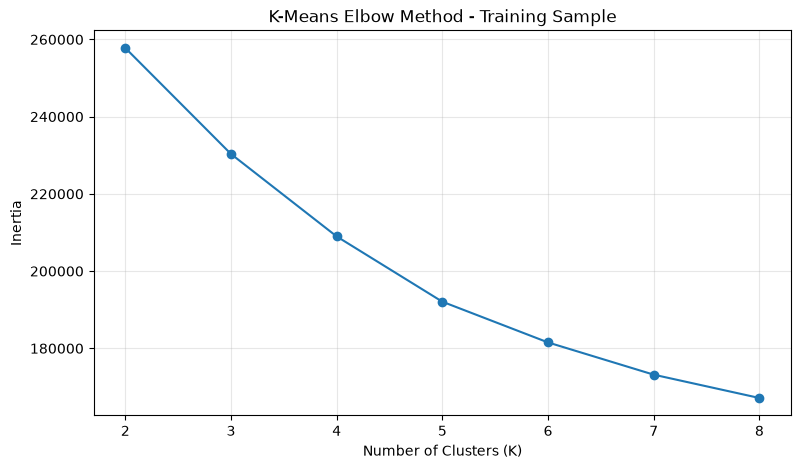

In [123]:

#  K-Means Elbow Method

from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt

k_values = range(2, 9)
inertia_values = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        random_state=42
    )

    model.fit(X_train_sample)

    inertia_values.append(model.inertia_)

    print(
        f"K = {k}, Inertia = {model.inertia_:,.2f}"
    )

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method - Training Sample")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()


**Observation:** K-Means clustering was evaluated for K values from 2 to 8 using a representative sample of 50,000 training borrowers. Inertia decreased consistently from 257,774.81 at K = 2 to 167,138.15 at K = 8. The rate of improvement began to slow around K = 5–6, suggesting diminishing returns from additional clusters. Since the elbow is not sharply defined, K = 5 is treated as a preliminary candidate rather than the final selection. Further evaluation using silhouette scores and cluster interpretability is required.

In [124]:

#Compare silhouette scores for candidate K values

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

silhouette_results = []

for k in [4, 5, 6]:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        random_state=42
    )

    labels = model.fit_predict(X_train_sample)

    score = silhouette_score(
        X_train_sample,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette_Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(
    silhouette_df.round(4)
)


,K,Inertia,Silhouette_Score
0,4,208976.4263,0.1449
1,5,192071.6468,0.1393
2,6,181523.2364,0.1364


**Observation:** Silhouette analysis was performed for K = 4, 5 and 6 using a reproducible sample of 3,000 borrowers. K = 4 achieved the highest silhouette score of 0.1449, followed by K = 5 at 0.1393 and K = 6 at 0.1364. All scores were positive but relatively low, indicating limited separation between borrower groups. Although K = 4 currently performs best on silhouette score, the differences are small, and the final number of clusters will be determined after examining cluster sizes, borrower characteristics and stability.

In [125]:

# Compare cluster sizes for candidate K values

from sklearn.cluster import KMeans
import pandas as pd

cluster_size_results = []

for k in [4, 5, 6]:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        random_state=42
    )

    labels = model.fit_predict(X_train_sample)

    cluster_counts = pd.Series(labels).value_counts().sort_index()

    for cluster_id, count in cluster_counts.items():

        cluster_size_results.append({
            "K": k,
            "Cluster": cluster_id,
            "Borrowers": count,
            "Percentage": count / len(X_train_sample) * 100
        })

cluster_size_df = pd.DataFrame(cluster_size_results)

display(
    cluster_size_df.round(2)
)

print("\nSmallest cluster percentage by K:")
display(
    cluster_size_df.groupby("K")["Percentage"]
    .min()
    .round(2)
)


,K,Cluster,Borrowers,Percentage
0,4,0,6092,12.18
1,4,1,16481,32.96
2,4,2,16272,32.54
3,4,3,11155,22.31
4,5,0,5310,10.62
5,5,1,12608,25.22
6,5,2,9593,19.19
7,5,3,10903,21.81
8,5,4,11586,23.17
9,6,0,10022,20.04



Smallest cluster percentage by K:


K
4    12.18
5    10.62
6     9.66
Name: Percentage, dtype: float64

**Observation:** Cluster-size analysis was conducted for K = 4, 5 and 6. The smallest clusters represented 12.18%, 10.62% and 9.66% of the training sample, respectively. No extremely small clusters were identified. K = 5 and K = 6 produced more evenly distributed cluster sizes than K = 4. All three configurations remain suitable for further evaluation, with final selection dependent on borrower characteristics, separation, stability and business interpretability.

In [126]:

# Profile K=4 and K=5 borrower segments

from sklearn.cluster import KMeans
import pandas as pd

profile_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "Employment_Years_Imputed"
]

for k in [4, 5]:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        random_state=42
    )

    labels = model.fit_predict(X_train_sample)

    borrower_profile = train_df.loc[
        X_train_sample.index,
        profile_features
    ].copy()

    borrower_profile["Cluster"] = labels

    cluster_summary = borrower_profile.groupby(
        "Cluster"
    ).agg(
        Borrowers=("revenue", "size"),
        Avg_Income=("revenue", "mean"),
        Median_Income=("revenue", "median"),
        Avg_DTI=("dti_n", "mean"),
        Median_DTI=("dti_n", "median"),
        Avg_Loan=("loan_amnt", "mean"),
        Avg_FICO=("fico_n", "mean"),
        Avg_Employment_Years=(
            "Employment_Years_Imputed", "mean"
        )
    )

    cluster_summary["Percentage"] = (
        cluster_summary["Borrowers"]
        / len(borrower_profile) * 100
    )

    print(f"\nK = {k} - Borrower Profile")

    display(
        cluster_summary.round(2)
    )



K = 4 - Borrower Profile


,Borrowers,Avg_Income,Median_Income,Avg_DTI,Median_DTI,Avg_Loan,Avg_FICO,Avg_Employment_Years,Percentage
Cluster,,,,,,,,,
0,6092,76123.62,70000.0,13.70,12.93,13402.33,756.49,6.14,12.18
1,16481,50913.32,46101.0,18.34,17.90,9850.82,685.84,2.68,32.96
2,16272,63641.40,60000.0,19.94,19.75,11584.63,685.61,8.99,32.54
3,11155,125955.38,105000.0,16.71,16.14,25609.42,697.54,6.32,22.31



K = 5 - Borrower Profile


,Borrowers,Avg_Income,Median_Income,Avg_DTI,Median_DTI,Avg_Loan,Avg_FICO,Avg_Employment_Years,Percentage
Cluster,,,,,,,,,
0,5310,76409.87,70000.0,13.96,13.58,13733.16,760.96,6.12,10.62
1,12608,55750.40,50000.0,14.77,14.92,9980.96,686.27,2.26,25.22
2,9593,126702.86,105000.0,17.80,17.67,27014.15,699.78,6.41,19.19
3,10903,49056.27,46560.0,28.19,27.97,11587.93,688.88,6.59,21.81
4,11586,76341.64,70000.0,13.65,13.83,11559.11,684.64,8.98,23.17


**Observation:** Borrower profiling showed that K = 5 produced five interpretable segments distinguished by credit score, employment duration, loan amount, income and debt-to-income ratio. Cluster 0 had the highest average FICO score (760.96), Cluster 2 had the highest average income (126,702.86) and loan amount (27,014.15), and Cluster 3 had the highest average DTI (28.19). Cluster 4 was characterized by longer employment duration (8.98 years) and lower DTI (13.65). Compared with K = 4, the five-cluster solution provided clearer differentiation of debt burden. K = 5 is retained as a preliminary business-oriented candidate pending further validation.

In [127]:

# Observed default rates for K = 5 clusters

from sklearn.cluster import KMeans
import pandas as pd

k5_model = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=5,
    random_state=42
)

k5_labels = k5_model.fit_predict(X_train_sample)

risk_profile = train_df.loc[
    X_train_sample.index,
    ["Default"]
].copy()

risk_profile["Cluster"] = k5_labels

cluster_risk_summary = risk_profile.groupby(
    "Cluster"
).agg(
    Borrowers=("Default", "size"),
    Defaults=("Default", "sum"),
    Default_Rate=("Default", "mean")
)

cluster_risk_summary["Default_Rate_%"] = (
    cluster_risk_summary["Default_Rate"] * 100
)

cluster_risk_summary["Portfolio_Share_%"] = (
    cluster_risk_summary["Borrowers"]
    / len(risk_profile) * 100
)

display(
    cluster_risk_summary[
        [
            "Borrowers",
            "Defaults",
            "Default_Rate_%",
            "Portfolio_Share_%"
        ]
    ].round(2)
)

print("\nOverall sample default rate:")
print(
    round(risk_profile["Default"].mean() * 100, 2),
    "%"
)


,Borrowers,Defaults,Default_Rate_%,Portfolio_Share_%
Cluster,,,,
0,5310,440,8.29,10.62
1,12608,2305,18.28,25.22
2,9593,1886,19.66,19.19
3,10903,2704,24.80,21.81
4,11586,1894,16.35,23.17



Overall sample default rate:
18.46 %


**Observation:** Post-clustering risk profiling revealed substantial variation in historical default rates across the five borrower segments. Cluster 3 recorded the highest default rate (24.80%) and the largest number of defaults (2,704), while Cluster 0 recorded the lowest default rate (8.29%). The highest-DTI segment also exhibited the highest observed default rate, and the highest-FICO segment exhibited the lowest. The overall sample default rate was 18.46%. These results suggest that K-Means segmentation captures meaningful differences in historical borrower outcomes, although temporal validation is necessary before concluding that these patterns generalize.

In [128]:

# Validate K=5 cluster risk patterns on 2016 data

val_cluster_labels = k5_model.predict(X_val_final)

val_risk_profile = val_df[["Default"]].copy()

val_risk_profile["Cluster"] = val_cluster_labels

val_cluster_summary = val_risk_profile.groupby(
    "Cluster"
).agg(
    Borrowers=("Default", "size"),
    Defaults=("Default", "sum"),
    Default_Rate=("Default", "mean")
)

val_cluster_summary["Default_Rate_%"] = (
    val_cluster_summary["Default_Rate"] * 100
)

val_cluster_summary["Portfolio_Share_%"] = (
    val_cluster_summary["Borrowers"]
    / len(val_risk_profile) * 100
)

print("2016 Validation Cluster Risk Profile:")

display(
    val_cluster_summary[
        [
            "Borrowers",
            "Defaults",
            "Default_Rate_%",
            "Portfolio_Share_%"
        ]
    ].round(2)
)

print("\nOverall validation default rate:")
print(
    round(val_risk_profile["Default"].mean() * 100, 2),
    "%"
)

print("\nTraining sample default rate:")
print(
    round(risk_profile["Default"].mean() * 100, 2),
    "%"
)


2016 Validation Cluster Risk Profile:


,Borrowers,Defaults,Default_Rate_%,Portfolio_Share_%
Cluster,,,,
0,31378,3208,10.22,10.71
1,69026,16299,23.61,23.55
2,61437,15160,24.68,20.96
3,66532,20721,31.14,22.70
4,64684,12841,19.85,22.07



Overall validation default rate:
23.28 %

Training sample default rate:
18.46 %


**Observation:** The K = 5 clustering model was applied to the 2016 validation dataset without retraining. Cluster 3 retained the highest observed default rate (31.14%), while Cluster 0 retained the lowest (10.22%). The ranking of all five clusters remained unchanged between training and validation. Cluster population shares were also relatively consistent, with a maximum change of approximately 1.77 percentage points. However, the overall observed default rate increased from 18.46% to 23.28%, indicating a cohort-level difference requiring further investigation. These findings support preliminary temporal consistency in risk ordering but do not establish predictive performance or clustering stability under retraining.

In [129]:

#Compare relative default rates across periods

train_overall_rate = risk_profile["Default"].mean()
val_overall_rate = val_risk_profile["Default"].mean()

relative_risk_comparison = pd.DataFrame({
    "Train_Default_%": (
        cluster_risk_summary["Default_Rate"] * 100
    ),
    "Validation_Default_%": (
        val_cluster_summary["Default_Rate"] * 100
    ),
    "Train_Relative_Index": (
        cluster_risk_summary["Default_Rate"]
        / train_overall_rate
    ),
    "Validation_Relative_Index": (
        val_cluster_summary["Default_Rate"]
        / val_overall_rate
    )
})

relative_risk_comparison["Index_Change"] = (
    relative_risk_comparison["Validation_Relative_Index"]
    - relative_risk_comparison["Train_Relative_Index"]
)

display(relative_risk_comparison.round(3))


,Train_Default_%,Validation_Default_%,Train_Relative_Index,Validation_Relative_Index,Index_Change
Cluster,,,,,
0,8.286,10.224,0.449,0.439,-0.010
1,18.282,23.613,0.990,1.014,0.024
2,19.660,24.676,1.065,1.060,-0.005
3,24.801,31.144,1.344,1.338,-0.006
4,16.347,19.852,0.886,0.853,-0.033


**Observation:** Relative default indices were calculated by dividing each cluster's observed default rate by the corresponding period's overall default rate. Cluster 3 maintained the highest index (1.344 in training and 1.338 in validation), while Cluster 0 maintained the lowest (0.449 and 0.439). Index changes were small across all five segments, ranging from −0.033 to +0.024. These findings indicate consistency in relative historical default patterns despite an increase in overall observed default rates. Further assessment of loan issue-year distributions and outcome comparability is required before drawing conclusions about prospective risk performance.

In [130]:

# Audit default rates by loan issue year

import pandas as pd

yearly_default_summary = (
    df_split
    .assign(Issue_Year=df_split["Issue_Date"].dt.year)
    .groupby("Issue_Year")
    .agg(
        Borrowers=("Default", "size"),
        Defaults=("Default", "sum"),
        Default_Rate=("Default", "mean")
    )
)

yearly_default_summary["Default_Rate_%"] = (
    yearly_default_summary["Default_Rate"] * 100
)

yearly_default_summary["Dataset"] = [
    "Train" if year <= 2015
    else "Validation" if year == 2016
    else "Test"
    for year in yearly_default_summary.index
]

display(
    yearly_default_summary[
        ["Dataset", "Borrowers", "Defaults", "Default_Rate_%"]
    ].round(2)
)


,Dataset,Borrowers,Defaults,Default_Rate_%
Issue_Year,,,,
2007,Train,599,158,26.38
2008,Train,2393,496,20.73
2009,Train,5281,723,13.69
2010,Train,12537,1757,14.01
2011,Train,21721,3297,15.18
2012,Train,53367,8644,16.20
2013,Train,134804,21024,15.60
2014,Train,223102,41161,18.45
2015,Train,375543,75802,20.18


**Observation:** Annual default-rate analysis showed variation across loan issuance cohorts. Default rates increased from 15.60% in 2013 to 23.28% in 2016, remained similar at 23.13% in 2017, and declined to 15.75% in 2018. The decline in 2018 may reflect changes in borrower composition, lending conditions, loan maturity or dataset coverage. Since default timing and observation-window information have not yet been verified, the annual differences should be interpreted as historical outcome patterns rather than conclusive evidence of changes in underlying credit risk.

In [131]:

# Compare cluster distributions across periods

import pandas as pd

test_cluster_labels = k5_model.predict(X_test_final)

train_cluster_share = (
    pd.Series(k5_labels)
    .value_counts(normalize=True)
    .sort_index() * 100
)

val_cluster_share = (
    pd.Series(val_cluster_labels)
    .value_counts(normalize=True)
    .sort_index() * 100
)

test_cluster_share = (
    pd.Series(test_cluster_labels)
    .value_counts(normalize=True)
    .sort_index() * 100
)

cluster_distribution_comparison = pd.DataFrame({
    "Train_Sample_%": train_cluster_share,
    "Validation_2016_%": val_cluster_share,
    "Test_2017_2018_%": test_cluster_share
})

cluster_distribution_comparison.index.name = "Cluster"

cluster_distribution_comparison["Test_vs_Train_pp"] = (
    cluster_distribution_comparison["Test_2017_2018_%"]
    - cluster_distribution_comparison["Train_Sample_%"]
)

display(
    cluster_distribution_comparison.round(2)
)

print("\nMaximum absolute test-vs-train change:")
print(
    round(
        cluster_distribution_comparison["Test_vs_Train_pp"]
        .abs()
        .max(),
        2
    ),
    "percentage points"
)


,Train_Sample_%,Validation_2016_%,Test_2017_2018_%,Test_vs_Train_pp
Cluster,,,,
0,10.62,10.71,15.49,4.87
1,25.22,23.55,22.71,-2.51
2,19.19,20.96,21.48,2.29
3,21.81,22.70,19.20,-2.60
4,23.17,22.07,21.12,-2.05



Maximum absolute test-vs-train change:
4.87 percentage points


**Observation:** The training-fitted K = 5 model was applied to the 2017–2018 test dataset without retraining. All five clusters remained represented, with portfolio shares ranging from 15.49% to 22.71%. Cluster 0 experienced the largest population-share increase, from 10.62% in training to 15.49% in testing (+4.87 percentage points). Cluster 3 declined from 21.81% to 19.20%. These changes suggest a shift in borrower composition over time but do not independently establish model instability or deterioration. Further analysis of borrower characteristics within each test-period cluster is required.

In [132]:

# Compare cluster characteristics across periods

import pandas as pd

def create_period_profile(data, indices, labels, period):

    profile = data.loc[
        indices,
        [
            "fico_n",
            "DTI_IQR_Final",
            "loan_amnt",
            "Employment_Years_Imputed"
        ]
    ].copy()

    profile["Cluster"] = labels

    summary = profile.groupby("Cluster").agg(
        Avg_FICO=("fico_n", "mean"),
        Avg_DTI=("DTI_IQR_Final", "mean"),
        Avg_Loan=("loan_amnt", "mean"),
        Avg_Employment=("Employment_Years_Imputed", "mean")
    )

    summary["Period"] = period

    return summary.reset_index()


train_period_profile = create_period_profile(
    train_df,
    X_train_sample.index,
    k5_labels,
    "Train"
)

val_period_profile = create_period_profile(
    val_df,
    X_val_final.index,
    val_cluster_labels,
    "Validation"
)

test_period_profile = create_period_profile(
    test_df,
    X_test_final.index,
    test_cluster_labels,
    "Test"
)

period_profile_comparison = pd.concat(
    [
        train_period_profile,
        val_period_profile,
        test_period_profile
    ],
    ignore_index=True
)

display(
    period_profile_comparison.sort_values(
        ["Cluster", "Period"]
    ).round(2)
)


,Cluster,Avg_FICO,Avg_DTI,Avg_Loan,Avg_Employment,Period
10,0,765.01,15.14,12543.13,5.99,Test
0,0,760.96,13.96,13733.16,6.12,Train
5,0,762.76,15.10,13417.13,6.15,Validation
11,1,688.31,14.56,9205.64,2.28,Test
1,1,686.27,14.77,9980.96,2.26,Train
6,1,686.22,15.02,9747.61,2.25,Validation
12,2,701.48,18.78,28375.05,6.04,Test
2,2,699.78,17.80,27014.15,6.41,Train
7,2,698.04,18.44,27452.86,6.36,Validation
13,3,693.45,29.30,10929.87,6.34,Test


**Observation:** The K = 5 model maintained consistent borrower profiles across training, validation and test periods. Cluster 0 retained the highest average FICO score, Cluster 1 retained the shortest average employment duration, Cluster 2 retained the largest average loan amount, Cluster 3 retained the highest average DTI, and Cluster 4 retained the longest average employment duration. Some financial metrics changed across periods, but the defining segment characteristics remained recognizable. These findings support temporal consistency in cluster interpretation, although they do not establish stability under model retraining.

In [133]:

# Analyze categorical characteristics by cluster

import pandas as pd

categorical_profile = train_df.loc[
    X_train_sample.index,
    ["home_ownership_n", "purpose"]
].copy()

categorical_profile["Cluster"] = k5_labels

for feature in ["home_ownership_n", "purpose"]:

    print(f"\n{feature} - Percentage distribution by cluster")

    distribution = pd.crosstab(
        categorical_profile["Cluster"],
        categorical_profile[feature],
        normalize="index"
    ) * 100

    display(distribution.round(2))

    print(f"\nMost common {feature} in each cluster:")

    top_category = distribution.idxmax(axis=1)
    top_percentage = distribution.max(axis=1)

    summary = pd.DataFrame({
        "Most_Common_Category": top_category,
        "Percentage": top_percentage
    })

    display(summary.round(2))



home_ownership_n - Percentage distribution by cluster


home_ownership_n,MORTGAGE,OTHER,OWN,RENT
Cluster,,,,
0,60.70,0.04,10.55,28.72
1,27.97,0.06,8.65,63.32
2,68.52,0.01,7.89,23.58
3,41.73,0.03,13.66,44.58
4,59.36,0.00,8.54,32.11



Most common home_ownership_n in each cluster:


,Most_Common_Category,Percentage
Cluster,,
0,MORTGAGE,60.70
1,RENT,63.32
2,MORTGAGE,68.52
3,RENT,44.58
4,MORTGAGE,59.36



purpose - Percentage distribution by cluster


purpose,car,credit_card,debt_consolidation,educational,home_improvement,house,major_purchase,medical,moving,other,renewable_energy,small_business,vacation,wedding
Cluster,,,,,,,,,,,,,,
0,2.35,19.42,50.87,0.08,10.17,0.81,4.67,1.39,0.64,6.20,0.09,2.22,0.68,0.41
1,1.78,24.71,55.39,0.10,3.76,0.56,2.40,1.13,1.20,6.35,0.12,1.22,0.73,0.57
2,0.28,24.68,63.69,0.00,5.78,0.45,1.14,0.28,0.19,2.07,0.02,1.25,0.04,0.13
3,0.71,21.97,63.89,0.01,4.10,0.11,1.42,1.08,0.37,5.14,0.04,0.50,0.59,0.08
4,0.92,21.86,57.32,0.02,7.45,0.36,2.24,1.17,0.47,5.89,0.09,1.34,0.67,0.19



Most common purpose in each cluster:


,Most_Common_Category,Percentage
Cluster,,
0,debt_consolidation,50.87
1,debt_consolidation,55.39
2,debt_consolidation,63.69
3,debt_consolidation,63.89
4,debt_consolidation,57.32


**Observation:** Categorical profiling of the five borrower segments revealed meaningful differences in home-ownership composition. Cluster 1 had the highest renter proportion (63.32%), while Cluster 2 had the highest mortgage proportion (68.52%). Cluster 3 showed a more balanced distribution between renting and mortgage ownership. Debt consolidation was the most common loan purpose across all five clusters, ranging from 50.87% in Cluster 0 to 63.89% in Cluster 3. Cluster 0 had the highest home-improvement loan share (10.17%). These findings improve business interpretation of the borrower segments, although the most common categories must be compared with overall portfolio proportions to determine whether they are unusually concentrated.

In [134]:

# Category concentration (lift) by cluster

import pandas as pd

categorical_profile = train_df.loc[
    X_train_sample.index,
    ["home_ownership_n", "purpose"]
].copy()

categorical_profile["Cluster"] = k5_labels

for feature in ["home_ownership_n", "purpose"]:

    overall_share = (
        categorical_profile[feature]
        .value_counts(normalize=True)
    )

    cluster_share = pd.crosstab(
        categorical_profile["Cluster"],
        categorical_profile[feature],
        normalize="index"
    )

    category_lift = cluster_share.div(
        overall_share,
        axis=1
    )

    print(f"\n{feature} - Category Lift")

    display(category_lift.round(2))

    print("\nMost overrepresented category per cluster:")

    top_lift = pd.DataFrame({
        "Category": category_lift.idxmax(axis=1),
        "Lift": category_lift.max(axis=1)
    })

    display(top_lift.round(2))



home_ownership_n - Category Lift


home_ownership_n,MORTGAGE,OTHER,OWN,RENT
Cluster,,,,
0,1.23,1.45,1.08,0.71
1,0.57,2.14,0.89,1.56
2,1.38,0.40,0.81,0.58
3,0.84,1.06,1.40,1.10
4,1.20,0.00,0.87,0.79



Most overrepresented category per cluster:


,Category,Lift
Cluster,,
0,OTHER,1.45
1,OTHER,2.14
2,MORTGAGE,1.38
3,OWN,1.40
4,MORTGAGE,1.20



purpose - Category Lift


purpose,car,credit_card,debt_consolidation,educational,home_improvement,house,major_purchase,medical,moving,other,renewable_energy,small_business,vacation,wedding
Cluster,,,,,,,,,,,,,,
0,2.10,0.85,0.87,1.88,1.77,1.92,2.17,1.40,1.08,1.21,1.27,1.85,1.24,1.51
1,1.59,1.08,0.94,2.58,0.65,1.33,1.12,1.13,2.02,1.23,1.61,1.01,1.33,2.08
2,0.25,1.08,1.08,0.00,1.00,1.06,0.53,0.28,0.32,0.40,0.28,1.04,0.08,0.46
3,0.63,0.96,1.09,0.23,0.71,0.26,0.66,1.09,0.62,1.00,0.50,0.42,1.07,0.30
4,0.82,0.96,0.97,0.43,1.29,0.86,1.04,1.18,0.78,1.15,1.28,1.11,1.23,0.69



Most overrepresented category per cluster:


,Category,Lift
Cluster,,
0,major_purchase,2.17
1,educational,2.58
2,debt_consolidation,1.08
3,medical,1.09
4,home_improvement,1.29


**Observation:** Category lift analysis revealed that some high-lift categories were extremely rare and therefore unsuitable as primary cluster descriptors. For example, OTHER home ownership had a lift of 2.14 in Cluster 1 but represented only 0.06% of its borrowers. RENT was more meaningful, representing 63.32% of Cluster 1 with a lift of 1.56. Cluster 2 showed mortgage overrepresentation (lift 1.38), while Cluster 3 showed ownership overrepresentation (lift 1.40). Debt consolidation was common across all clusters but only mildly overrepresented in Clusters 2 and 3. Category lift should therefore be interpreted alongside actual category prevalence and borrower counts.

In [135]:

#  Examine category lift alongside borrower counts

import pandas as pd

for feature in ["home_ownership_n", "purpose"]:

    counts = pd.crosstab(
        categorical_profile["Cluster"],
        categorical_profile[feature]
    )

    cluster_percentages = (
        counts.div(counts.sum(axis=1), axis=0) * 100
    )

    overall_percentages = (
        categorical_profile[feature]
        .value_counts(normalize=True) * 100
    )

    lift = cluster_percentages.div(
        overall_percentages,
        axis=1
    )

    results = pd.DataFrame({
        "Count": counts.stack(),
        "Cluster_Percentage": cluster_percentages.stack(),
        "Lift": lift.stack()
    }).reset_index()

    results.columns = [
        "Cluster",
        "Category",
        "Count",
        "Cluster_Percentage",
        "Lift"
    ]

    # Focus on categories represented by at least
    # 1% of borrowers in their cluster
    meaningful_results = results[
        results["Cluster_Percentage"] >= 1
    ]

    top_categories = (
        meaningful_results
        .sort_values(
            ["Cluster", "Lift"],
            ascending=[True, False]
        )
        .groupby("Cluster")
        .head(3)
    )

    print(f"\n{feature}: Top 3 category lifts (minimum 1% share)")

    display(
        top_categories.round(2)
    )



home_ownership_n: Top 3 category lifts (minimum 1% share)


,Cluster,Category,Count,Cluster_Percentage,Lift
0,0,MORTGAGE,3223,60.70,1.23
2,0,OWN,560,10.55,1.08
3,0,RENT,1525,28.72,0.71
7,1,RENT,7983,63.32,1.56
6,1,OWN,1091,8.65,0.89
4,1,MORTGAGE,3527,27.97,0.57
8,2,MORTGAGE,6573,68.52,1.38
10,2,OWN,757,7.89,0.81
11,2,RENT,2262,23.58,0.58
14,3,OWN,1489,13.66,1.40



purpose: Top 3 category lifts (minimum 1% share)


,Cluster,Category,Count,Cluster_Percentage,Lift
6,0,major_purchase,248,4.67,2.17
0,0,car,125,2.35,2.10
11,0,small_business,118,2.22,1.85
22,1,moving,151,1.20,2.02
14,1,car,224,1.78,1.59
23,1,other,800,6.35,1.23
30,2,debt_consolidation,6110,63.69,1.08
29,2,credit_card,2368,24.68,1.08
39,2,small_business,120,1.25,1.04
49,3,medical,118,1.08,1.09


**Observation:** Applying a minimum 1% within-cluster share threshold removed rare categories that previously produced disproportionately high lift values. Home-ownership analysis confirmed that Cluster 1 was renter-heavy (63.32%, lift 1.56), while Clusters 0, 2 and 4 showed mortgage overrepresentation. Cluster 3 showed the highest relative concentration of OWN borrowers (lift 1.40), although renting remained its most common housing category. Loan-purpose analysis showed that major purchases and car loans were overrepresented in Cluster 0, moving loans in Cluster 1, and home-improvement loans in Cluster 4. Debt consolidation remained common across all segments but was only mildly overrepresented in Clusters 2 and 3. Combining lift, category share and borrower count improved the interpretability of the five-cluster solution.

In [136]:

# Compare K-Means stability across random seeds

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

X_stability = X_train_sample.sample(
    n=10000,
    random_state=42
)

seeds = [10, 21, 42]

stability_results = []

for k in [4, 5]:

    labels_by_seed = {}

    for seed in seeds:

        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=5,
            random_state=seed
        )

        labels_by_seed[seed] = model.fit_predict(
            X_stability
        )

    for i in range(len(seeds)):

        for j in range(i + 1, len(seeds)):

            seed_a = seeds[i]
            seed_b = seeds[j]

            ari = adjusted_rand_score(
                labels_by_seed[seed_a],
                labels_by_seed[seed_b]
            )

            stability_results.append({
                "K": k,
                "Seed_A": seed_a,
                "Seed_B": seed_b,
                "ARI": ari
            })

stability_df = pd.DataFrame(stability_results)

print("K-Means Stability Results:")
display(stability_df.round(4))

print("\nAverage ARI by K:")
display(
    stability_df.groupby("K")["ARI"]
    .agg(["mean", "min", "max"])
    .round(4)
)


K-Means Stability Results:


,K,Seed_A,Seed_B,ARI
0,4,10,21,0.9727
1,4,10,42,0.9685
2,4,21,42,0.9892
3,5,10,21,0.9991
4,5,10,42,0.9880
5,5,21,42,0.9883



Average ARI by K:


,mean,min,max
K,,,
4,0.9768,0.9685,0.9892
5,0.9918,0.9880,0.9991


**Observation:** Random-initialization stability was evaluated for K = 4 and K = 5 using Adjusted Rand Index on a fixed sample of 10,000 training borrowers. Both solutions demonstrated high consistency across three random seeds. K = 5 achieved a higher average ARI (0.9918) than K = 4 (0.9768), with a minimum ARI of 0.9880. These results suggest that the five-cluster solution is relatively insensitive to the tested random initializations. However, this experiment does not establish robustness across different borrower samples, and the low Silhouette Scores indicate limited geometric separation between clusters.

In [137]:

# K-Means stability across borrower samples

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Create two independently drawn training samples
sample_a = X_train_sample.sample(
    n=10000,
    random_state=10
)

sample_b = X_train_sample.sample(
    n=10000,
    random_state=21
)

# Fixed reference set for comparing assignments
reference_sample = X_train_sample.sample(
    n=5000,
    random_state=99
)

model_a = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=5,
    random_state=42
)

model_b = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=5,
    random_state=42
)

model_a.fit(sample_a)
model_b.fit(sample_b)

reference_labels_a = model_a.predict(
    reference_sample
)

reference_labels_b = model_b.predict(
    reference_sample
)

sample_stability_ari = adjusted_rand_score(
    reference_labels_a,
    reference_labels_b
)

print("Sample A size:", len(sample_a))
print("Sample B size:", len(sample_b))

print(
    "Shared borrowers between training samples:",
    len(sample_a.index.intersection(sample_b.index))
)

print(
    "\nARI across different borrower samples:",
    round(sample_stability_ari, 4)
)


Sample A size: 10000
Sample B size: 10000
Shared borrowers between training samples: 2021

ARI across different borrower samples: 0.9216


**Observation:** Sample-based stability testing was performed by fitting two K = 5 models on different 10,000-borrower samples and comparing their predictions on a common 5,000-borrower reference set. The training samples shared 2,021 borrowers. The resulting ARI was 0.9216, indicating strong agreement between the two clustering solutions. This was lower than the average initialization-stability ARI of 0.9918, suggesting some sensitivity to training-sample composition. However, the experiments assess different sources of variation and should not be treated as directly equivalent. Further repeated-sample comparisons are recommended before final model selection.

In [138]:

#Compare sample stability for K=4 and K=5

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

sample_stability_results = []

for k in [4, 5]:

    model_a = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        random_state=42
    )

    model_b = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        random_state=42
    )

    model_a.fit(sample_a)
    model_b.fit(sample_b)

    labels_a = model_a.predict(reference_sample)
    labels_b = model_b.predict(reference_sample)

    ari = adjusted_rand_score(
        labels_a,
        labels_b
    )

    sample_stability_results.append({
        "K": k,
        "Sample_Stability_ARI": ari
    })

sample_stability_comparison = pd.DataFrame(
    sample_stability_results
)

display(sample_stability_comparison.round(4))


,K,Sample_Stability_ARI
0,4,0.9636
1,5,0.9216


**Observation:** Sample-based stability comparison showed that K = 4 achieved a higher ARI (0.9636) than K = 5 (0.9216), indicating greater consistency across the two training samples examined. In contrast, K = 5 achieved a higher average initialization-stability ARI (0.9918 versus 0.9768). Both clustering solutions showed strong stability, but their relative performance depended on the type of variation tested. K = 5 remains the preferred provisional model because of its more detailed borrower profiles, while K = 4 remains a viable alternative. Repeated sample-based testing is needed to assess whether the stability difference is consistent.

In [139]:

#  Repeated sample stability comparison

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

sample_pairs = [
    (10, 21),
    (30, 41),
    (50, 61)
]

repeated_stability_results = []

for k in [4, 5]:

    for seed_a, seed_b in sample_pairs:

        train_sample_a = X_train_sample.sample(
            n=10000,
            random_state=seed_a
        )

        train_sample_b = X_train_sample.sample(
            n=10000,
            random_state=seed_b
        )

        model_a = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=5,
            random_state=42
        )

        model_b = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=5,
            random_state=42
        )

        model_a.fit(train_sample_a)
        model_b.fit(train_sample_b)

        labels_a = model_a.predict(reference_sample)
        labels_b = model_b.predict(reference_sample)

        ari = adjusted_rand_score(
            labels_a,
            labels_b
        )

        repeated_stability_results.append({
            "K": k,
            "Sample_Pair": f"{seed_a} vs {seed_b}",
            "ARI": ari
        })

repeated_stability_df = pd.DataFrame(
    repeated_stability_results
)

print("Repeated Sample Stability Results:")
display(repeated_stability_df.round(4))

print("\nStability Summary:")
display(
    repeated_stability_df.groupby("K")["ARI"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)


Repeated Sample Stability Results:


,K,Sample_Pair,ARI
0,4,10 vs 21,0.9636
1,4,30 vs 41,0.7957
2,4,50 vs 61,0.8886
3,5,10 vs 21,0.9216
4,5,30 vs 41,0.7869
5,5,50 vs 61,0.8347



Stability Summary:


,mean,std,min,max
K,,,,
4,0.8826,0.0841,0.7957,0.9636
5,0.8477,0.0683,0.7869,0.9216


**Observation:** Repeated sample-based stability testing showed that K = 4 achieved a higher average ARI (0.8826) than K = 5 (0.8477) across three training-sample pairs. K = 4 outperformed K = 5 in all three comparisons. However, K = 5 had a slightly lower standard deviation (0.0683 versus 0.0841). Both solutions demonstrated sensitivity to borrower-sample composition, with minimum ARI values below 0.80. These findings favor K = 4 for average sample stability, while K = 5 remains a candidate because of its more detailed business segmentation. Further comparison of historical default patterns is required before final model selection

In [140]:

# Compare historical default patterns for K=4 and K=5

from sklearn.cluster import KMeans
import pandas as pd

risk_comparison_results = []

for k in [4, 5]:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        random_state=42
    )

    train_labels = model.fit_predict(X_train_sample)
    validation_labels = model.predict(X_val_final)

    for period, data, indices, labels in [
        ("Train", train_df, X_train_sample.index, train_labels),
        ("Validation", val_df, X_val_final.index, validation_labels)
    ]:

        profile = data.loc[indices, ["Default"]].copy()
        profile["Cluster"] = labels

        summary = profile.groupby("Cluster").agg(
            Borrowers=("Default", "size"),
            Default_Rate=("Default", "mean")
        )

        overall_rate = profile["Default"].mean()

        for cluster, row in summary.iterrows():

            risk_comparison_results.append({
                "K": k,
                "Period": period,
                "Cluster": cluster,
                "Borrowers": int(row["Borrowers"]),
                "Default_Rate_%": row["Default_Rate"] * 100,
                "Relative_Default_Index": (
                    row["Default_Rate"] / overall_rate
                )
            })

risk_comparison_df = pd.DataFrame(
    risk_comparison_results
)

display(
    risk_comparison_df.sort_values(
        ["K", "Cluster", "Period"]
    ).round(3)
)


,K,Period,Cluster,Borrowers,Default_Rate_%,Relative_Default_Index
0,4,Train,0,6092,8.585,0.465
4,4,Validation,0,35996,10.604,0.455
1,4,Train,1,16481,20.217,1.095
5,4,Validation,1,93118,26.175,1.124
2,4,Train,2,16272,19.942,1.080
6,4,Validation,2,93691,24.435,1.050
3,4,Train,3,11155,19.086,1.034
7,4,Validation,3,70252,24.405,1.048
8,5,Train,0,5310,8.286,0.449
13,5,Validation,0,31378,10.224,0.439


**Observation:** A comparative evaluation of K = 4 and K = 5 showed that both solutions produced differences in historical borrower default rates. K = 5 provided greater differentiation, with validation default rates ranging from 10.22% to 31.14%, compared with 10.60% to 26.18% for K = 4. The five-cluster solution also identified a distinct higher-DTI borrower segment with an elevated observed default rate. Although K = 4 achieved slightly better Silhouette and repeated sample-stability scores, K = 5 was selected as the preferred business-oriented segmentation candidate due to its more detailed borrower profiles and descriptive risk differentiation. This selection remains subject to limitations concerning cluster separation, outcome comparability and independent validation.

In [141]:

#Examine K=5 cluster distribution by test issue year

import pandas as pd

test_year_profile = test_df.loc[
    X_test_final.index,
    ["Issue_Date"]
].copy()

test_year_profile["Cluster"] = test_cluster_labels

test_year_profile["Issue_Year"] = (
    test_year_profile["Issue_Date"].dt.year
)

year_cluster_counts = pd.crosstab(
    test_year_profile["Issue_Year"],
    test_year_profile["Cluster"]
)

year_cluster_percentages = pd.crosstab(
    test_year_profile["Issue_Year"],
    test_year_profile["Cluster"],
    normalize="index"
) * 100

print("Borrower counts by year and cluster:")
display(year_cluster_counts)

print("\nCluster distribution (%) by issue year:")
display(year_cluster_percentages.round(2))

print("\n2018 minus 2017 cluster share (percentage points):")
display(
    (
        year_cluster_percentages.loc[2018]
        - year_cluster_percentages.loc[2017]
    ).round(2)
)


Borrower counts by year and cluster:


Cluster,0,1,2,3,4
Issue_Year,,,,,
2017,23503,39712,35866,33495,36541
2018,11390,11443,12525,9764,11038



Cluster distribution (%) by issue year:


Cluster,0,1,2,3,4
Issue_Year,,,,,
2017,13.90,23.48,21.21,19.81,21.61
2018,20.28,20.38,22.30,17.39,19.65



2018 minus 2017 cluster share (percentage points):


Cluster
0    6.38
1   -3.11
2    1.09
3   -2.42
4   -1.95
dtype: float64

**Observation:** The distribution of borrowers across the five clusters changed between the 2017 and 2018 issue cohorts. Cluster 0 increased from 13.90% to 20.28%, representing the largest increase of 6.38 percentage points. Cluster 1 declined from 23.48% to 20.38%, while Cluster 3 declined from 19.81% to 17.39%. Cluster 2 became the largest segment in 2018, accounting for 22.30% of borrowers. These changes suggest a shift in borrower composition toward the historically lower-default Cluster 0. However, changes in portfolio composition alone cannot explain the observed decline in default rates. Differences in loan maturity, observation periods and within-cluster outcomes must also be considered.

In [142]:

# Compare observed default rates by cluster and issue year

import pandas as pd

test_outcome_profile = test_df.loc[
    X_test_final.index,
    ["Issue_Date", "Default"]
].copy()

test_outcome_profile["Cluster"] = test_cluster_labels

test_outcome_profile["Issue_Year"] = (
    test_outcome_profile["Issue_Date"].dt.year
)

cluster_year_summary = (
    test_outcome_profile
    .groupby(["Issue_Year", "Cluster"])
    .agg(
        Borrowers=("Default", "size"),
        Defaults=("Default", "sum"),
        Default_Rate=("Default", "mean")
    )
    .reset_index()
)

cluster_year_summary["Default_Rate_%"] = (
    cluster_year_summary["Default_Rate"] * 100
)

print("Observed default rates by year and cluster:")
display(
    cluster_year_summary[
        ["Issue_Year", "Cluster", "Borrowers",
         "Defaults", "Default_Rate_%"]
    ].round(2)
)

year_rate_table = cluster_year_summary.pivot(
    index="Cluster",
    columns="Issue_Year",
    values="Default_Rate_%"
)

year_rate_table["Change_2018_minus_2017_pp"] = (
    year_rate_table[2018] - year_rate_table[2017]
)

print("\nYear-wise default-rate comparison:")
display(year_rate_table.round(2))

print("\nOverall observed default rate by year:")
display(
    (
        test_outcome_profile
        .groupby("Issue_Year")["Default"]
        .mean() * 100
    ).round(2)
)


Observed default rates by year and cluster:


,Issue_Year,Cluster,Borrowers,Defaults,Default_Rate_%
0,2017,0,23503,2586,11.00
1,2017,1,39712,9534,24.01
2,2017,2,35866,9581,26.71
3,2017,3,33495,10429,31.14
4,2017,4,36541,6982,19.11
5,2018,0,11390,1059,9.30
6,2018,1,11443,1923,16.81
7,2018,2,12525,2395,19.12
8,2018,3,9764,2113,21.64
9,2018,4,11038,1356,12.28



Year-wise default-rate comparison:


Issue_Year,2017,2018,Change_2018_minus_2017_pp
Cluster,,,
0,11.00,9.30,-1.71
1,24.01,16.81,-7.20
2,26.71,19.12,-7.59
3,31.14,21.64,-9.50
4,19.11,12.28,-6.82



Overall observed default rate by year:


Issue_Year
2017    23.13
2018    15.75
Name: Default, dtype: float64

**Observation:** Test-period analysis showed that observed default rates declined across all five borrower clusters between the 2017 and 2018 issue cohorts. Cluster 3 maintained the highest recorded default rate, declining from 31.14% to 21.64%, while Cluster 0 maintained the lowest rate, declining from 11.00% to 9.30%. The ranking of clusters remained consistent across both years: Cluster 3, Cluster 2, Cluster 1, Cluster 4 and Cluster 0, from highest to lowest observed default rate. The overall portfolio default rate declined from 23.13% to 15.75%. Because default rates decreased within every cluster, changes in borrower composition alone cannot explain the total decline. Differences in loan maturity and observation periods remain important limitations.

In [143]:

#  Decompose the 2017–2018 observed default-rate change

import pandas as pd

counts = pd.crosstab(
    test_outcome_profile["Issue_Year"],
    test_outcome_profile["Cluster"]
)

shares = counts.div(counts.sum(axis=1), axis=0)

rates = test_outcome_profile.pivot_table(
    index="Issue_Year",
    columns="Cluster",
    values="Default",
    aggfunc="mean"
)

w17 = shares.loc[2017]
w18 = shares.loc[2018]

r17 = rates.loc[2017]
r18 = rates.loc[2018]

# Symmetric decomposition: all results in percentage points
composition_effect = (
    (w18 - w17) * ((r17 + r18) / 2)
) * 100

within_cluster_effect = (
    (r18 - r17) * ((w17 + w18) / 2)
) * 100

decomposition = pd.DataFrame({
    "Composition_Effect_pp": composition_effect,
    "Within_Cluster_Effect_pp": within_cluster_effect
})

decomposition["Total_Change_pp"] = (
    decomposition["Composition_Effect_pp"]
    + decomposition["Within_Cluster_Effect_pp"]
)

print("Contribution of each cluster:")
display(decomposition.round(3))

print("\nOverall decomposition:")
display(
    pd.DataFrame({
        "Effect": [
            "Borrower composition",
            "Within-cluster rates",
            "Total observed change"
        ],
        "Percentage_Points": [
            composition_effect.sum(),
            within_cluster_effect.sum(),
            decomposition["Total_Change_pp"].sum()
        ]
    }).round(3)
)

actual_change = (
    test_outcome_profile.loc[
        test_outcome_profile["Issue_Year"] == 2018,
        "Default"
    ].mean()
    -
    test_outcome_profile.loc[
        test_outcome_profile["Issue_Year"] == 2017,
        "Default"
    ].mean()
) * 100

print(
    "\nActual overall change (pp):",
    round(actual_change, 3)
)

print(
    "Decomposition matches actual change:",
    abs(
        decomposition["Total_Change_pp"].sum()
        - actual_change
    ) < 1e-8
)


Contribution of each cluster:


,Composition_Effect_pp,Within_Cluster_Effect_pp,Total_Change_pp
Cluster,,,
0,0.648,-0.291,0.357
1,-0.634,-1.579,-2.213
2,0.251,-1.652,-1.401
3,-0.639,-1.766,-2.404
4,-0.306,-1.408,-1.714



Overall decomposition:


,Effect,Percentage_Points
0,Borrower composition,-0.680
1,Within-cluster rates,-6.696
2,Total observed change,-7.376



Actual overall change (pp): -7.376
Decomposition matches actual change: True


**Observation:** A symmetric rate decomposition was performed to examine the decline in the observed portfolio default rate between the 2017 and 2018 issue cohorts. The total decline of 7.376 percentage points was decomposed into a borrower-composition effect of −0.680 percentage points (approximately 9.2%) and a within-cluster default-rate effect of −6.696 percentage points (approximately 90.8%). Cluster 3 had the largest negative total contribution at −2.404 percentage points. The decomposition exactly reproduced the observed portfolio-level change, confirming arithmetic consistency. These results indicate that within-cluster changes in recorded default rates accounted for most of the observed decline. However, unequal loan maturity and outcome-observation periods prevent a causal interpretation or a conclusion that underlying credit risk necessarily improved.

In [144]:

#  Build consolidated five-cluster business summary

import pandas as pd

# Use original borrower characteristics for interpretation
train_profile = train_df.loc[
    X_train_sample.index,
    ["revenue", "dti_n", "loan_amnt", "fico_n",
     "Employment_Years_Imputed"]
].copy()

train_profile["Cluster"] = k5_labels

segment_summary = train_profile.groupby("Cluster").agg(
    Borrowers=("revenue", "size"),
    Avg_Income=("revenue", "mean"),
    Avg_DTI=("dti_n", "mean"),
    Avg_Loan=("loan_amnt", "mean"),
    Avg_FICO=("fico_n", "mean"),
    Avg_Employment_Years=("Employment_Years_Imputed", "mean")
)

segment_summary["Share_%"] = (
    segment_summary["Borrowers"]
    / len(train_profile) * 100
)

# Historical default rates for each period
for period, data, indices, labels in [
    ("Train", train_df, X_train_sample.index, k5_labels),
    ("Validation", val_df, X_val_final.index, val_cluster_labels),
    ("Test", test_df, X_test_final.index, test_cluster_labels)
]:

    outcome = data.loc[indices, ["Default"]].copy()
    outcome["Cluster"] = labels

    rates = outcome.groupby("Cluster")["Default"].mean() * 100

    segment_summary[f"{period}_Default_%"] = rates

segment_names = {
    0: "Higher-FICO Mortgage-Oriented",
    1: "Shorter-Employment Renters",
    2: "Higher-Income Larger-Loan",
    3: "Higher Debt-Burden",
    4: "Longer-Employment Lower-DTI"
}

segment_summary["Segment_Name"] = (
    segment_summary.index.map(segment_names)
)

segment_summary = segment_summary[
    ["Segment_Name", "Borrowers", "Share_%",
     "Avg_Income", "Avg_DTI", "Avg_Loan",
     "Avg_FICO", "Avg_Employment_Years",
     "Train_Default_%", "Validation_Default_%",
     "Test_Default_%"]
]

print("Final K=5 Borrower Segment Summary:")
display(segment_summary.round(2))


Final K=5 Borrower Segment Summary:


,Segment_Name,Borrowers,Share_%,Avg_Income,Avg_DTI,Avg_Loan,Avg_FICO,Avg_Employment_Years,Train_Default_%,Validation_Default_%,Test_Default_%
Cluster,,,,,,,,,,,
0,Higher-FICO Mortgage-Oriented,5310,10.62,76409.87,13.96,13733.16,760.96,6.12,8.29,10.22,10.45
1,Shorter-Employment Renters,12608,25.22,55750.40,14.77,9980.96,686.27,2.26,18.28,23.61,22.40
2,Higher-Income Larger-Loan,9593,19.19,126702.86,17.80,27014.15,699.78,6.41,19.66,24.68,24.75
3,Higher Debt-Burden,10903,21.81,49056.27,28.19,11587.93,688.88,6.59,24.80,31.14,28.99
4,Longer-Employment Lower-DTI,11586,23.17,76341.64,13.65,11559.11,684.64,8.98,16.35,19.85,17.52


**Observation:** The final K = 5 borrower segmentation identified five interpretable groups with distinct financial and employment characteristics. Cluster 0 had the highest average FICO score (760.96) and consistently recorded the lowest default rates across training (8.29%), validation (10.22%) and test (10.45%). Cluster 3 had the highest average DTI (28.19) and consistently recorded the highest default rates (24.80%, 31.14% and 28.99%, respectively). Cluster 2 contained higher-income borrowers with larger average loan amounts, while Cluster 1 was characterized by shorter employment histories and a higher proportion of renters. Cluster 4 had the longest average employment history and relatively low DTI. The consistent ordering of historical default rates supports the descriptive business relevance of the five segments. However, the pooled test rates combine different issue cohorts and should not be interpreted as equal-horizon future default probabilities.

In [145]:

# Compare cluster default rates with period averages

import pandas as pd

relative_risk_summary = segment_summary[
    ["Segment_Name",
     "Train_Default_%",
     "Validation_Default_%",
     "Test_Default_%"]
].copy()

period_data = {
    "Train": (train_df, X_train_sample.index),
    "Validation": (val_df, X_val_final.index),
    "Test": (test_df, X_test_final.index)
}

for period, (data, indices) in period_data.items():

    overall_default_rate = (
        data.loc[indices, "Default"].mean() * 100
    )

    relative_risk_summary[
        f"{period}_Relative_Index"
    ] = (
        relative_risk_summary[f"{period}_Default_%"]
        / overall_default_rate
    )

print("Relative default index by segment and period:")

display(
    relative_risk_summary[
        ["Segment_Name",
         "Train_Relative_Index",
         "Validation_Relative_Index",
         "Test_Relative_Index"]
    ].round(3)
)

print("\nOverall default rate by period:")

for period, (data, indices) in period_data.items():
    print(
        period,
        round(data.loc[indices, "Default"].mean() * 100, 2),
        "%"
    )


Relative default index by segment and period:


,Segment_Name,Train_Relative_Index,Validation_Relative_Index,Test_Relative_Index
Cluster,,,,
0,Higher-FICO Mortgage-Oriented,0.449,0.439,0.491
1,Shorter-Employment Renters,0.990,1.014,1.052
2,Higher-Income Larger-Loan,1.065,1.060,1.163
3,Higher Debt-Burden,1.344,1.338,1.362
4,Longer-Employment Lower-DTI,0.886,0.853,0.823



Overall default rate by period:
Train 18.46 %
Validation 23.28 %
Test 21.29 %


**Observation:** Relative default indices were calculated to compare each borrower segment's recorded default rate against its corresponding portfolio average. Cluster 0 consistently had the lowest relative index (0.439–0.491), indicating substantially lower observed default rates than the portfolio average. Cluster 3 consistently had the highest relative index (1.338–1.362), while Cluster 4 remained below average and Clusters 1 and 2 remained near or above average. The relative ordering of all five clusters was unchanged across training, validation and test periods. These findings support the descriptive consistency of the segmentation. However, relative indices do not correct for differences in loan maturity or observation periods and should not be interpreted as calibrated future default probabilities.

In [146]:

# Relative default index by test issue year

import pandas as pd

yearly_overall_rate = (
    test_outcome_profile
    .groupby("Issue_Year")["Default"]
    .mean()
)

yearly_cluster_rate = (
    test_outcome_profile
    .groupby(["Issue_Year", "Cluster"])["Default"]
    .mean()
)

yearly_relative_index = (
    yearly_cluster_rate
    .div(yearly_overall_rate, level="Issue_Year")
    .rename("Relative_Default_Index")
    .reset_index()
)

print("Relative default index by issue year and cluster:")

display(
    yearly_relative_index.pivot(
        index="Cluster",
        columns="Issue_Year",
        values="Relative_Default_Index"
    ).round(3)
)

print("\nHighest-to-lowest cluster ranking by year:")

for year, group in yearly_relative_index.groupby("Issue_Year"):

    ranking = group.sort_values(
        "Relative_Default_Index",
        ascending=False
    )["Cluster"].tolist()

    print(year, ":", ranking)


Relative default index by issue year and cluster:


Issue_Year,2017,2018
Cluster,,
0,0.476,0.590
1,1.038,1.067
2,1.155,1.214
3,1.346,1.374
4,0.826,0.780



Highest-to-lowest cluster ranking by year:
2017 : [3, 2, 1, 4, 0]
2018 : [3, 2, 1, 4, 0]


**Observation:** Year-wise relative default index analysis confirmed that the five borrower segments maintained an identical historical default-rate ranking in both the 2017 and 2018 issue cohorts. Cluster 3 consistently recorded the highest relative index (1.346 and 1.374), while Cluster 0 recorded the lowest (0.476 and 0.590). Cluster 4 remained below the portfolio average, while Clusters 1 and 2 remained above it. These results support the consistency of the segmentation's descriptive risk patterns across issue cohorts. Nevertheless, unequal loan follow-up periods and possible outcome-maturity differences limit the interpretation of these indices as future default-risk estimates.

In [147]:

# Default concentration by borrower segment

import pandas as pd

default_concentration = (
    test_outcome_profile
    .groupby("Cluster")
    .agg(
        Borrowers=("Default", "size"),
        Defaults=("Default", "sum"),
        Default_Rate=("Default", "mean")
    )
)

default_concentration["Borrower_Share_%"] = (
    default_concentration["Borrowers"]
    / default_concentration["Borrowers"].sum() * 100
)

default_concentration["Default_Share_%"] = (
    default_concentration["Defaults"]
    / default_concentration["Defaults"].sum() * 100
)

default_concentration["Default_Concentration_Index"] = (
    default_concentration["Default_Share_%"]
    / default_concentration["Borrower_Share_%"]
)

default_concentration["Default_Rate_%"] = (
    default_concentration["Default_Rate"] * 100
)

default_concentration["Segment_Name"] = (
    default_concentration.index.map(segment_names)
)

display(
    default_concentration[
        ["Segment_Name", "Borrowers", "Defaults",
         "Borrower_Share_%", "Default_Share_%",
         "Default_Rate_%",
         "Default_Concentration_Index"]
    ].sort_values(
        "Default_Share_%",
        ascending=False
    ).round(3)
)

print(
    "\nTotal borrowers:",
    default_concentration["Borrowers"].sum()
)

print(
    "Total recorded defaults:",
    default_concentration["Defaults"].sum()
)


,Segment_Name,Borrowers,Defaults,Borrower_Share_%,Default_Share_%,Default_Rate_%,Default_Concentration_Index
Cluster,,,,,,,
3,Higher Debt-Burden,43259,12542,19.203,26.152,28.993,1.362
2,Higher-Income Larger-Loan,48391,11976,21.481,24.972,24.748,1.163
1,Shorter-Employment Renters,51155,11457,22.708,23.890,22.397,1.052
4,Longer-Employment Lower-DTI,47579,8338,21.120,17.386,17.525,0.823
0,Higher-FICO Mortgage-Oriented,34893,3645,15.489,7.600,10.446,0.491



Total borrowers: 225277
Total recorded defaults: 47958


**Observation:** Default concentration analysis of the pooled test portfolio identified 225,277 borrowers and 47,958 recorded defaults. Cluster 3 contributed the largest number of defaults (12,542), representing 26.15% of all recorded defaults despite accounting for only 19.20% of borrowers. It also had the highest observed default rate (28.99%) and concentration index (1.362). Cluster 1 represented the largest borrower segment (22.71%), while Cluster 0 contributed only 7.60% of defaults despite representing 15.49% of borrowers. Clusters 1, 2 and 3 collectively accounted for approximately 75.01% of recorded defaults. These findings highlight the importance of considering both default rates and default volumes when monitoring portfolio segments. Results remain descriptive and are subject to loan-maturity and observation-period limitations.

In [148]:

#  Compare default concentration by issue year

import pandas as pd

yearly_concentration = (
    test_outcome_profile
    .groupby(["Issue_Year", "Cluster"])
    .agg(
        Borrowers=("Default", "size"),
        Defaults=("Default", "sum")
    )
    .reset_index()
)

yearly_concentration["Borrower_Share_%"] = (
    yearly_concentration["Borrowers"]
    / yearly_concentration.groupby("Issue_Year")["Borrowers"].transform("sum")
    * 100
)

yearly_concentration["Default_Share_%"] = (
    yearly_concentration["Defaults"]
    / yearly_concentration.groupby("Issue_Year")["Defaults"].transform("sum")
    * 100
)

yearly_concentration["Concentration_Index"] = (
    yearly_concentration["Default_Share_%"]
    / yearly_concentration["Borrower_Share_%"]
)

print("Default concentration by year and cluster:")

display(
    yearly_concentration[
        ["Issue_Year", "Cluster", "Borrowers",
         "Defaults", "Borrower_Share_%",
         "Default_Share_%", "Concentration_Index"]
    ].round(3)
)

print("\nDefault share comparison (2017 vs 2018):")

default_share_comparison = yearly_concentration.pivot(
    index="Cluster",
    columns="Issue_Year",
    values="Default_Share_%"
)

default_share_comparison["Change_pp"] = (
    default_share_comparison[2018]
    - default_share_comparison[2017]
)

display(default_share_comparison.round(3))


Default concentration by year and cluster:


,Issue_Year,Cluster,Borrowers,Defaults,Borrower_Share_%,Default_Share_%,Concentration_Index
0,2017,0,23503,2586,13.897,6.612,0.476
1,2017,1,39712,9534,23.482,24.376,1.038
2,2017,2,35866,9581,21.208,24.496,1.155
3,2017,3,33495,10429,19.806,26.664,1.346
4,2017,4,36541,6982,21.607,17.851,0.826
5,2018,0,11390,1059,20.281,11.972,0.590
6,2018,1,11443,1923,20.376,21.739,1.067
7,2018,2,12525,2395,22.302,27.074,1.214
8,2018,3,9764,2113,17.386,23.887,1.374
9,2018,4,11038,1356,19.655,15.329,0.780



Default share comparison (2017 vs 2018):


Issue_Year,2017,2018,Change_pp
Cluster,,,
0,6.612,11.972,5.360
1,24.376,21.739,-2.638
2,24.496,27.074,2.578
3,26.664,23.887,-2.778
4,17.851,15.329,-2.522


**Observation:** Year-wise default concentration analysis showed that Cluster 3 contributed the largest share of recorded defaults in 2017 (26.66%), while Cluster 2 contributed the largest share in 2018 (27.07%). Cluster 0 experienced the largest increase in default share, rising from 6.61% to 11.97%, alongside an increase in borrower share from 13.90% to 20.28%. Despite these changes, Cluster 3 maintained the highest within-cluster observed default rate in both years. This demonstrates that default rates and default volumes provide different perspectives on portfolio risk. Default concentration is influenced by both borrower population size and recorded default frequency. The findings are descriptive and do not measure monetary credit losses.

In [149]:

# Original loan amount exposure by cluster

import pandas as pd

exposure_profile = test_df.loc[
    X_test_final.index,
    ["loan_amnt", "Default"]
].copy()

exposure_profile["Cluster"] = test_cluster_labels

exposure_profile["Default_Loan_Amount"] = (
    exposure_profile["loan_amnt"]
    * exposure_profile["Default"]
)

exposure_summary = (
    exposure_profile
    .groupby("Cluster")
    .agg(
        Borrowers=("loan_amnt", "size"),
        Total_Original_Loan_Amount=("loan_amnt", "sum"),
        Avg_Loan_Amount=("loan_amnt", "mean"),
        Default_Labeled_Original_Amount=(
            "Default_Loan_Amount", "sum"
        )
    )
)

exposure_summary["Loan_Amount_Share_%"] = (
    exposure_summary["Total_Original_Loan_Amount"]
    / exposure_summary["Total_Original_Loan_Amount"].sum()
    * 100
)

exposure_summary["Default_Labeled_Amount_Share_%"] = (
    exposure_summary["Default_Labeled_Original_Amount"]
    / exposure_summary["Default_Labeled_Original_Amount"].sum()
    * 100
)

exposure_summary["Segment_Name"] = (
    exposure_summary.index.map(segment_names)
)

print("Original loan amount exposure by segment:")

display(
    exposure_summary[
        ["Segment_Name", "Borrowers",
         "Avg_Loan_Amount",
         "Total_Original_Loan_Amount",
         "Loan_Amount_Share_%",
         "Default_Labeled_Original_Amount",
         "Default_Labeled_Amount_Share_%"]
    ].sort_values(
        "Total_Original_Loan_Amount",
        ascending=False
    ).round(2)
)

print(
    "\nTotal original loan amount:",
    round(exposure_summary["Total_Original_Loan_Amount"].sum(), 2)
)


Original loan amount exposure by segment:


,Segment_Name,Borrowers,Avg_Loan_Amount,Total_Original_Loan_Amount,Loan_Amount_Share_%,Default_Labeled_Original_Amount,Default_Labeled_Amount_Share_%
Cluster,,,,,,,
2,Higher-Income Larger-Loan,48391,28375.05,1373097150,42.21,346596075,45.09
4,Longer-Employment Lower-DTI,47579,10483.36,498788000,15.33,98934050,12.87
3,Higher Debt-Burden,43259,10929.87,472815175,14.53,148905500,19.37
1,Shorter-Employment Renters,51155,9205.64,470914475,14.48,118929350,15.47
0,Higher-FICO Mortgage-Oriented,34893,12543.13,437667400,13.45,55283100,7.19



Total original loan amount: 3253282200


**Observation:** Original loan amount exposure analysis showed that Cluster 2 accounted for the largest share of the pooled test portfolio's original principal (42.21%), despite representing only 21.48% of borrowers. It also contributed the largest share of original principal associated with default-labeled loans (45.09%). Cluster 3, while having the highest observed default rate and largest number of recorded defaults, accounted for a smaller share of total original principal (14.53%) and default-labeled original principal (19.37%). These findings demonstrate that default frequency and principal concentration provide complementary perspectives on portfolio risk. Original principal associated with default-labeled loans must not be interpreted as outstanding exp

In [150]:

# Borrower-weighted vs principal-weighted default rates

import pandas as pd

weighted_default_summary = (
    exposure_profile
    .groupby("Cluster")
    .agg(
        Borrowers=("Default", "size"),
        Defaults=("Default", "sum"),
        Total_Original_Principal=("loan_amnt", "sum"),
        Default_Labeled_Principal=("Default_Loan_Amount", "sum")
    )
)

weighted_default_summary["Borrower_Default_Rate_%"] = (
    weighted_default_summary["Defaults"]
    / weighted_default_summary["Borrowers"] * 100
)

weighted_default_summary["Principal_Weighted_Default_Rate_%"] = (
    weighted_default_summary["Default_Labeled_Principal"]
    / weighted_default_summary["Total_Original_Principal"] * 100
)

weighted_default_summary["Difference_pp"] = (
    weighted_default_summary["Principal_Weighted_Default_Rate_%"]
    - weighted_default_summary["Borrower_Default_Rate_%"]
)

weighted_default_summary["Segment_Name"] = (
    weighted_default_summary.index.map(segment_names)
)

print("Borrower-weighted vs original-principal-weighted default rates:")

display(
    weighted_default_summary[
        ["Segment_Name",
         "Borrower_Default_Rate_%",
         "Principal_Weighted_Default_Rate_%",
         "Difference_pp"]
    ].round(3)
)

overall_borrower_rate = (
    exposure_profile["Default"].mean() * 100
)

overall_principal_rate = (
    exposure_profile["Default_Loan_Amount"].sum()
    / exposure_profile["loan_amnt"].sum() * 100
)

print("\nOverall borrower default rate:",
      round(overall_borrower_rate, 3), "%")

print("Overall original-principal-weighted default rate:",
      round(overall_principal_rate, 3), "%")


Borrower-weighted vs original-principal-weighted default rates:


,Segment_Name,Borrower_Default_Rate_%,Principal_Weighted_Default_Rate_%,Difference_pp
Cluster,,,,
0,Higher-FICO Mortgage-Oriented,10.446,12.631,2.185
1,Shorter-Employment Renters,22.397,25.255,2.858
2,Higher-Income Larger-Loan,24.748,25.242,0.494
3,Higher Debt-Burden,28.993,31.493,2.501
4,Longer-Employment Lower-DTI,17.525,19.835,2.310



Overall borrower default rate: 21.288 %
Overall original-principal-weighted default rate: 23.627 %


**Observation:** The pooled test portfolio had a borrower-weighted default rate of 21.288% and an original-principal-weighted default rate of 23.627%, a difference of approximately 2.339 percentage points. All five borrower segments had higher principal-weighted rates than borrower-weighted rates, indicating that default-labeled loans tended to have larger original amounts within each segment. Cluster 3 recorded the highest borrower-weighted rate (28.993%) and principal-weighted rate (31.493%). Cluster 1 showed the largest positive difference (2.858 percentage points), while Cluster 2 showed the smallest (0.494 percentage points). These findings support the importance of analyzing loan size alongside default frequency. The principal-weighted measure is not a realized financial loss rate, and the results remain subject to outcome-observation limitations.

In [151]:

#  Compare original loan amounts by default status

import pandas as pd

loan_size_comparison = (
    exposure_profile
    .groupby(["Cluster", "Default"])
    .agg(
        Borrowers=("loan_amnt", "size"),
        Avg_Loan_Amount=("loan_amnt", "mean"),
        Median_Loan_Amount=("loan_amnt", "median")
    )
    .reset_index()
)

average_pivot = loan_size_comparison.pivot(
    index="Cluster",
    columns="Default",
    values="Avg_Loan_Amount"
)

average_pivot = average_pivot.rename(
    columns={
        0: "Non_Default_Avg_Loan",
        1: "Default_Avg_Loan"
    }
)

average_pivot["Difference"] = (
    average_pivot["Default_Avg_Loan"]
    - average_pivot["Non_Default_Avg_Loan"]
)

average_pivot["Difference_%"] = (
    average_pivot["Difference"]
    / average_pivot["Non_Default_Avg_Loan"] * 100
)

average_pivot["Segment_Name"] = (
    average_pivot.index.map(segment_names)
)

print("Average original loan amount by default status:")

display(
    average_pivot[
        ["Segment_Name",
         "Non_Default_Avg_Loan",
         "Default_Avg_Loan",
         "Difference",
         "Difference_%"]
    ].round(2)
)

print("\nMedian original loan amounts by cluster and default status:")

display(
    loan_size_comparison.pivot(
        index="Cluster",
        columns="Default",
        values="Median_Loan_Amount"
    ).rename(
        columns={
            0: "Non_Default_Median",
            1: "Default_Median"
        }
    ).round(2)
)


Average original loan amount by default status:


Default,Segment_Name,Non_Default_Avg_Loan,Default_Avg_Loan,Difference,Difference_%
Cluster,,,,,
0,Higher-FICO Mortgage-Oriented,12237.08,15166.83,2929.75,23.94
1,Shorter-Employment Renters,8866.57,10380.50,1513.93,17.07
2,Higher-Income Larger-Loan,28188.96,28940.89,751.93,2.67
3,Higher Debt-Burden,10544.96,11872.55,1327.58,12.59
4,Longer-Employment Lower-DTI,10189.70,11865.44,1675.74,16.45



Median original loan amounts by cluster and default status:


Default,Non_Default_Median,Default_Median
Cluster,,
0,10000.0,14000.0
1,8000.0,10000.0
2,28000.0,30000.0
3,10000.0,11200.0
4,10000.0,11737.5


**Observation:** Comparison of original loan amounts by default status showed that default-labeled loans had higher average and median original amounts than non-default-labeled loans across all five borrower segments. Cluster 0 recorded the largest average difference (2,929.75 currency units, or 23.94%), while Cluster 2 recorded the smallest relative difference (2.67%). The median comparisons supported the same direction in every segment, indicating that the observed pattern was not limited to differences in arithmetic averages. These findings suggest an association between original loan size and recorded default status within the identified segments. However, they do not establish causality, statistical significance or realized financial losses.

In [152]:

# Compare loan sizes by default status within each test year

import pandas as pd

yearly_loan_profile = test_df.loc[
    X_test_final.index,
    ["Issue_Date", "loan_amnt", "Default"]
].copy()

yearly_loan_profile["Cluster"] = test_cluster_labels

yearly_loan_profile["Issue_Year"] = (
    yearly_loan_profile["Issue_Date"].dt.year
)

yearly_loan_comparison = (
    yearly_loan_profile
    .groupby(["Issue_Year", "Cluster", "Default"])
    ["loan_amnt"]
    .mean()
    .unstack("Default")
    .rename(columns={
        0: "Non_Default_Avg",
        1: "Default_Avg"
    })
)

yearly_loan_comparison["Difference"] = (
    yearly_loan_comparison["Default_Avg"]
    - yearly_loan_comparison["Non_Default_Avg"]
)

yearly_loan_comparison["Difference_%"] = (
    yearly_loan_comparison["Difference"]
    / yearly_loan_comparison["Non_Default_Avg"] * 100
)

print("Average loan amount differences by year and cluster:")

display(yearly_loan_comparison.round(2))

print("\nPercentage difference comparison:")

display(
    yearly_loan_comparison["Difference_%"]
    .unstack("Issue_Year")
    .round(2)
)

print("\nPositive difference in every year-cluster combination:")

print(
    (yearly_loan_comparison["Difference"] > 0).all()
)


Average loan amount differences by year and cluster:


Default             Non_Default_Avg  Default_Avg  Difference  Difference_%
Issue_Year Cluster                                                        
2017       0               12046.90     14740.48     2693.58         22.36
           1                8874.52     10261.93     1387.42         15.63
           2               28002.07     28770.00      767.93          2.74
           3               10458.41     11851.76     1393.35         13.32
           4               10246.44     11877.27     1630.84         15.92
2018       0               12622.14     16207.96     3585.81         28.41
           1                8841.38     10968.32     2126.93         24.06
           2               28673.90     29624.52      950.62          3.32
           3               10805.91     11975.15     1169.25         10.82
           4               10016.48     11804.54     1788.05         17.85


Percentage difference comparison:


Issue_Year,2017,2018
Cluster,,
0,22.36,28.41
1,15.63,24.06
2,2.74,3.32
3,13.32,10.82
4,15.92,17.85



Positive difference in every year-cluster combination:
True


**Observation:** Year-wise analysis of original loan amounts confirmed that default-labeled borrowers had higher average loan amounts than non-default-labeled borrowers in every cluster in both 2017 and 2018. Cluster 0 consistently showed the largest percentage difference, increasing from 22.36% in 2017 to 28.41% in 2018. Cluster 2 showed the smallest differences, at 2.74% and 3.32%, respectively. All 10 year-cluster comparisons were positive, supporting the consistency of the observed association between original loan size and default status. However, these findings remain descriptive and do not establish causality or statistically significant differences.

In [153]:

#  Loan amount differences by loan purpose

import pandas as pd

purpose_profile = test_df.loc[
    X_test_final.index,
    ["purpose", "loan_amnt", "Default"]
].copy()

top_purposes = (
    purpose_profile["purpose"]
    .value_counts()
    .head(5)
    .index
)

purpose_subset = purpose_profile[
    purpose_profile["purpose"].isin(top_purposes)
].copy()

purpose_summary = (
    purpose_subset
    .groupby(["purpose", "Default"])
    .agg(
        Borrowers=("loan_amnt", "size"),
        Avg_Loan_Amount=("loan_amnt", "mean")
    )
    .reset_index()
)

purpose_avg = purpose_summary.pivot(
    index="purpose",
    columns="Default",
    values="Avg_Loan_Amount"
).rename(columns={
    0: "Non_Default_Avg",
    1: "Default_Avg"
})

purpose_avg["Difference"] = (
    purpose_avg["Default_Avg"]
    - purpose_avg["Non_Default_Avg"]
)

purpose_avg["Difference_%"] = (
    purpose_avg["Difference"]
    / purpose_avg["Non_Default_Avg"] * 100
)

print("Top five loan purposes:")
display(
    purpose_profile["purpose"]
    .value_counts()
    .head(5)
    .rename("Borrowers")
    .to_frame()
)

print("\nAverage loan amount comparison by purpose:")
display(purpose_avg.round(2))

print("\nNumber of purposes with positive differences:")
print((purpose_avg["Difference"] > 0).sum(), "out of", len(purpose_avg))


Top five loan purposes:


,Borrowers
purpose,
debt_consolidation,123586
credit_card,43609
home_improvement,18239
other,18106
major_purchase,6091



Average loan amount comparison by purpose:


Default,Non_Default_Avg,Default_Avg,Difference,Difference_%
purpose,,,,
credit_card,13963.35,15696.69,1733.34,12.41
debt_consolidation,15223.35,16839.43,1616.08,10.62
home_improvement,14067.65,16525.86,2458.21,17.47
major_purchase,12019.49,18111.99,6092.50,50.69
other,9616.57,12477.46,2860.89,29.75



Number of purposes with positive differences:
5 out of 5


**Observation:** Loan purpose analysis identified debt consolidation as the most common purpose in the pooled test portfolio, with 123,586 borrowers. Across all five major loan purposes, default-labeled loans had higher average original loan amounts than non-default-labeled loans. Major purchase recorded the largest absolute difference (6,092.50 currency units) and percentage difference (50.69%), followed by other loans at 29.75%. Debt consolidation and credit card loans showed smaller but positive differences of 10.62% and 12.41%, respectively. These findings support the descriptive association between original loan amount and recorded default status across different borrowing purposes. However, loan purpose, borrower characteristics and differences in loan observation periods may influence these relationships, so the findings should not be interpreted as causal effects.

In [154]:

#  Check sample sizes and default rates by loan purpose

import pandas as pd

purpose_reliability = (
    purpose_subset
    .groupby("purpose")
    .agg(
        Total_Borrowers=("Default", "size"),
        Default_Count=("Default", "sum"),
        Default_Rate=("Default", "mean"),
        Avg_Loan_Amount=("loan_amnt", "mean")
    )
)

purpose_reliability["Non_Default_Count"] = (
    purpose_reliability["Total_Borrowers"]
    - purpose_reliability["Default_Count"]
)

purpose_reliability["Default_Rate_%"] = (
    purpose_reliability["Default_Rate"] * 100
)

purpose_reliability["Loan_Size_Difference_%"] = (
    purpose_avg["Difference_%"]
)

purpose_reliability = purpose_reliability[
    ["Total_Borrowers",
     "Non_Default_Count",
     "Default_Count",
     "Default_Rate_%",
     "Avg_Loan_Amount",
     "Loan_Size_Difference_%"]
]

print("Loan purpose sample sizes and observed default rates:")

display(
    purpose_reliability.sort_values(
        "Loan_Size_Difference_%",
        ascending=False
    ).round(2)
)

print("\nCheck that all purposes have both outcome groups:")

print(
    (
        (purpose_reliability["Default_Count"] > 0)
        &
        (purpose_reliability["Non_Default_Count"] > 0)
    ).all()
)


Loan purpose sample sizes and observed default rates:


,Total_Borrowers,Non_Default_Count,Default_Count,Default_Rate_%,Avg_Loan_Amount,Loan_Size_Difference_%
purpose,,,,,,
major_purchase,6091,4767,1324,21.74,13343.82,50.69
other,18106,14070,4036,22.29,10254.29,29.75
home_improvement,18239,14874,3365,18.45,14521.18,17.47
credit_card,43609,35567,8042,18.44,14283.00,12.41
debt_consolidation,123586,96056,27530,22.28,15583.35,10.62



Check that all purposes have both outcome groups:
True


**Observation:** Sample-size analysis confirmed that all five major loan purposes contained both default-labeled and non-default-labeled observations. Major purchase had 1,324 recorded defaults among 6,091 borrowers and showed the largest average loan-size difference between outcome groups (50.69%). The other category had the highest observed default rate (22.29%), closely followed by debt consolidation (22.28%). Debt consolidation contributed the largest number of recorded defaults (27,530), reflecting its substantial borrower population. These findings demonstrate that loan-size differences, default rates and default volumes measure different aspects of portfolio behavior. While sample sizes support descriptive comparisons, further analysis is required to assess uncertainty and account for differences in borrower characteristics and loan observation periods.

In [155]:

# Wilson confidence intervals for default rates by purpose

import pandas as pd
import numpy as np

confidence_summary = purpose_reliability[
    ["Total_Borrowers", "Default_Count", "Default_Rate_%"]
].copy()

n = confidence_summary["Total_Borrowers"]
p = confidence_summary["Default_Count"] / n

z = 1.96  # Approximate 95% confidence level

denominator = 1 + z**2 / n

center = (
    p + z**2 / (2 * n)
) / denominator

margin = (
    z / denominator
    * np.sqrt(
        p * (1 - p) / n
        + z**2 / (4 * n**2)
    )
)

confidence_summary["CI_Lower_%"] = (
    (center - margin) * 100
)

confidence_summary["CI_Upper_%"] = (
    (center + margin) * 100
)

confidence_summary["CI_Width_pp"] = (
    confidence_summary["CI_Upper_%"]
    - confidence_summary["CI_Lower_%"]
)

print("95% Wilson confidence intervals by loan purpose:")

display(
    confidence_summary.sort_values(
        "Total_Borrowers",
        ascending=False
    ).round(3)
)


95% Wilson confidence intervals by loan purpose:


,Total_Borrowers,Default_Count,Default_Rate_%,CI_Lower_%,CI_Upper_%,CI_Width_pp
purpose,,,,,,
debt_consolidation,123586,27530,22.276,22.045,22.509,0.464
credit_card,43609,8042,18.441,18.080,18.808,0.728
home_improvement,18239,3365,18.449,17.893,19.019,1.126
other,18106,4036,22.291,21.691,22.903,1.212
major_purchase,6091,1324,21.737,20.719,22.790,2.071


**Observation:** Wilson 95% confidence intervals were calculated for observed default rates across the five most common loan purposes. Debt consolidation had the narrowest interval (22.045%–22.509%, width 0.464 percentage points), supported by the largest sample size of 123,586 borrowers. Major purchase had the widest interval (20.719%–22.790%, width 2.071 percentage points), corresponding to the smallest sample size of 6,091 borrowers. The confidence intervals for other and debt_consolidation overlapped substantially, and their observed default rates differed by only 0.015 percentage points. These results demonstrate the importance of considering estimation uncertainty alongside observed default rates. The intervals are descriptive statistical estimates and do not correct for non-random sampling, unequal loan maturity or other sources of bias.

In [156]:

# Loan purpose composition within borrower clusters

import pandas as pd

cluster_purpose_profile = test_df.loc[
    X_test_final.index,
    ["purpose"]
].copy()

cluster_purpose_profile["Cluster"] = test_cluster_labels

top_five = purpose_profile["purpose"].value_counts().head(5).index

cluster_purpose_profile["Purpose_Group"] = (
    cluster_purpose_profile["purpose"]
    .where(
        cluster_purpose_profile["purpose"].isin(top_five),
        "Other purposes"
    )
)

purpose_cluster_counts = pd.crosstab(
    cluster_purpose_profile["Cluster"],
    cluster_purpose_profile["Purpose_Group"]
)

purpose_cluster_percent = (
    purpose_cluster_counts.div(
        purpose_cluster_counts.sum(axis=1),
        axis=0
    ) * 100
)

print("Loan purpose distribution within each cluster (%):")

display(purpose_cluster_percent.round(2))

print("\nMost common loan purpose in each cluster:")

display(
    pd.DataFrame({
        "Top_Purpose": purpose_cluster_percent.idxmax(axis=1),
        "Top_Purpose_Share_%": purpose_cluster_percent.max(axis=1)
    }).round(2)
)

print("\nRow percentage totals:")

print(purpose_cluster_percent.sum(axis=1).round(2))


Loan purpose distribution within each cluster (%):


Purpose_Group,Other purposes,credit_card,debt_consolidation,home_improvement,major_purchase,other
Cluster,,,,,,
0,9.57,17.46,45.58,12.31,4.50,10.59
1,8.16,21.83,52.34,4.98,3.04,9.67
2,4.22,18.94,62.35,8.37,2.17,3.94
3,5.96,19.42,59.13,6.13,1.71,7.66
4,7.38,18.46,52.88,9.88,2.48,8.92



Most common loan purpose in each cluster:


,Top_Purpose,Top_Purpose_Share_%
Cluster,,
0,debt_consolidation,45.58
1,debt_consolidation,52.34
2,debt_consolidation,62.35
3,debt_consolidation,59.13
4,debt_consolidation,52.88



Row percentage totals:
Cluster
0    100.0
1    100.0
2    100.0
3    100.0
4    100.0
dtype: float64


**Observation:** Loan-purpose composition analysis showed that debt consolidation was the dominant purpose across all five borrower clusters. Cluster 2 had the highest concentration of debt consolidation loans (62.35%), followed by Cluster 3 (59.13%), while Cluster 0 had the lowest concentration (45.58%). Cluster 1 had the highest credit card loan share (21.83%), whereas Cluster 0 had the highest home improvement (12.31%) and major purchase (4.50%) shares. These differences provide additional context for interpreting borrower segments and their borrowing behavior. Since loan purpose was included in K-Means clustering, these distributions are descriptive characteristics of the resulting segments rather than independent evidence of model performance or causal relationships.

In [157]:

# Default rates by cluster and loan purpose

import pandas as pd

cluster_purpose_default = test_df.loc[
    X_test_final.index,
    ["purpose", "Default"]
].copy()

cluster_purpose_default["Cluster"] = test_cluster_labels

top_five = (
    cluster_purpose_default["purpose"]
    .value_counts()
    .head(5)
    .index
)

cluster_purpose_default = cluster_purpose_default[
    cluster_purpose_default["purpose"].isin(top_five)
].copy()

purpose_cluster_risk = (
    cluster_purpose_default
    .groupby(["Cluster", "purpose"])
    .agg(
        Borrowers=("Default", "size"),
        Defaults=("Default", "sum"),
        Default_Rate=("Default", "mean")
    )
    .reset_index()
)

purpose_cluster_risk["Default_Rate_%"] = (
    purpose_cluster_risk["Default_Rate"] * 100
)

print("Default rates by cluster and loan purpose (%):")

display(
    purpose_cluster_risk.pivot(
        index="Cluster",
        columns="purpose",
        values="Default_Rate_%"
    ).round(2)
)

print("\nBorrower counts by cluster and loan purpose:")

display(
    purpose_cluster_risk.pivot(
        index="Cluster",
        columns="purpose",
        values="Borrowers"
    )
)

print("\nDefault counts by cluster and loan purpose:")

display(
    purpose_cluster_risk.pivot(
        index="Cluster",
        columns="purpose",
        values="Defaults"
    )
)


Default rates by cluster and loan purpose (%):


purpose,credit_card,debt_consolidation,home_improvement,major_purchase,other
Cluster,,,,,
0,7.86,9.80,9.69,16.38,13.32
1,19.09,23.28,21.13,21.89,23.90
2,20.60,24.91,23.88,34.00,30.43
3,25.91,30.09,25.21,24.86,30.02
4,15.56,17.99,16.51,15.78,18.52



Borrower counts by cluster and loan purpose:


purpose,credit_card,debt_consolidation,home_improvement,major_purchase,other
Cluster,,,,,
0,6092,15904,4294,1569,3694
1,11166,26772,2546,1553,4945
2,9167,30173,4050,1050,1909
3,8399,25577,2650,740,3315
4,8785,25160,4699,1179,4243



Default counts by cluster and loan purpose:


purpose,credit_card,debt_consolidation,home_improvement,major_purchase,other
Cluster,,,,,
0,479,1558,416,257,492
1,2132,6233,538,340,1182
2,1888,7516,967,357,581
3,2176,7696,668,184,995
4,1367,4527,776,186,786


**Observation:** Cluster-wise loan-purpose analysis revealed substantial differences in recorded default rates within the same borrowing purpose. For debt consolidation loans, Cluster 3 had the highest observed default rate (30.09%), compared with 9.80% in Cluster 0. Cluster 3 also recorded the highest rates for credit card (25.91%) and home improvement (25.21%) loans. Cluster 2 recorded the highest rates for major purchase (34.00%) and other loans (30.43%). These findings indicate that the borrower segments capture different historical default patterns beyond broad loan-purpose categories. However, sample sizes vary across combinations, and the pooled 2017–2018 outcomes may be affected by unequal loan observation periods. The analysis is descriptive and does not establish causality or validated future default prediction.

In [158]:

#  Debt consolidation default rates by cluster and year

import pandas as pd

debt_year_profile = test_df.loc[
    X_test_final.index,
    ["Issue_Date", "purpose", "Default"]
].copy()

debt_year_profile["Cluster"] = test_cluster_labels

debt_year_profile["Issue_Year"] = (
    debt_year_profile["Issue_Date"].dt.year
)

debt_year_profile = debt_year_profile[
    debt_year_profile["purpose"] == "debt_consolidation"
].copy()

debt_year_summary = (
    debt_year_profile
    .groupby(["Issue_Year", "Cluster"])
    .agg(
        Borrowers=("Default", "size"),
        Defaults=("Default", "sum"),
        Default_Rate=("Default", "mean")
    )
    .reset_index()
)

debt_year_summary["Default_Rate_%"] = (
    debt_year_summary["Default_Rate"] * 100
)

print("Debt consolidation default rates by cluster and issue year:")

display(
    debt_year_summary.pivot(
        index="Cluster",
        columns="Issue_Year",
        values="Default_Rate_%"
    ).round(2)
)

print("\nBorrower counts by cluster and issue year:")

display(
    debt_year_summary.pivot(
        index="Cluster",
        columns="Issue_Year",
        values="Borrowers"
    )
)

print("\nRecorded default counts by cluster and issue year:")

display(
    debt_year_summary.pivot(
        index="Cluster",
        columns="Issue_Year",
        values="Defaults"
    )
)


Debt consolidation default rates by cluster and issue year:


Issue_Year,2017,2018
Cluster,,
0,10.25,8.84
1,24.83,17.17
2,26.97,18.54
3,32.10,22.49
4,19.49,12.52



Borrower counts by cluster and issue year:


Issue_Year,2017,2018
Cluster,,
0,10779,5125
1,21360,5412
2,22809,7364
3,20233,5344
4,19751,5409



Recorded default counts by cluster and issue year:


Issue_Year,2017,2018
Cluster,,
0,1105,453
1,5304,929
2,6151,1365
3,6494,1202
4,3850,677


**Observation:** Year-wise analysis of debt consolidation loans showed a consistent ranking of recorded default rates across borrower clusters in 2017 and 2018. Cluster 3 had the highest rates in both years (32.10% and 22.49%), followed by Cluster 2, Cluster 1, Cluster 4 and Cluster 0. Cluster 0 had the lowest recorded rates (10.25% and 8.84%). All clusters showed lower recorded default rates in 2018, with the largest decline in Cluster 3 (9.61 percentage points). However, this decline cannot be interpreted as improved credit quality without verifying that the cohorts had comparable default-observation periods. The consistent relative ordering supports the descriptive usefulness of the borrower segmentation for historical portfolio analysis.

In [159]:

#  Consolidated borrower segment scorecard

import pandas as pd

segment_scorecard = (
    exposure_profile
    .groupby("Cluster")
    .agg(
        Borrowers=("Default", "size"),
        Defaults=("Default", "sum"),
        Total_Original_Principal=("loan_amnt", "sum"),
        Avg_Original_Loan=("loan_amnt", "mean")
    )
)

segment_scorecard["Segment_Name"] = (
    segment_scorecard.index.map(segment_names)
)

segment_scorecard["Borrower_Share_%"] = (
    segment_scorecard["Borrowers"]
    / segment_scorecard["Borrowers"].sum() * 100
)

segment_scorecard["Default_Rate_%"] = (
    segment_scorecard["Defaults"]
    / segment_scorecard["Borrowers"] * 100
)

segment_scorecard["Default_Share_%"] = (
    segment_scorecard["Defaults"]
    / segment_scorecard["Defaults"].sum() * 100
)

segment_scorecard["Principal_Share_%"] = (
    segment_scorecard["Total_Original_Principal"]
    / segment_scorecard["Total_Original_Principal"].sum() * 100
)

overall_default_rate = (
    segment_scorecard["Defaults"].sum()
    / segment_scorecard["Borrowers"].sum()
)

segment_scorecard["Relative_Default_Index"] = (
    segment_scorecard["Default_Rate_%"]
    / (overall_default_rate * 100)
)

segment_scorecard = segment_scorecard[
    [
        "Segment_Name",
        "Borrowers",
        "Borrower_Share_%",
        "Defaults",
        "Default_Rate_%",
        "Relative_Default_Index",
        "Default_Share_%",
        "Avg_Original_Loan",
        "Total_Original_Principal",
        "Principal_Share_%"
    ]
]

print("Consolidated test-set borrower segment scorecard:")

display(segment_scorecard.round(2))

print("\nPortfolio totals:")

print("Borrowers:", segment_scorecard["Borrowers"].sum())
print("Recorded defaults:", segment_scorecard["Defaults"].sum())
print(
    "Original principal:",
    segment_scorecard["Total_Original_Principal"].sum()
)
print(
    "Overall recorded default rate:",
    round(overall_default_rate * 100, 2), "%"
)


Consolidated test-set borrower segment scorecard:


,Segment_Name,Borrowers,Borrower_Share_%,Defaults,Default_Rate_%,Relative_Default_Index,Default_Share_%,Avg_Original_Loan,Total_Original_Principal,Principal_Share_%
Cluster,,,,,,,,,,
0,Higher-FICO Mortgage-Oriented,34893,15.49,3645,10.45,0.49,7.60,12543.13,437667400,13.45
1,Shorter-Employment Renters,51155,22.71,11457,22.40,1.05,23.89,9205.64,470914475,14.48
2,Higher-Income Larger-Loan,48391,21.48,11976,24.75,1.16,24.97,28375.05,1373097150,42.21
3,Higher Debt-Burden,43259,19.20,12542,28.99,1.36,26.15,10929.87,472815175,14.53
4,Longer-Employment Lower-DTI,47579,21.12,8338,17.52,0.82,17.39,10483.36,498788000,15.33



Portfolio totals:
Borrowers: 225277
Recorded defaults: 47958
Original principal: 3253282200
Overall recorded default rate: 21.29 %


**Observation:** The consolidated test-portfolio scorecard covered 225,277 borrowers, including 47,958 recorded defaults, resulting in an overall recorded default rate of 21.29%. Cluster 3 had the highest recorded default rate (28.99%) and contributed the largest share of defaults (26.15%), despite representing only 19.20% of borrowers. Cluster 2 held the largest share of total original loan principal (42.21%) while representing 21.48% of borrowers, indicating a substantial concentration of original lending amounts. Cluster 0 had the lowest recorded default rate (10.45%) and relative default index (0.49). These findings demonstrate that borrower concentration, default frequency, default volume and original principal concentration represent distinct dimensions of historical portfolio performance. The results support differentiated portfolio monitoring, subject to limitations including unequal outcome-observation periods and the descriptive nature of the K-Means segmentation.

In [161]:

# Final scorecard validation

import numpy as np

checks = {
    "Borrower shares total 100%": np.isclose(
        segment_scorecard["Borrower_Share_%"].sum(), 100
    ),

    "Default shares total 100%": np.isclose(
        segment_scorecard["Default_Share_%"].sum(), 100
    ),

    "Principal shares total 100%": np.isclose(
        segment_scorecard["Principal_Share_%"].sum(), 100
    ),

    "Defaults do not exceed borrowers": (
        segment_scorecard["Defaults"]
        <= segment_scorecard["Borrowers"]
    ).all(),

    "Weighted default rate matches portfolio rate": np.isclose(
        np.average(
            segment_scorecard["Default_Rate_%"],
            weights=segment_scorecard["Borrowers"]
        ),
        overall_default_rate * 100
    )
}

validation_results = pd.DataFrame(
    {
        "Validation_Check": list(checks.keys()),
        "Passed": list(checks.values())
    }
)

print("Final scorecard validation:")

display(validation_results)

print("\nAll checks passed:", all(checks.values()))

print("\nWeighted cluster default rate:")

print(
    round(
        np.average(
            segment_scorecard["Default_Rate_%"],
            weights=segment_scorecard["Borrowers"]
        ),
        4
    ),
    "%"
)


Final scorecard validation:


,Validation_Check,Passed
0,Borrower shares total 100%,True
1,Default shares total 100%,True
2,Principal shares total 100%,True
3,Defaults do not exceed borrowers,True
4,Weighted default rate matches portfolio rate,True



All checks passed: True

Weighted cluster default rate:
21.2885 %


**Observation:** Final scorecard validation confirmed that borrower shares, recorded default shares and original principal shares each totaled 100%. Recorded default counts did not exceed borrower counts in any cluster. The borrower-weighted average of cluster default rates matched the overall test-portfolio default rate of 21.2885%. All five validation checks passed, confirming the internal arithmetic consistency of the consolidated segment scorecard. These checks support its use for descriptive business reporting but do not eliminate data-quality, model-validation or unequal loan-maturity limitations.

In [162]:

#Build final segment business summary

import pandas as pd

business_summary = segment_scorecard[
    [
        "Segment_Name",
        "Borrowers",
        "Borrower_Share_%",
        "Default_Rate_%",
        "Relative_Default_Index",
        "Default_Share_%",
        "Principal_Share_%"
    ]
].copy()

business_summary["Default_Rate_Position"] = (
    business_summary["Default_Rate_%"]
    .rank(ascending=False, method="min")
    .astype(int)
)

business_summary["Principal_Share_Position"] = (
    business_summary["Principal_Share_%"]
    .rank(ascending=False, method="min")
    .astype(int)
)

business_summary["Relative_Default_Category"] = (
    business_summary["Relative_Default_Index"]
    .apply(
        lambda x: "Above portfolio average"
        if x > 1
        else "Below portfolio average"
        if x < 1
        else "Equal to portfolio average"
    )
)

print("Final borrower segment business summary:")

display(
    business_summary.round(2)
)

print("\nClusters with above-average recorded default rates:")

display(
    business_summary.loc[
        business_summary["Relative_Default_Index"] > 1,
        ["Segment_Name", "Default_Rate_%", "Principal_Share_%"]
    ].round(2)
)

print("\nCluster with the largest principal share:")

display(
    business_summary.nlargest(
        1, "Principal_Share_%"
    )[
        ["Segment_Name", "Principal_Share_%", "Default_Rate_%"]
    ].round(2)
)


Final borrower segment business summary:


,Segment_Name,Borrowers,Borrower_Share_%,Default_Rate_%,Relative_Default_Index,Default_Share_%,Principal_Share_%,Default_Rate_Position,Principal_Share_Position,Relative_Default_Category
Cluster,,,,,,,,,,
0,Higher-FICO Mortgage-Oriented,34893,15.49,10.45,0.49,7.60,13.45,5,5,Below portfolio average
1,Shorter-Employment Renters,51155,22.71,22.40,1.05,23.89,14.48,3,4,Above portfolio average
2,Higher-Income Larger-Loan,48391,21.48,24.75,1.16,24.97,42.21,2,1,Above portfolio average
3,Higher Debt-Burden,43259,19.20,28.99,1.36,26.15,14.53,1,3,Above portfolio average
4,Longer-Employment Lower-DTI,47579,21.12,17.52,0.82,17.39,15.33,4,2,Below portfolio average



Clusters with above-average recorded default rates:


,Segment_Name,Default_Rate_%,Principal_Share_%
Cluster,,,
1,Shorter-Employment Renters,22.40,14.48
2,Higher-Income Larger-Loan,24.75,42.21
3,Higher Debt-Burden,28.99,14.53



Cluster with the largest principal share:


,Segment_Name,Principal_Share_%,Default_Rate_%
Cluster,,,
2,Higher-Income Larger-Loan,42.21,24.75


**Business Insights:** The borrower segmentation identified five groups with different financial characteristics, historical default patterns and original principal concentrations. Clusters 1, 2 and 3 recorded default rates above the pooled test-portfolio average of 21.29%. Cluster 3 had the highest recorded default rate (28.99%) and largest share of defaults (26.15%), making it a key segment for historical default monitoring. Cluster 2 accounted for 42.21% of total original loan principal despite representing only 21.48% of borrowers, indicating substantial principal concentration. Cluster 0 recorded the lowest default rate (10.45%), while Cluster 4 also remained below the portfolio average (17.52%). These findings support monitoring both default concentration and principal concentration rather than relying on a single metric. The results are descriptive and subject to limitations, including modest cluster separation and potentially unequal loan outcome-observation periods.

In [163]:
#Export final validated segment scorecard

import pandas as pd
from pathlib import Path

assert all(checks.values()), "Scorecard validation failed."

output_folder = Path("project_outputs")
output_folder.mkdir(exist_ok=True)

export_scorecard = segment_scorecard.reset_index().copy()

numeric_columns = export_scorecard.select_dtypes(
    include="number"
).columns

export_scorecard[numeric_columns] = (
    export_scorecard[numeric_columns].round(4)
)

output_path = output_folder / "credit_segment_scorecard.csv"

export_scorecard.to_csv(
    output_path,
    index=False
)

print("Scorecard exported to:", output_path.resolve())

print("\nExported file preview:")
display(pd.read_csv(output_path))

print("\nFile exists:", output_path.exists())

print(
    "Exported rows:",
    len(pd.read_csv(output_path))
)

print(
    "Exported columns:",
    len(pd.read_csv(output_path).columns)
)


Scorecard exported to: /Users/dhanalakshmi/Credit_Portfolio_Segmentation/project_outputs/credit_segment_scorecard.csv

Exported file preview:


,Cluster,Segment_Name,Borrowers,Borrower_Share_%,Defaults,Default_Rate_%,Relative_Default_Index,Default_Share_%,Avg_Original_Loan,Total_Original_Principal,Principal_Share_%
0,0,Higher-FICO Mortgage-Oriented,34893,15.4889,3645,10.4462,0.4907,7.6004,12543.1290,437667400,13.4531
1,1,Shorter-Employment Renters,51155,22.7076,11457,22.3966,1.0521,23.8897,9205.6392,470914475,14.4751
2,2,Higher-Income Larger-Loan,48391,21.4807,11976,24.7484,1.1625,24.9719,28375.0522,1373097150,42.2065
3,3,Higher Debt-Burden,43259,19.2026,12542,28.9928,1.3619,26.1520,10929.8684,472815175,14.5335
4,4,Longer-Employment Lower-DTI,47579,21.1202,8338,17.5245,0.8232,17.3860,10483.3645,498788000,15.3318



File exists: True
Exported rows: 5
Exported columns: 11


**Observation:** The validated borrower segment scorecard was successfully exported to project_outputs/credit_segment_scorecard.csv. The exported dataset contains five rows representing the five borrower segments and 11 columns containing segment identifiers, names, borrower counts, historical default metrics and original principal measures. The file was successfully reloaded and verified. This provides a consistent data source for the final Streamlit dashboard and business reporting.

In [164]:

# Check dashboard dependencies and data source

import importlib.util
from pathlib import Path
import pandas as pd

packages = ["streamlit", "plotly", "pandas"]

print("Dashboard package availability:")

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Available' if installed else 'Not installed'}")

csv_path = Path("project_outputs/credit_segment_scorecard.csv")

print("\nDashboard data source:")
print("CSV exists:", csv_path.exists())

if csv_path.exists():
    dashboard_df = pd.read_csv(csv_path)

    print("Dataset shape:", dashboard_df.shape)
    print("Missing values:", dashboard_df.isna().sum().sum())
    print("Unique clusters:", dashboard_df["Cluster"].nunique())

    display(dashboard_df.head())


Dashboard package availability:
streamlit: Available
plotly: Available
pandas: Available

Dashboard data source:
CSV exists: True
Dataset shape: (5, 11)
Missing values: 0
Unique clusters: 5


,Cluster,Segment_Name,Borrowers,Borrower_Share_%,Defaults,Default_Rate_%,Relative_Default_Index,Default_Share_%,Avg_Original_Loan,Total_Original_Principal,Principal_Share_%
0,0,Higher-FICO Mortgage-Oriented,34893,15.4889,3645,10.4462,0.4907,7.6004,12543.1290,437667400,13.4531
1,1,Shorter-Employment Renters,51155,22.7076,11457,22.3966,1.0521,23.8897,9205.6392,470914475,14.4751
2,2,Higher-Income Larger-Loan,48391,21.4807,11976,24.7484,1.1625,24.9719,28375.0522,1373097150,42.2065
3,3,Higher Debt-Burden,43259,19.2026,12542,28.9928,1.3619,26.1520,10929.8684,472815175,14.5335
4,4,Longer-Employment Lower-DTI,47579,21.1202,8338,17.5245,0.8232,17.3860,10483.3645,498788000,15.3318


In [165]:

# Prepare a common sample for clustering comparison

import pandas as pd
import numpy as np

comparison_sample = X_train_final.sample(
    n=5000,
    random_state=42,
    replace=False
)

print("Comparison sample shape:")
print(comparison_sample.shape)

print("\nMissing values:")
print(comparison_sample.isna().sum().sum())

print("\nData type distribution:")
print(comparison_sample.dtypes.value_counts())

print("\nSample preview:")
display(comparison_sample.head())

print("\nSample indices unique:")
print(comparison_sample.index.is_unique)


Comparison sample shape:
(5000, 24)

Missing values:
0

Data type distribution:
int8       18
float64     5
int64       1
Name: count, dtype: int64

Sample preview:


,Revenue_Log_Final,DTI_IQR_Final,loan_amnt,fico_n,Employment_Years_Imputed,Employment_NI_Flag,home_ownership_n_MORTGAGE,home_ownership_n_OTHER,home_ownership_n_OWN,home_ownership_n_RENT,...,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation,purpose_wedding
183084,0.576892,0.326176,-0.074989,-0.978087,1.126261,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0
1026879,-1.249169,0.277741,-0.522455,-0.325678,-0.274665,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
91456,0.555115,1.082965,0.074167,-0.162576,-1.115220,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1132960,-0.076513,-0.284099,0.259119,-0.651883,1.126261,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
204080,-0.269081,0.590144,-1.262266,2.120854,0.005521,1,0,0,0,1,...,1,0,0,0,0,0,0,0,0,0



Sample indices unique:
True


**Observation:** A reproducible random sample of 5,000 training borrowers was prepared for clustering algorithm comparison. The sample contains 24 preprocessed numerical and encoded features, with no missing values and unique row indices. The same sample will be used to compare K-Means, Hierarchical Clustering and DBSCAN under consistent input conditions. Sampling reduces computational requirements, particularly for hierarchical clustering, while preserving the existing train-only preprocessing approach.

In [166]:

# Step 135: Implement Agglomerative Hierarchical Clustering

import time
import pandas as pd

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

start_time = time.perf_counter()

hierarchical_model = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(
    comparison_sample
)

hierarchical_runtime = time.perf_counter() - start_time

hierarchical_silhouette = silhouette_score(
    comparison_sample,
    hierarchical_labels,
    sample_size=2000,
    random_state=42
)

hierarchical_cluster_counts = (
    pd.Series(hierarchical_labels, name="Cluster")
    .value_counts()
    .sort_index()
)

print("Hierarchical Clustering Results")

print("\nNumber of clusters:")
print(len(set(hierarchical_labels)))

print("\nCluster distribution:")
display(
    hierarchical_cluster_counts.to_frame("Borrowers")
)

print("\nSilhouette score:")
print(round(hierarchical_silhouette, 4))

print("\nClustering runtime (seconds):")
print(round(hierarchical_runtime, 2))


Hierarchical Clustering Results

Number of clusters:
5

Cluster distribution:


,Borrowers
Cluster,
0,1967
1,796
2,794
3,528
4,915



Silhouette score:
0.0839

Clustering runtime (seconds):
0.21


**Observation:** Agglomerative Hierarchical Clustering with Ward linkage was applied to 5,000 preprocessed training borrowers using five clusters. Cluster sizes ranged from 528 to 1,967 borrowers, indicating an uneven distribution. The sampled silhouette score was 0.0839, suggesting weak separation between the identified clusters. Model fitting and label assignment completed in approximately 0.21 seconds. Further comparison with K-Means and DBSCAN is required before selecting the most suitable clustering approach.

In [167]:

# Step 136: K-Means benchmark on the common comparison sample

import time
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

start_time = time.perf_counter()

comparison_kmeans = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=10,
    random_state=42
)

comparison_kmeans_labels = comparison_kmeans.fit_predict(
    comparison_sample
)

comparison_kmeans_runtime = time.perf_counter() - start_time

comparison_kmeans_silhouette = silhouette_score(
    comparison_sample,
    comparison_kmeans_labels,
    sample_size=2000,
    random_state=42
)

comparison_kmeans_counts = (
    pd.Series(comparison_kmeans_labels, name="Cluster")
    .value_counts()
    .sort_index()
)

print("K-Means Comparison Results")

print("\nNumber of clusters:")
print(len(set(comparison_kmeans_labels)))

print("\nCluster distribution:")
display(comparison_kmeans_counts.to_frame("Borrowers"))

print("\nSilhouette score:")
print(round(comparison_kmeans_silhouette, 4))

print("\nClustering runtime (seconds):")
print(round(comparison_kmeans_runtime, 2))

print("\nHierarchical silhouette:")
print(round(hierarchical_silhouette, 4))

print("\nK-Means silhouette:")
print(round(comparison_kmeans_silhouette, 4))


K-Means Comparison Results

Number of clusters:
5

Cluster distribution:


,Borrowers
Cluster,
0,547
1,1177
2,1374
3,1034
4,868



Silhouette score:
0.1418

Clustering runtime (seconds):
0.08

Hierarchical silhouette:
0.0839

K-Means silhouette:
0.1418


**Observation:** K-Means and Agglomerative Hierarchical Clustering were compared using the same 5,000 preprocessed training borrowers and 24 features. Both algorithms produced five clusters. K-Means achieved a sampled silhouette score of 0.1418, compared with 0.0839 for Hierarchical Clustering. K-Means also completed fitting and label assignment faster (0.08 seconds versus 0.21 seconds) and produced a less uneven cluster-size distribution. These findings favor K-Means in this experiment, although both silhouette scores indicate weak separation. DBSCAN and business interpretability must also be evaluated before final model selection.

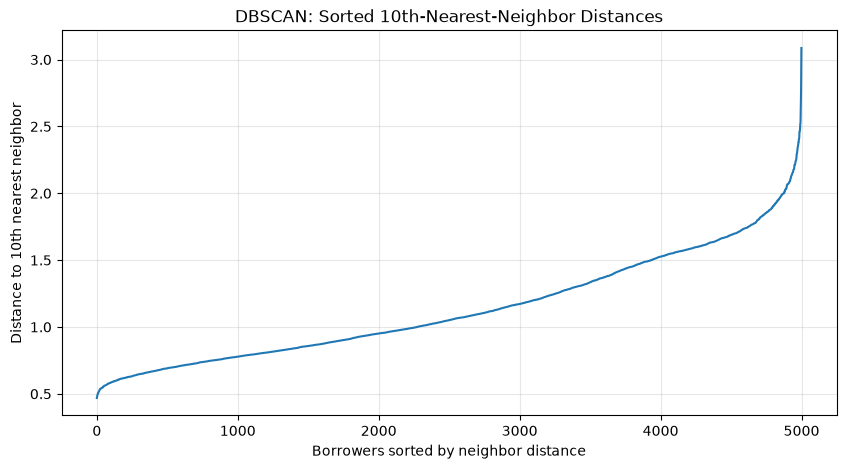

Nearest-neighbor distance summary:
50th percentile: 1.0513
75th percentile: 1.4362
90th percentile: 1.6880
95th percentile: 1.8541
99th percentile: 2.1974

Minimum distance: 0.4688
Maximum distance: 3.0866


In [168]:

# Step 137: Explore nearest-neighbor distances for DBSCAN

import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors

min_samples = 10

neighbors_model = NearestNeighbors(
    n_neighbors=min_samples,
    metric="euclidean"
)

neighbors_model.fit(comparison_sample)

distances, indices = neighbors_model.kneighbors(
    comparison_sample
)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.title("DBSCAN: Sorted 10th-Nearest-Neighbor Distances")
plt.xlabel("Borrowers sorted by neighbor distance")
plt.ylabel("Distance to 10th nearest neighbor")
plt.grid(alpha=0.3)

plt.show()

print("Nearest-neighbor distance summary:")

for percentile in [50, 75, 90, 95, 99]:
    value = np.percentile(k_distances, percentile)

    print(
        f"{percentile}th percentile: {value:.4f}"
    )

print("\nMinimum distance:", round(k_distances.min(), 4))
print("Maximum distance:", round(k_distances.max(), 4))


**Observation:** The sorted tenth-nearest-neighbor distance plot was generated using 5,000 preprocessed training borrowers. Distances ranged from 0.4688 to 3.0866, with the 90th and 95th percentiles at 1.6880 and 1.8541, respectively. The curve showed a noticeable increase in slope around 1.8–2.0, suggesting a possible neighborhood radius range for DBSCAN. Since the elbow was not sharply defined, multiple eps values will be evaluated to assess cluster formation, noise percentage and clustering quality.

In [169]:

# Step 138: DBSCAN parameter exploration

import time
import pandas as pd
import numpy as np

from sklearn.cluster import DBSCAN

eps_values = [1.4, 1.6, 1.8, 2.0, 2.2]

dbscan_results = []

for eps in eps_values:

    start_time = time.perf_counter()

    model = DBSCAN(
        eps=eps,
        min_samples=10,
        metric="euclidean",
        n_jobs=-1
    )

    labels = model.fit_predict(comparison_sample)

    runtime = time.perf_counter() - start_time

    number_of_clusters = len(
        set(labels) - {-1}
    )

    noise_count = np.sum(labels == -1)

    noise_percentage = (
        noise_count / len(labels) * 100
    )

    clustered_count = len(labels) - noise_count

    dbscan_results.append({
        "eps": eps,
        "Clusters": number_of_clusters,
        "Clustered_Borrowers": clustered_count,
        "Noise_Borrowers": noise_count,
        "Noise_%": round(noise_percentage, 2),
        "Runtime_Seconds": round(runtime, 3)
    })

dbscan_results_df = pd.DataFrame(dbscan_results)

print("DBSCAN parameter comparison:")

display(dbscan_results_df)


DBSCAN parameter comparison:


,eps,Clusters,Clustered_Borrowers,Noise_Borrowers,Noise_%,Runtime_Seconds
0,1.4,9,4191,809,16.18,0.033
1,1.6,1,4775,225,4.50,0.019
2,1.8,1,4923,77,1.54,0.028
3,2.0,1,4979,21,0.42,0.033
4,2.2,1,4995,5,0.10,0.044


**Observation:** DBSCAN was evaluated using five neighborhood radius values with min_samples=10 on 5,000 preprocessed borrowers. At eps=1.4, DBSCAN identified nine clusters and classified 16.18% of observations as noise. Increasing eps to 1.6 or above produced only one cluster, while noise declined from 4.50% to 0.10%. These findings demonstrate high sensitivity to neighborhood radius and suggest that smaller eps values require further investigation. DBSCAN noise observations should be interpreted as density-based outliers rather than automatically as high-credit-risk borrowers.

In [170]:

# Step 139: Refine DBSCAN parameter selection

import pandas as pd
import numpy as np

from sklearn.cluster import DBSCAN

refined_eps_values = [1.2, 1.3, 1.35, 1.4, 1.45, 1.5]

refined_results = []

for eps in refined_eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=10,
        metric="euclidean",
        n_jobs=-1
    )

    labels = model.fit_predict(comparison_sample)

    cluster_sizes = pd.Series(
        labels[labels != -1]
    ).value_counts()

    number_of_clusters = len(cluster_sizes)

    noise_count = int(np.sum(labels == -1))

    largest_cluster = (
        int(cluster_sizes.max())
        if number_of_clusters > 0
        else 0
    )

    smallest_cluster = (
        int(cluster_sizes.min())
        if number_of_clusters > 0
        else 0
    )

    refined_results.append({
        "eps": eps,
        "Clusters": number_of_clusters,
        "Noise_%": round(noise_count / len(labels) * 100, 2),
        "Largest_Cluster": largest_cluster,
        "Smallest_Cluster": smallest_cluster,
        "Largest_Cluster_%": round(
            largest_cluster / len(labels) * 100, 2
        )
    })

dbscan_refined_df = pd.DataFrame(refined_results)

print("Refined DBSCAN comparison:")
display(dbscan_refined_df)


Refined DBSCAN comparison:


,eps,Clusters,Noise_%,Largest_Cluster,Smallest_Cluster,Largest_Cluster_%
0,1.20,10,23.94,1349,10,26.98
1,1.30,11,19.78,1375,10,27.50
2,1.35,10,17.96,1387,15,27.74
3,1.40,9,16.18,1396,63,27.92
4,1.45,1,13.78,4311,4311,86.22
5,1.50,1,9.40,4530,4530,90.60


**Observation:** DBSCAN was evaluated using refined eps values between 1.20 and 1.50 with min_samples=10. At eps=1.30, the algorithm identified the highest number of clusters (11), with 19.78% noise. At eps=1.40, it identified nine clusters with 16.18% noise, and the largest cluster contained 27.92% of all borrowers. Increasing eps to 1.45 caused the groups to merge into a single cluster containing 86.22% of borrowers. This indicates strong parameter sensitivity. The eps=1.40 configuration is a promising candidate for further evaluation, but its silhouette score and cluster interpretability must be examined before selection.

In [171]:

# Step 140: Evaluate selected DBSCAN configuration

import numpy as np
import pandas as pd
import time

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

start_time = time.perf_counter()

dbscan_model = DBSCAN(
    eps=1.4,
    min_samples=10,
    metric="euclidean",
    n_jobs=-1
)

dbscan_labels = dbscan_model.fit_predict(
    comparison_sample
)

dbscan_runtime = time.perf_counter() - start_time

clustered_mask = dbscan_labels != -1

clustered_data = comparison_sample.loc[clustered_mask]
clustered_labels = dbscan_labels[clustered_mask]

n_clusters = len(set(clustered_labels))
noise_count = int(np.sum(~clustered_mask))

if n_clusters >= 2:
    dbscan_silhouette = silhouette_score(
        clustered_data,
        clustered_labels,
        sample_size=min(2000, len(clustered_data)),
        random_state=42
    )
else:
    dbscan_silhouette = np.nan

cluster_distribution = (
    pd.Series(dbscan_labels, name="Cluster")
    .value_counts()
    .sort_index()
)

print("DBSCAN evaluation results:")

print("\nClusters excluding noise:", n_clusters)
print("Noise borrowers:", noise_count)

print(
    "Noise percentage:",
    round(noise_count / len(dbscan_labels) * 100, 2)
)

print("\nCluster distribution:")
display(cluster_distribution.to_frame("Borrowers"))

print("\nSilhouette score (excluding noise):")
print(round(dbscan_silhouette, 4))

print("\nFitting runtime (seconds):")
print(round(dbscan_runtime, 3))

print("\nComparison reference:")
print("K-Means silhouette:", round(comparison_kmeans_silhouette, 4))
print("Hierarchical silhouette:", round(hierarchical_silhouette, 4))


DBSCAN evaluation results:

Clusters excluding noise: 9
Noise borrowers: 809
Noise percentage: 16.18

Cluster distribution:


,Borrowers
Cluster,
-1,809
0,507
1,1253
2,1396
3,63
4,205
5,464
6,141
7,89



Silhouette score (excluding noise):
0.05

Fitting runtime (seconds):
0.033

Comparison reference:
K-Means silhouette: 0.1418
Hierarchical silhouette: 0.0839


**Observation:** DBSCAN with eps=1.4 and min_samples=10 identified nine clusters and 809 noise observations (16.18%) among 5,000 training borrowers. Its noise-excluded silhouette score was 0.0500, compared with 0.1418 for K-Means and 0.0839 for Hierarchical Clustering. K-Means demonstrated the strongest observed cluster separation in these experiments, although all three scores were relatively low. DBSCAN identified several smaller groups and a substantial noise population, making it potentially useful for exploratory anomaly analysis. Since the DBSCAN silhouette calculation excludes noise observations, the scores should not be treated as perfectly equivalent.

In [172]:

# Step 141: Consolidated clustering algorithm comparison

import pandas as pd
import numpy as np

algorithm_comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical",
        "DBSCAN"
    ],
    "Clusters": [
        len(set(comparison_kmeans_labels)),
        len(set(hierarchical_labels)),
        n_clusters
    ],
    "Silhouette_Score": [
        comparison_kmeans_silhouette,
        hierarchical_silhouette,
        dbscan_silhouette
    ],
    "Noise_%": [
        0.0,
        0.0,
        noise_count / len(dbscan_labels) * 100
    ],
    "Runtime_Seconds": [
        comparison_kmeans_runtime,
        hierarchical_runtime,
        dbscan_runtime
    ],
    "Silhouette_Population": [
        "All borrowers",
        "All borrowers",
        "Clustered borrowers only"
    ]
})

print("Clustering algorithm comparison:")

display(
    algorithm_comparison.round(4)
)

print("\nHighest observed silhouette score:")

best_row = algorithm_comparison.loc[
    algorithm_comparison["Silhouette_Score"].idxmax()
]

print(best_row["Algorithm"])
print(round(best_row["Silhouette_Score"], 4))

print("\nImportant:")
print(
    "DBSCAN silhouette excludes noise; "
    "the scores are not strictly equivalent."
)


Clustering algorithm comparison:


,Algorithm,Clusters,Silhouette_Score,Noise_%,Runtime_Seconds,Silhouette_Population
0,K-Means,5,0.1418,0.00,0.0778,All borrowers
1,Hierarchical,5,0.0839,0.00,0.2148,All borrowers
2,DBSCAN,9,0.0500,16.18,0.0332,Clustered borrowers only



Highest observed silhouette score:
K-Means
0.1418

Important:
DBSCAN silhouette excludes noise; the scores are not strictly equivalent.


**Observation:** Three clustering algorithms were compared using a common sample of 5,000 preprocessed training borrowers. K-Means achieved the highest observed silhouette score (0.1418), followed by Hierarchical Clustering (0.0839) and DBSCAN (0.0500). DBSCAN identified nine clusters and classified 16.18% of observations as noise. Its silhouette score was calculated after excluding noise observations, limiting direct comparability. K-Means was selected provisionally as the primary borrower segmentation approach because of its relatively stronger cluster separation, computational efficiency and previously established business interpretability. DBSCAN was retained for exploratory anomaly analysis. All three algorithms exhibited relatively weak cluster separation.

In [173]:

# Step 142: PCA explained variance analysis

import pandas as pd
import numpy as np

from sklearn.decomposition import PCA

pca_model = PCA(
    n_components=5,
    random_state=42
)

pca_features = pca_model.fit_transform(
    comparison_sample
)

explained_variance = (
    pca_model.explained_variance_ratio_ * 100
)

cumulative_variance = (
    np.cumsum(explained_variance)
)

pca_variance_df = pd.DataFrame({
    "Principal_Component": [
        f"PC{i}" for i in range(1, 6)
    ],
    "Explained_Variance_%": explained_variance,
    "Cumulative_Variance_%": cumulative_variance
})

print("Original dataset shape:")
print(comparison_sample.shape)

print("\nPCA transformed shape:")
print(pca_features.shape)

print("\nPCA explained variance:")
display(pca_variance_df.round(2))

print("\nTotal variance explained by five components:")
print(round(cumulative_variance[-1], 2), "%")


Original dataset shape:
(5000, 24)

PCA transformed shape:
(5000, 5)

PCA explained variance:


,Principal_Component,Explained_Variance_%,Cumulative_Variance_%
0,PC1,27.56,27.56
1,PC2,17.96,45.52
2,PC3,15.09,60.62
3,PC4,14.48,75.10
4,PC5,7.13,82.23



Total variance explained by five components:
82.23 %


**Observation:** Principal Component Analysis (PCA) was applied to 5,000 preprocessed training borrowers with 24 features. The first five principal components explained 27.56%, 17.96%, 15.09%, 14.48% and 7.13% of the total variance, respectively. Together, they retained 82.23% of the original variance while reducing the feature space from 24 dimensions to five. This demonstrates the potential for dimensionality reduction, although further evaluation is needed to determine the number of components required to retain at least 90% of variance and whether reduced features preserve useful clustering structure.

Original features: 24
Components for 90% variance: 7
Components for 95% variance: 8
Actual variance retained at 90% threshold: 93.52 %


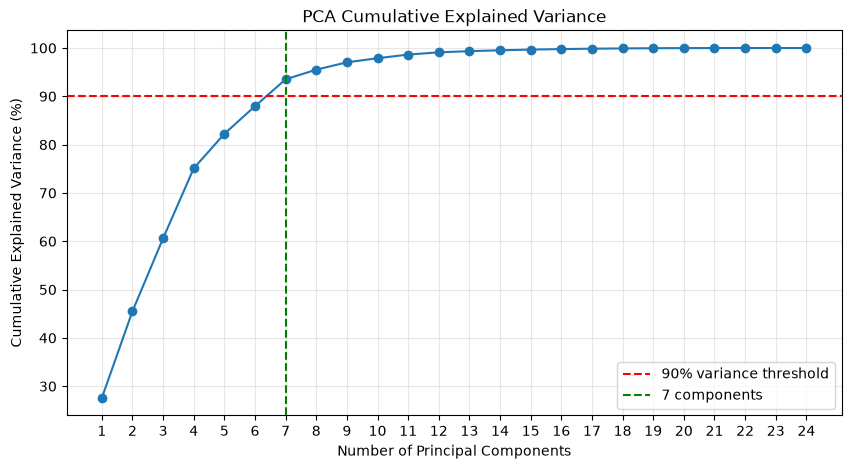

In [174]:

# Step 143: Determine PCA components for 90% variance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

pca_full = PCA()

pca_full.fit(comparison_sample)

cumulative_variance_full = np.cumsum(
    pca_full.explained_variance_ratio_
)

components_90 = np.searchsorted(
    cumulative_variance_full,
    0.90
) + 1

components_95 = np.searchsorted(
    cumulative_variance_full,
    0.95
) + 1

print("Original features:", comparison_sample.shape[1])

print("Components for 90% variance:", components_90)
print("Components for 95% variance:", components_95)

print(
    "Actual variance retained at 90% threshold:",
    round(cumulative_variance_full[components_90 - 1] * 100, 2),
    "%"
)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance_full) + 1),
    cumulative_variance_full * 100,
    marker="o"
)

plt.axhline(
    y=90,
    color="red",
    linestyle="--",
    label="90% variance threshold"
)

plt.axvline(
    x=components_90,
    color="green",
    linestyle="--",
    label=f"{components_90} components"
)

plt.title("PCA Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.xticks(range(1, len(cumulative_variance_full) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Observation:** PCA cumulative explained variance analysis showed that seven principal components retain 93.52% of the variance in the original 24-feature dataset. Eight components are required to reach at least 95% variance. Using seven components reduces dimensionality by approximately 70.8%. The cumulative variance curve begins to flatten after the initial components, suggesting diminishing contributions from later components. Seven components were selected as a candidate representation for evaluating PCA-based K-Means clustering against the original feature space.

In [175]:

# Step 144: Compare K-Means before and after PCA

import time
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Reduce 24 features to 7 principal components
pca_7 = PCA(n_components=7, random_state=42)

X_pca_7 = pca_7.fit_transform(comparison_sample)

# Train K-Means using PCA features
start_time = time.perf_counter()

kmeans_pca = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=10,
    random_state=42
)

kmeans_pca_labels = kmeans_pca.fit_predict(X_pca_7)

pca_kmeans_runtime = time.perf_counter() - start_time

# Evaluate PCA-based clustering
pca_kmeans_silhouette = silhouette_score(
    X_pca_7,
    kmeans_pca_labels,
    sample_size=2000,
    random_state=42
)

comparison_pca_df = pd.DataFrame({
    "Model": [
        "K-Means (24 features)",
        "PCA + K-Means (7 components)"
    ],
    "Dimensions": [24, 7],
    "Silhouette": [
        comparison_kmeans_silhouette,
        pca_kmeans_silhouette
    ],
    "KMeans_Fit_Seconds": [
        comparison_kmeans_runtime,
        pca_kmeans_runtime
    ]
})

print("Variance retained by 7 PCs:")
print(round(sum(pca_7.explained_variance_ratio_) * 100, 2), "%")

print("\nPCA transformed shape:")
print(X_pca_7.shape)

print("\nClustering comparison:")
display(comparison_pca_df.round(4))

print("\nPCA cluster sizes:")
display(
    pd.Series(kmeans_pca_labels)
    .value_counts()
    .sort_index()
    .to_frame("Borrowers")
)


Variance retained by 7 PCs:
93.52 %

PCA transformed shape:
(5000, 7)

Clustering comparison:


,Model,Dimensions,Silhouette,KMeans_Fit_Seconds
0,K-Means (24 features),24,0.1418,0.0778
1,PCA + K-Means (7 components),7,0.1543,0.0941



PCA cluster sizes:


,Borrowers
0,544
1,1175
2,1041
3,1360
4,880


**Observation:** PCA reduced the borrower feature space from 24 dimensions to seven principal components while retaining 93.52% of the total variance. K-Means clustering on the PCA-reduced data produced five clusters with a silhouette score of 0.1543, compared with 0.1418 for K-Means using the original features. The PCA-based clusters ranged from 544 to 1,360 borrowers. Although PCA-based clustering showed a modest improvement in silhouette score, the scores were measured in different feature spaces. Therefore, the original business segmentation model should not be replaced without evaluating cluster consistency and interpretability.

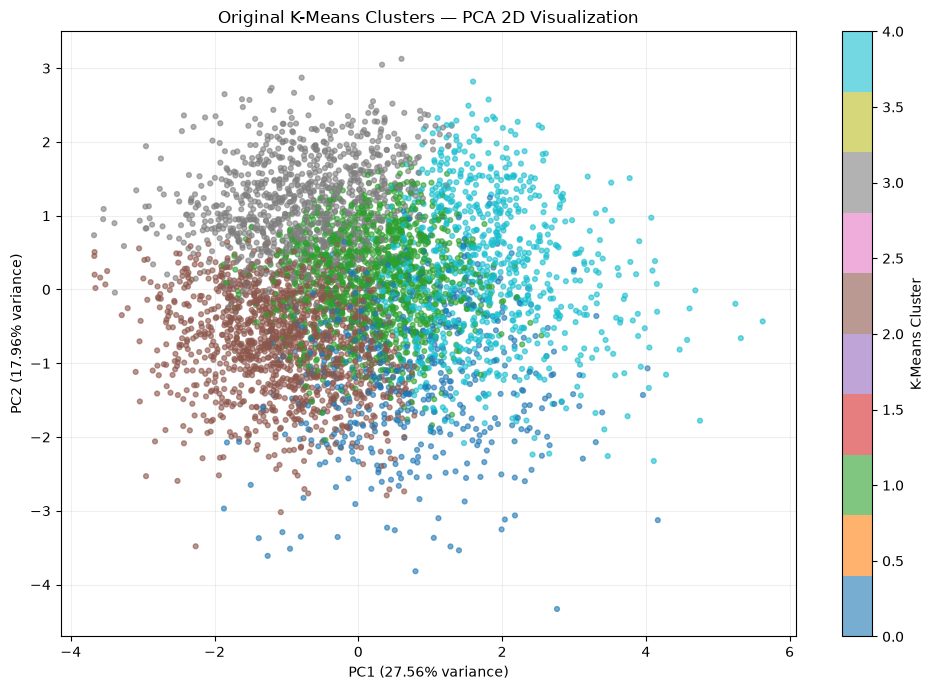

PCA 2D shape: (5000, 2)
Total variance shown in 2D: 45.52 %


In [176]:

# Step 145: Visualize original K-Means clusters using PCA

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

# Reduce the original 24 features to 2D for visualization
pca_2d = PCA(
    n_components=2,
    random_state=42
)

X_pca_2d = pca_2d.fit_transform(comparison_sample)

# Create visualization dataframe
pca_plot_df = pd.DataFrame({
    "PC1": X_pca_2d[:, 0],
    "PC2": X_pca_2d[:, 1],
    "Cluster": comparison_kmeans_labels
})

# Plot the original K-Means cluster assignments
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    pca_plot_df["PC1"],
    pca_plot_df["PC2"],
    c=pca_plot_df["Cluster"],
    cmap="tab10",
    s=12,
    alpha=0.6
)

plt.xlabel(
    f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}% variance)"
)

plt.ylabel(
    f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}% variance)"
)

plt.title("Original K-Means Clusters — PCA 2D Visualization")

plt.colorbar(scatter, label="K-Means Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("PCA 2D shape:", X_pca_2d.shape)

print(
    "Total variance shown in 2D:",
    round(sum(pca_2d.explained_variance_ratio_) * 100, 2),
    "%"
)


**Observation:** PCA was used to project 5,000 borrowers from 24 original dimensions into two dimensions for visualizing the existing K-Means clusters. PC1 explained 27.56% of total variance and PC2 explained 17.96%, representing 45.52% cumulatively. The visualization showed substantial overlap between the five clusters, although some groups occupied different regions of the plot. Since the two-dimensional projection preserves less than half of the total variance, visual overlap alone cannot fully describe separation in the original feature space. This finding is consistent with the relatively low K-Means silhouette score.

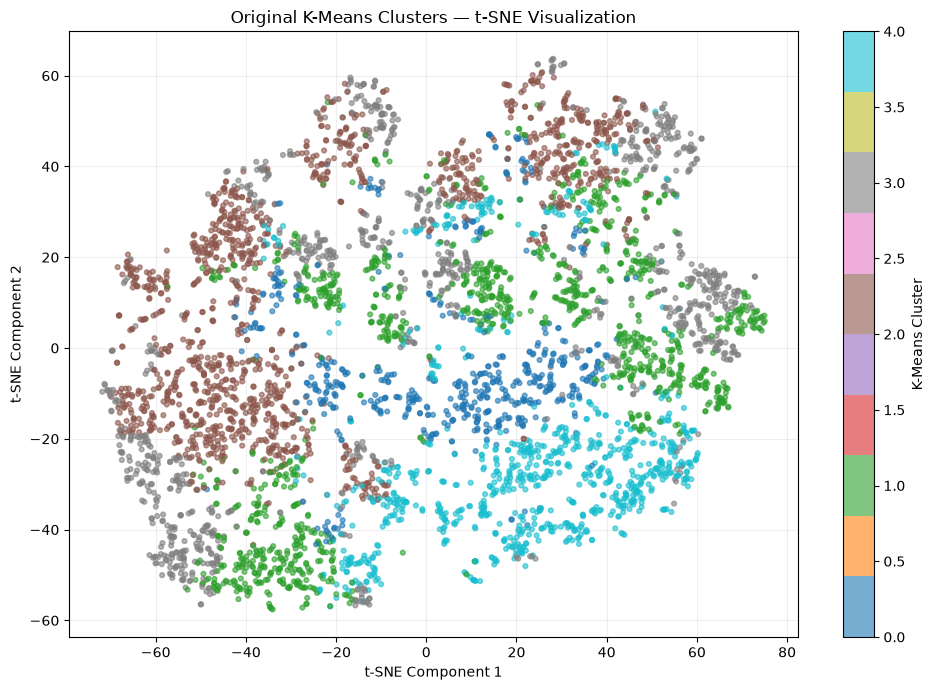

Original shape: (5000, 24)
t-SNE transformed shape: (5000, 2)
t-SNE KL divergence: 1.5981


In [177]:

# Step 146: t-SNE visualization of original K-Means clusters

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE

tsne_model = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne_2d = tsne_model.fit_transform(
    comparison_sample
)

tsne_plot_df = pd.DataFrame({
    "tSNE_1": X_tsne_2d[:, 0],
    "tSNE_2": X_tsne_2d[:, 1],
    "Cluster": comparison_kmeans_labels
})

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    tsne_plot_df["tSNE_1"],
    tsne_plot_df["tSNE_2"],
    c=tsne_plot_df["Cluster"],
    cmap="tab10",
    s=12,
    alpha=0.6
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("Original K-Means Clusters — t-SNE Visualization")

plt.colorbar(scatter, label="K-Means Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Original shape:", comparison_sample.shape)
print("t-SNE transformed shape:", X_tsne_2d.shape)

print(
    "t-SNE KL divergence:",
    round(tsne_model.kl_divergence_, 4)
)


**Observation:** t-SNE was applied to 5,000 preprocessed borrowers with 24 features, producing a two-dimensional representation. The resulting visualization showed more detailed local groupings than the PCA projection. Some K-Means clusters occupied recognizable regions, while considerable overlap remained between several groups. The t-SNE model reported a KL divergence of 1.5981. As t-SNE is primarily a nonlinear visualization technique, this result does not establish improved clustering quality or change the original K-Means assignments.

/opt/anaconda3/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


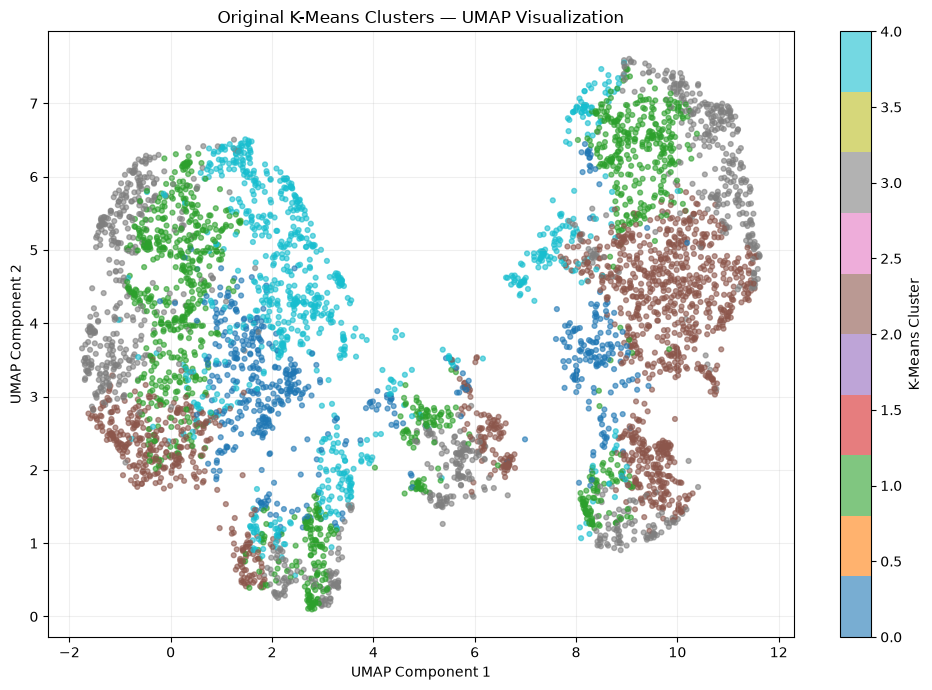

Original shape: (5000, 24)
UMAP transformed shape: (5000, 2)
Number of original K-Means clusters: 5


In [180]:

# Step 147: UMAP visualization of original K-Means clusters

import pandas as pd
import matplotlib.pyplot as plt

try:
    import umap
except ImportError:
    raise ImportError(
        "UMAP is not installed. Run "
        "'%pip install umap-learn' in a separate "
        "notebook cell, then retry Step 147."
    )

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=30,
    min_dist=0.1,
    metric="euclidean",
    random_state=42
)

X_umap_2d = umap_model.fit_transform(
    comparison_sample
)

umap_plot_df = pd.DataFrame({
    "UMAP_1": X_umap_2d[:, 0],
    "UMAP_2": X_umap_2d[:, 1],
    "Cluster": comparison_kmeans_labels
})

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    umap_plot_df["UMAP_1"],
    umap_plot_df["UMAP_2"],
    c=umap_plot_df["Cluster"],
    cmap="tab10",
    s=12,
    alpha=0.6
)

plt.xlabel("UMAP Component 1")
plt.ylabel("UMAP Component 2")
plt.title("Original K-Means Clusters — UMAP Visualization")

plt.colorbar(scatter, label="K-Means Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Original shape:", comparison_sample.shape)
print("UMAP transformed shape:", X_umap_2d.shape)
print("Number of original K-Means clusters:",
      len(set(comparison_kmeans_labels)))


**Observation:** UMAP was applied to the same 5,000 borrowers and 24 preprocessed features, generating a two-dimensional representation. The visualization revealed two prominent regions and several smaller local groupings. Although some K-Means clusters were concentrated in particular areas, substantial color overlap remained. Compared with PCA and t-SNE, UMAP provided another view of the nonlinear structure within the borrower dataset. The visualization did not change the original cluster assignments or establish any relationship between visual isolation and historical default risk.

In [181]:

# Step 148: Identify DBSCAN noise borrowers

import pandas as pd
import numpy as np

# DBSCAN labels correspond to comparison_sample row order
dbscan_status = pd.Series(
    np.where(dbscan_labels == -1, "Noise", "Clustered"),
    index=comparison_sample.index,
    name="DBSCAN_Status"
)

# Compare preprocessed feature patterns first
noise_feature_profile = comparison_sample.copy()

noise_feature_profile["DBSCAN_Status"] = dbscan_status

feature_means = (
    noise_feature_profile
    .groupby("DBSCAN_Status")
    .mean(numeric_only=True)
    .T
)

feature_means["Absolute_Difference"] = (
    feature_means["Noise"] - feature_means["Clustered"]
).abs()

feature_means = feature_means.sort_values(
    "Absolute_Difference",
    ascending=False
)

print("DBSCAN population counts:")
display(dbscan_status.value_counts().to_frame("Borrowers"))

print("\nTop 10 preprocessed features differing between groups:")
display(feature_means.head(10).round(3))

print("\nComparison sample rows:", len(comparison_sample))
print("Noise borrowers:", (dbscan_status == "Noise").sum())


DBSCAN population counts:


,Borrowers
DBSCAN_Status,
Clustered,4191
Noise,809



Top 10 preprocessed features differing between groups:


DBSCAN_Status,Clustered,Noise,Absolute_Difference
fico_n,-0.152,0.695,0.847
purpose_debt_consolidation,0.681,0.122,0.559
DTI_IQR_Final,0.046,-0.225,0.271
home_ownership_n_OWN,0.064,0.237,0.173
Revenue_Log_Final,-0.020,0.153,0.173
purpose_major_purchase,0.000,0.147,0.147
purpose_home_improvement,0.034,0.153,0.120
home_ownership_n_MORTGAGE,0.505,0.398,0.107
purpose_credit_card,0.247,0.143,0.103
Employment_Years_Imputed,-0.006,-0.103,0.097



Comparison sample rows: 5000
Noise borrowers: 809


**Observation:** DBSCAN classified 809 of 5,000 borrowers (16.18%) as noise and assigned 4,191 borrowers to clusters. Noise borrowers showed higher average standardized FICO scores, lower standardized DTI values and a different distribution of loan purposes compared with clustered borrowers. Debt consolidation represented 12.2% of noise borrowers versus 68.1% of clustered borrowers, while major-purchase loans and home ownership were more common in the noise group. These findings suggest that DBSCAN identifies uncommon combinations of borrower characteristics rather than necessarily identifying financially high-risk individuals. Further analysis using original financial values and historical default outcomes is required.

In [182]:

# Step 149: Verify original training data alignment

candidate_names = [
    "train_df",
    "df_train",
    "train_data",
    "train",
    "X_train",
    "y_train"
]

print("Comparison sample shape:", comparison_sample.shape)

print("\nAvailable candidate training objects:")

for name in candidate_names:
    if name in globals():
        obj = globals()[name]

        print(f"\n{name}")
        print("Type:", type(obj).__name__)

        if hasattr(obj, "shape"):
            print("Shape:", obj.shape)

        if isinstance(obj, (pd.DataFrame, pd.Series)):
            matching_indices = comparison_sample.index.isin(
                obj.index
            ).sum()

            print(
                "Matching comparison indices:",
                matching_indices,
                "/",
                len(comparison_sample)
            )

            if isinstance(obj, pd.DataFrame):
                print(
                    "Has Default column:",
                    "Default" in obj.columns
                )

                print(
                    "Available financial columns:",
                    [
                        col for col in [
                            "revenue",
                            "dti_n",
                            "loan_amnt",
                            "fico_n",
                            "Default"
                        ]
                        if col in obj.columns
                    ]
                )


Comparison sample shape: (5000, 24)

Available candidate training objects:

train_df
Type: DataFrame
Shape: (829347, 29)
Matching comparison indices: 5000 / 5000
Has Default column: True
Available financial columns: ['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'Default']


**Observation:** Data alignment verification confirmed that all 5,000 borrowers in the DBSCAN comparison sample have matching indices in the original training dataframe, train_df. The training dataframe contains the original financial variables and historical default outcomes required for anomaly profiling. This enables an index-aligned comparison of DBSCAN noise borrowers and clustered borrowers without relying on row positions or modifying the existing models.

In [183]:

# Step 150: DBSCAN noise vs clustered borrower profiling

import pandas as pd
import numpy as np

# Extract original training records using sample indices
dbscan_profile = train_df.loc[
    comparison_sample.index,
    ["revenue", "dti_n", "loan_amnt", "fico_n", "Default"]
].copy()

# Align DBSCAN status using borrower indices
dbscan_profile["DBSCAN_Status"] = dbscan_status

# Confirm alignment and completeness
assert len(dbscan_profile) == len(comparison_sample)
assert dbscan_profile["DBSCAN_Status"].notna().all()
assert dbscan_profile["Default"].notna().all()

# Create borrower-level group summary
dbscan_business_summary = (
    dbscan_profile
    .groupby("DBSCAN_Status")
    .agg(
        Borrowers=("Default", "size"),
        Historical_Defaults=("Default", "sum"),
        Historical_Default_Rate=("Default", "mean"),
        Avg_Income=("revenue", "mean"),
        Median_Income=("revenue", "median"),
        Avg_DTI=("dti_n", "mean"),
        Median_DTI=("dti_n", "median"),
        Avg_Loan_Amount=("loan_amnt", "mean"),
        Median_Loan_Amount=("loan_amnt", "median"),
        Avg_FICO=("fico_n", "mean"),
        Median_FICO=("fico_n", "median")
    )
)

# Convert default rate to percentage
dbscan_business_summary["Historical_Default_Rate_%"] = (
    dbscan_business_summary["Historical_Default_Rate"] * 100
)

# Display business-friendly columns
display_columns = [
    "Borrowers",
    "Historical_Defaults",
    "Historical_Default_Rate_%",
    "Avg_Income",
    "Median_Income",
    "Avg_DTI",
    "Median_DTI",
    "Avg_Loan_Amount",
    "Median_Loan_Amount",
    "Avg_FICO",
    "Median_FICO"
]

print("DBSCAN borrower financial and default profile:")

display(
    dbscan_business_summary[
        display_columns
    ].round(2)
)

print("\nOverall sample historical default rate:")

print(
    round(dbscan_profile["Default"].mean() * 100, 2),
    "%"
)

print("\nData checks:")
print("Rows:", len(dbscan_profile))
print("Missing DBSCAN labels:",
      dbscan_profile["DBSCAN_Status"].isna().sum())
print("Missing Default values:",
      dbscan_profile["Default"].isna().sum())


DBSCAN borrower financial and default profile:


,Borrowers,Historical_Defaults,Historical_Default_Rate_%,Avg_Income,Median_Income,Avg_DTI,Median_DTI,Avg_Loan_Amount,Median_Loan_Amount,Avg_FICO,Median_FICO
DBSCAN_Status,,,,,,,,,,,
Clustered,4191,799,19.06,71514.56,63000.0,18.34,17.89,14463.99,12600.0,692.34,687.0
Noise,809,138,17.06,93058.75,66766.0,16.10,14.90,13761.16,10000.0,718.29,712.0



Overall sample historical default rate:
18.74 %

Data checks:
Rows: 5000
Missing DBSCAN labels: 0
Missing Default values: 0


**Observation:** Historical financial profiling was conducted for 5,000 training borrowers using DBSCAN noise labels aligned with the original dataset. The clustered group contained 4,191 borrowers with a historical default rate of 19.06%, while the noise group contained 809 borrowers with a lower default rate of 17.06%. Noise borrowers had higher average FICO scores (718.29 versus 692.34), higher average income (93,058.75 versus 71,514.56) and lower average DTI (16.10 versus 18.34). These findings indicate that DBSCAN noise membership reflects unusual combinations of borrower characteristics rather than necessarily identifying higher-risk borrowers. The observed default-rate difference is descriptive and requires further statistical and out-of-sample validation.

In [184]:

# Step 151: Statistical comparison of historical default rates

import numpy as np
import pandas as pd
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

# Extract group counts from Step 150
noise_defaults = int(
    dbscan_business_summary.loc[
        "Noise", "Historical_Defaults"
    ]
)

noise_total = int(
    dbscan_business_summary.loc[
        "Noise", "Borrowers"
    ]
)

clustered_defaults = int(
    dbscan_business_summary.loc[
        "Clustered", "Historical_Defaults"
    ]
)

clustered_total = int(
    dbscan_business_summary.loc[
        "Clustered", "Borrowers"
    ]
)

# Compare noise minus clustered default rates
counts = np.array([
    noise_defaults,
    clustered_defaults
])

sample_sizes = np.array([
    noise_total,
    clustered_total
])

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=sample_sizes
)

ci_low, ci_high = confint_proportions_2indep(
    count1=noise_defaults,
    nobs1=noise_total,
    count2=clustered_defaults,
    nobs2=clustered_total,
    method="newcomb"
)

rate_difference = (
    noise_defaults / noise_total
    - clustered_defaults / clustered_total
)

print("Historical default rate comparison:")
print("Noise default rate:",
      round(noise_defaults / noise_total * 100, 2), "%")
print("Clustered default rate:",
      round(clustered_defaults / clustered_total * 100, 2), "%")

print("\nDifference (Noise - Clustered):")
print(round(rate_difference * 100, 2), "percentage points")

print("\nTwo-proportion z-test:")
print("Z statistic:", round(z_stat, 4))
print("P-value:", round(p_value, 4))

print("\n95% confidence interval for difference:")
print(
    f"[{ci_low * 100:.2f}, {ci_high * 100:.2f}] percentage points"
)

print("\nSignificant at 5% level:",
      p_value < 0.05)


Historical default rate comparison:
Noise default rate: 17.06 %
Clustered default rate: 19.06 %

Difference (Noise - Clustered):
-2.01 percentage points

Two-proportion z-test:
Z statistic: -1.339
P-value: 0.1806

95% confidence interval for difference:
[-4.73, 0.97] percentage points

Significant at 5% level: False


**Observation:** A two-proportion z-test was performed to compare historical default rates between DBSCAN noise borrowers and clustered borrowers. The noise group recorded a default rate of 17.06%, compared with 19.06% for clustered borrowers, representing a difference of −2.01 percentage points. The test produced a z-statistic of −1.339 and a p-value of 0.1806. The 95% confidence interval for the difference was [−4.73, 0.97] percentage points, which includes zero. Therefore, the observed difference was not statistically significant at the 5% level. DBSCAN noise membership should not be interpreted as evidence of higher or lower credit risk. The analysis remains exploratory and is subject to the assumptions of the statistical test and possible differences in historical loan observation periods.

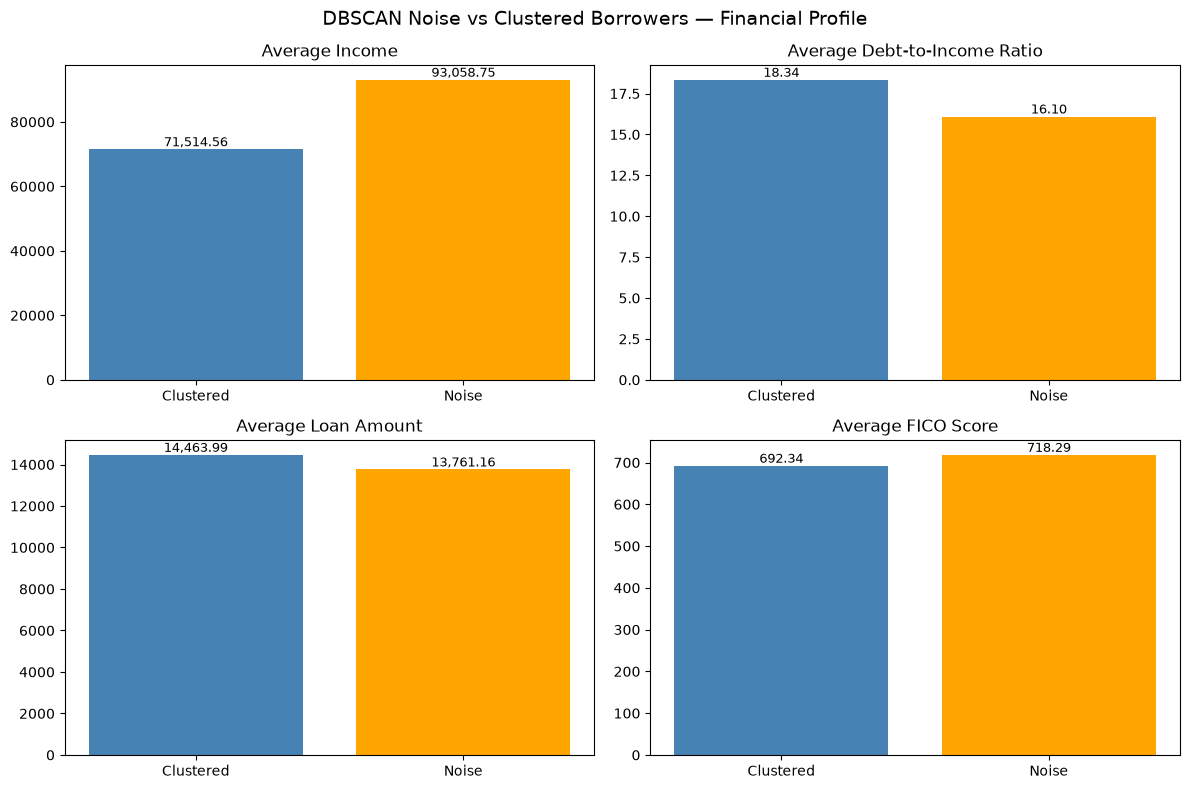

In [185]:

# Step 152: Visualize DBSCAN borrower financial profiles

import matplotlib.pyplot as plt

metrics = [
    ("Avg_Income", "Average Income"),
    ("Avg_DTI", "Average Debt-to-Income Ratio"),
    ("Avg_Loan_Amount", "Average Loan Amount"),
    ("Avg_FICO", "Average FICO Score")
]

groups = ["Clustered", "Noise"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, title) in zip(axes.flatten(), metrics):

    values = dbscan_business_summary.loc[
        groups, column
    ]

    bars = ax.bar(
        groups,
        values,
        color=["steelblue", "orange"]
    )

    ax.set_title(title)
    ax.set_ylim(bottom=0)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:,.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.suptitle(
    "DBSCAN Noise vs Clustered Borrowers — Financial Profile",
    fontsize=14
)

plt.tight_layout()
plt.show()


**Observation:** Four comparative charts were created to examine the original financial characteristics of DBSCAN noise borrowers and clustered borrowers. Noise borrowers had higher average income (93,058.75 versus 71,514.56), higher average FICO scores (718.29 versus 692.34), lower average DTI (16.10 versus 18.34) and slightly lower average loan amounts (13,761.16 versus 14,463.99). These findings reinforce that DBSCAN identifies unusual feature combinations rather than necessarily identifying high-risk borrowers. The historical default-rate difference between the groups was not statistically significant at the 5% level.

In [186]:

# Step 153: Final clustering data leakage audit

import pandas as pd

print("FINAL CLUSTERING DATA AUDIT")

datasets = {
    "Train": X_train_final,
    "Validation": X_val_final,
    "Test": X_test_final
}

for name, data in datasets.items():
    print(f"\n{name} dataset")
    print("Shape:", data.shape)
    print("Default included:", "Default" in data.columns)
    print("Duplicate indices:", data.index.duplicated().sum())
    print("Missing values:", int(data.isna().sum().sum()))

print("\nIndex overlap checks:")

train_val_overlap = X_train_final.index.intersection(
    X_val_final.index
)

train_test_overlap = X_train_final.index.intersection(
    X_test_final.index
)

val_test_overlap = X_val_final.index.intersection(
    X_test_final.index
)

print("Train vs Validation:", len(train_val_overlap))
print("Train vs Test:", len(train_test_overlap))
print("Validation vs Test:", len(val_test_overlap))

print("\nFeature consistency:")

print(
    "Train and Validation columns match:",
    X_train_final.columns.equals(X_val_final.columns)
)

print(
    "Train and Test columns match:",
    X_train_final.columns.equals(X_test_final.columns)
)

print("\nComparison sample alignment:")

print(
    "Sample belongs to training set:",
    comparison_sample.index.isin(
        X_train_final.index
    ).all()
)


FINAL CLUSTERING DATA AUDIT

Train dataset
Shape: (829347, 24)
Default included: False
Duplicate indices: 0
Missing values: 0

Validation dataset
Shape: (293057, 24)
Default included: False
Duplicate indices: 0
Missing values: 0

Test dataset
Shape: (225277, 24)
Default included: False
Duplicate indices: 0
Missing values: 0

Index overlap checks:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

Feature consistency:
Train and Validation columns match: True
Train and Test columns match: True

Comparison sample alignment:
Sample belongs to training set: True


**Observation:** A final data audit was performed on the preprocessed training, validation and test datasets. The datasets contained 829,347, 293,057 and 225,277 borrowers respectively, with 24 consistent features. No missing values, duplicate indices or overlapping indices were detected. The historical Default target was excluded from all clustering feature matrices. The 5,000-borrower algorithm comparison sample was also confirmed to belong entirely to the training dataset. These checks support the structural integrity of the clustering workflow, although preprocessing leakage and temporal outcome limitations require separate consideration.

In [187]:

# Step 154: Final project quality summary

import pandas as pd

project_quality_summary = pd.DataFrame([
    {
        "Component": "Data Preparation",
        "Finding": "24 consistent features; no missing values",
        "Status": "Passed"
    },
    {
        "Component": "Dataset Separation",
        "Finding": "No overlapping row indices",
        "Status": "Passed"
    },
    {
        "Component": "Target Leakage Check",
        "Finding": "Default excluded from clustering features",
        "Status": "Passed"
    },
    {
        "Component": "Primary Clustering",
        "Finding": "K-Means: 5 clusters; silhouette 0.1418",
        "Status": "Selected"
    },
    {
        "Component": "Hierarchical Clustering",
        "Finding": "5 clusters; silhouette 0.0839",
        "Status": "Compared"
    },
    {
        "Component": "DBSCAN",
        "Finding": "9 clusters; 16.18% noise",
        "Status": "Exploratory"
    },
    {
        "Component": "PCA",
        "Finding": "7 components retain 93.52% variance",
        "Status": "Completed"
    },
    {
        "Component": "t-SNE and UMAP",
        "Finding": "2D visualizations of existing clusters",
        "Status": "Completed"
    },
    {
        "Component": "Anomaly Risk Analysis",
        "Finding": "Default-rate difference not significant (p=0.1806)",
        "Status": "Completed"
    }
])

print("FINAL PROJECT QUALITY SUMMARY")

display(project_quality_summary)

print("\nTotal checks/components:",
      len(project_quality_summary))

print("\nStatus distribution:")

display(
    project_quality_summary["Status"]
    .value_counts()
    .to_frame("Count")
)


FINAL PROJECT QUALITY SUMMARY


,Component,Finding,Status
0,Data Preparation,24 consistent features; no missing values,Passed
1,Dataset Separation,No overlapping row indices,Passed
2,Target Leakage Check,Default excluded from clustering features,Passed
3,Primary Clustering,K-Means: 5 clusters; silhouette 0.1418,Selected
4,Hierarchical Clustering,5 clusters; silhouette 0.0839,Compared
5,DBSCAN,9 clusters; 16.18% noise,Exploratory
6,PCA,7 components retain 93.52% variance,Completed
7,t-SNE and UMAP,2D visualizations of existing clusters,Completed
8,Anomaly Risk Analysis,Default-rate difference not significant (p=0.1...,Completed



Total checks/components: 9

Status distribution:


,Count
Status,
Passed,3
Completed,3
Selected,1
Compared,1
Exploratory,1


**Observation:** The final project quality review consolidated nine analytical components, covering data preparation, dataset separation, clustering algorithms, dimensionality reduction and anomaly analysis. K-Means was retained as the primary borrower segmentation model, with Hierarchical Clustering used for comparison and DBSCAN for exploratory anomaly profiling. PCA, t-SNE and UMAP were implemented to investigate dimensionality reduction and cluster structure. The analysis identified several limitations, including weak silhouette separation and the absence of a statistically significant default-rate difference between DBSCAN noise and clustered borrowers. These limitations will be communicated alongside the business findings in the final dashboard.

In [188]:

# Step 155: Verify existing dashboard source files

from pathlib import Path
import pandas as pd

project_dir = Path.home() / "Credit_Portfolio_Segmentation"

output_dir = project_dir / "project_outputs"

scorecard_path = (
    output_dir / "credit_segment_scorecard.csv"
)

print("Project folder:", project_dir)
print("Project folder exists:", project_dir.exists())

print("\nOutput folder:", output_dir)
print("Output folder exists:", output_dir.exists())

print("\nScorecard file:", scorecard_path)
print("Scorecard exists:", scorecard_path.exists())

if scorecard_path.exists():

    dashboard_scorecard = pd.read_csv(scorecard_path)

    print("\nScorecard shape:")
    print(dashboard_scorecard.shape)

    print("\nScorecard columns:")
    print(dashboard_scorecard.columns.tolist())

    print("\nScorecard preview:")
    display(dashboard_scorecard.head())

    print("\nMissing values:")
    print(dashboard_scorecard.isna().sum())

else:
    print(
        "\nScorecard not found. "
        "We will check its saved location before proceeding."
    )


Project folder: /Users/dhanalakshmi/Credit_Portfolio_Segmentation
Project folder exists: True

Output folder: /Users/dhanalakshmi/Credit_Portfolio_Segmentation/project_outputs
Output folder exists: True

Scorecard file: /Users/dhanalakshmi/Credit_Portfolio_Segmentation/project_outputs/credit_segment_scorecard.csv
Scorecard exists: True

Scorecard shape:
(5, 11)

Scorecard columns:
['Cluster', 'Segment_Name', 'Borrowers', 'Borrower_Share_%', 'Defaults', 'Default_Rate_%', 'Relative_Default_Index', 'Default_Share_%', 'Avg_Original_Loan', 'Total_Original_Principal', 'Principal_Share_%']

Scorecard preview:


,Cluster,Segment_Name,Borrowers,Borrower_Share_%,Defaults,Default_Rate_%,Relative_Default_Index,Default_Share_%,Avg_Original_Loan,Total_Original_Principal,Principal_Share_%
0,0,Higher-FICO Mortgage-Oriented,34893,15.4889,3645,10.4462,0.4907,7.6004,12543.1290,437667400,13.4531
1,1,Shorter-Employment Renters,51155,22.7076,11457,22.3966,1.0521,23.8897,9205.6392,470914475,14.4751
2,2,Higher-Income Larger-Loan,48391,21.4807,11976,24.7484,1.1625,24.9719,28375.0522,1373097150,42.2065
3,3,Higher Debt-Burden,43259,19.2026,12542,28.9928,1.3619,26.1520,10929.8684,472815175,14.5335
4,4,Longer-Employment Lower-DTI,47579,21.1202,8338,17.5245,0.8232,17.3860,10483.3645,498788000,15.3318



Missing values:
Cluster                     0
Segment_Name                0
Borrowers                   0
Borrower_Share_%            0
Defaults                    0
Default_Rate_%              0
Relative_Default_Index      0
Default_Share_%             0
Avg_Original_Loan           0
Total_Original_Principal    0
Principal_Share_%           0
dtype: int64


**Observation:** The final credit segment scorecard was successfully verified in the project output directory. The file contains five borrower segments and eleven business metrics, with no missing values. The Higher Debt-Burden segment recorded the highest historical default rate (28.99%), while the Higher-Income Larger-Loan segment accounted for the largest share of original loan principal (42.21%). The verified scorecard will serve as the primary data source for the Streamlit dashboard, avoiding unnecessary model retraining during application refreshes.

In [190]:

# Check fitted models and preprocessing objects

from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

print("Available fitted model candidates:\n")

for name, obj in list(globals().items()):

    if isinstance(obj, (KMeans, Pipeline, ColumnTransformer)):

        print(
            "Object:", name,
            "| Type:", type(obj).__name__
        )

        if isinstance(obj, KMeans):

            print(
                "  Number of clusters:",
                obj.n_clusters
            )

            print(
                "  Fitted:",
                hasattr(obj, "cluster_centers_")
            )

            if hasattr(obj, "n_features_in_"):

                print(
                    "  Input features:",
                    obj.n_features_in_
                )

print("\nFinal feature matrix:")
print("Shape:", X_train_final.shape)
print("Feature count:", len(X_train_final.columns))


Available fitted model candidates:

Object: k5_model | Type: KMeans
  Number of clusters: 5
  Fitted: True
  Input features: 24
Object: model_a | Type: KMeans
  Number of clusters: 5
  Fitted: True
  Input features: 24
Object: model_b | Type: KMeans
  Number of clusters: 5
  Fitted: True
  Input features: 24
Object: comparison_kmeans | Type: KMeans
  Number of clusters: 5
  Fitted: True
  Input features: 24
Object: kmeans_pca | Type: KMeans
  Number of clusters: 5
  Fitted: True
  Input features: 7

Final feature matrix:
Shape: (829347, 24)
Feature count: 24


**Observation:** Five fitted K-Means objects were identified in the notebook. Four models accept 24 preprocessed features, while the PCA-based model accepts seven components. Before model serialization, the final model must be verified against the original clustering workflow and business segment mapping. The fitted preprocessing components and feature order must also be preserved to ensure consistent inference.

In [191]:

# Step 158B: Identify the final K-Means model

import numpy as np
import pandas as pd

candidate_names = [
    "k5_model",
    "model_a",
    "model_b",
    "comparison_kmeans",
    "kmeans_pca"
]

results = []

for name in candidate_names:

    model = globals()[name]

    centers = model.cluster_centers_

    results.append({
        "Model": name,
        "Clusters": model.n_clusters,
        "Input_Features": model.n_features_in_,
        "Iterations": model.n_iter_,
        "Inertia": round(model.inertia_, 2),
        "Center_Shape": str(centers.shape)
    })

model_audit_df = pd.DataFrame(results)

print("K-Means model audit:")
display(model_audit_df)

print("\nCluster center comparison:")

for name in [
    "model_a",
    "model_b",
    "comparison_kmeans"
]:

    same_centers = np.allclose(
        k5_model.cluster_centers_,
        globals()[name].cluster_centers_
    )

    print(
        f"k5_model vs {name}:",
        "Same centers" if same_centers else "Different centers"
    )

print("\nFinal training feature order:")

print(X_train_final.columns.tolist())


K-Means model audit:


,Model,Clusters,Input_Features,Iterations,Inertia,Center_Shape
0,k5_model,5,24,28,192071.65,"(5, 24)"
1,model_a,5,24,38,38588.59,"(5, 24)"
2,model_b,5,24,43,38582.67,"(5, 24)"
3,comparison_kmeans,5,24,63,19083.21,"(5, 24)"
4,kmeans_pca,5,7,22,17066.26,"(5, 7)"



Cluster center comparison:
k5_model vs model_a: Different centers
k5_model vs model_b: Different centers
k5_model vs comparison_kmeans: Different centers

Final training feature order:
['Revenue_Log_Final', 'DTI_IQR_Final', 'loan_amnt', 'fico_n', 'Employment_Years_Imputed', 'Employment_NI_Flag', 'home_ownership_n_MORTGAGE', 'home_ownership_n_OTHER', 'home_ownership_n_OWN', 'home_ownership_n_RENT', 'purpose_car', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_house', 'purpose_major_purchase', 'purpose_medical', 'purpose_moving', 'purpose_other', 'purpose_renewable_energy', 'purpose_small_business', 'purpose_vacation', 'purpose_wedding']


In [192]:

# Step 158C: Verify k5_model against the saved scorecard

import pandas as pd
import numpy as np
from pathlib import Path

scorecard_path = (
    Path.home()
    / "Credit_Portfolio_Segmentation"
    / "project_outputs"
    / "credit_segment_scorecard.csv"
)

scorecard_check = pd.read_csv(scorecard_path)

# Predict clusters for the existing test feature matrix
test_cluster_predictions = k5_model.predict(
    X_test_final
)

# Count borrowers assigned to each cluster
predicted_counts = (
    pd.Series(test_cluster_predictions)
    .value_counts()
    .sort_index()
)

# Original saved scorecard counts
saved_counts = (
    scorecard_check
    .set_index("Cluster")["Borrowers"]
    .sort_index()
)

comparison_df = pd.DataFrame({
    "Saved_Scorecard_Count": saved_counts,
    "Model_Predicted_Count": predicted_counts
})

comparison_df["Difference"] = (
    comparison_df["Model_Predicted_Count"]
    - comparison_df["Saved_Scorecard_Count"]
)

print("Final K-Means verification:")
display(comparison_df)

print("\nTotal test borrowers:", len(X_test_final))

print(
    "All cluster counts match:",
    bool((comparison_df["Difference"] == 0).all())
)

print(
    "Predicted cluster labels:",
    sorted(np.unique(test_cluster_predictions))
)


Final K-Means verification:


,Saved_Scorecard_Count,Model_Predicted_Count,Difference
0,34893,34893,0
1,51155,51155,0
2,48391,48391,0
3,43259,43259,0
4,47579,47579,0



Total test borrowers: 225277
All cluster counts match: True
Predicted cluster labels: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4)]


**Observation:** The final K-Means model was verified against the saved credit segment scorecard using 225,277 test borrowers. Predicted borrower counts matched the saved counts exactly across all five clusters, with zero aggregate differences. The verified model is suitable for serialization, subject to preserving the fitted preprocessing transformations and feature order for future inference.

In [193]:

# Step 158D: Save and verify the final K-Means model

import joblib
import numpy as np
from pathlib import Path

project_dir = (
    Path.home()
    / "Credit_Portfolio_Segmentation"
)

models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "final_kmeans_model.joblib"

# Preserve cluster-to-business-name mapping
segment_mapping = dict(
    zip(
        scorecard_check["Cluster"].astype(int),
        scorecard_check["Segment_Name"]
    )
)

# Save model, exact feature order, and segment names
model_bundle = {
    "model": k5_model,
    "feature_columns": X_train_final.columns.tolist(),
    "segment_mapping": segment_mapping,
    "model_type": "KMeans",
    "n_clusters": 5,
    "training_sample_size": 50000
}

joblib.dump(model_bundle, model_path)

# Reload the saved model
loaded_bundle = joblib.load(model_path)

loaded_model = loaded_bundle["model"]

# Compare predictions before and after saving
test_sample = X_test_final.iloc[:1000]

original_predictions = k5_model.predict(test_sample)

loaded_predictions = loaded_model.predict(test_sample)

predictions_match = np.array_equal(
    original_predictions,
    loaded_predictions
)

print("Model saved to:")
print(model_path)

print("\nModel file exists:", model_path.exists())

print("\nSaved model type:")
print(type(loaded_model).__name__)

print("\nSaved feature count:")
print(len(loaded_bundle["feature_columns"]))

print("\nSaved segment mapping:")
print(loaded_bundle["segment_mapping"])

print("\nOriginal vs reloaded predictions match:")
print(predictions_match)

assert predictions_match, "Reloaded model predictions differ!"

print("\nPASS: Model serialization verified.")


Model saved to:
/Users/dhanalakshmi/Credit_Portfolio_Segmentation/models/final_kmeans_model.joblib

Model file exists: True

Saved model type:
KMeans

Saved feature count:
24

Saved segment mapping:
{0: 'Higher-FICO Mortgage-Oriented', 1: 'Shorter-Employment Renters', 2: 'Higher-Income Larger-Loan', 3: 'Higher Debt-Burden', 4: 'Longer-Employment Lower-DTI'}

Original vs reloaded predictions match:
True

PASS: Model serialization verified.


In [194]:

# Step 158E: Identify preprocessing objects

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OneHotEncoder,
    OrdinalEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocessing_types = (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OneHotEncoder,
    OrdinalEncoder,
    SimpleImputer,
    ColumnTransformer,
    Pipeline
)

print("AVAILABLE PREPROCESSING OBJECTS\n")

for name, obj in list(globals().items()):

    if isinstance(obj, preprocessing_types):

        print("Object:", name)
        print("Type:", type(obj).__name__)

        if hasattr(obj, "n_features_in_"):
            print("Input features:", obj.n_features_in_)

        if hasattr(obj, "feature_names_in_"):
            print(
                "Feature names:",
                list(obj.feature_names_in_)
            )

        print("-" * 40)

print("\nPOTENTIAL PREPROCESSING VARIABLES\n")

keywords = [
    "scaler", "encoder", "imputer",
    "median", "cap", "transform"
]

matching_names = [
    name for name in globals()
    if not name.startswith("_")
    and any(k in name.lower() for k in keywords)
]

print(sorted(matching_names)[:100])



AVAILABLE PREPROCESSING OBJECTS

Object: standard_scaler
Type: StandardScaler
Input features: 4
Feature names: ['Revenue_Log_Test', 'DTI_IQR_Test', 'loan_amnt', 'fico_n']
----------------------------------------
Object: robust_scaler
Type: RobustScaler
Input features: 5
Feature names: ['Revenue_Log_Final', 'DTI_IQR_Final', 'loan_amnt', 'fico_n', 'Employment_Years_Imputed']
----------------------------------------
Object: binary_scaler
Type: StandardScaler
Input features: 2
Feature names: ['Purpose_educational', 'Home_MORTGAGE']
----------------------------------------
Object: extended_scaler
Type: StandardScaler
Input features: 5
Feature names: ['Revenue_Log_Test', 'DTI_IQR_Test', 'loan_amnt', 'fico_n', 'Employment_Years_Imputed']
----------------------------------------
Object: final_scaler
Type: StandardScaler
Input features: 5
Feature names: ['Revenue_Log_Final', 'DTI_IQR_Final', 'loan_amnt', 'fico_n', 'Employment_Years_Imputed']
----------------------------------------
Object: fina

**Observation:** The preprocessing audit identified several experimental scalers and two likely final transformers: final_scaler, fitted on five numerical features, and final_encoder, fitted on home ownership and loan purpose. Additional variables related to DTI capping and employment imputation were also identified. Their exact configuration and consistency with the final training matrix must be verified before saving a reusable preprocessing bundle.

In [195]:

# Step 158F: Verify final preprocessing configuration

import numpy as np
import pandas as pd

print("1. DTI and employment parameters")

for name in [
    "dti_cap",
    "employment_median",
    "train_employment_median"
]:
    if name in globals():
        print(name, "=", globals()[name])

print("\n2. Final scaler configuration")

print("Scaler type:", type(final_scaler).__name__)
print("Input columns:", list(final_scaler.feature_names_in_))
print("Means:", final_scaler.mean_)
print("Scales:", final_scaler.scale_)

print("\n3. Final encoder configuration")

print("Encoder type:", type(final_encoder).__name__)
print("Input columns:", list(final_encoder.feature_names_in_))
print("Categories:")

for column, categories in zip(
    final_encoder.feature_names_in_,
    final_encoder.categories_
):
    print(column, ":", list(categories))

print(
    "Unknown-category handling:",
    final_encoder.handle_unknown
)

print("\n4. Final training matrix")

print("Shape:", X_train_final.shape)
print("First five columns:", X_train_final.columns[:5].tolist())

print("\n5. Check numerical scaling")

numerical_columns = list(final_scaler.feature_names_in_)

if all(col in X_train_final.columns for col in numerical_columns):

    numerical_summary = X_train_final[
        numerical_columns
    ].agg(["mean", "std"]).round(4)

    display(numerical_summary)

print("\n6. Check encoded feature names")

encoded_feature_names = (
    final_encoder.get_feature_names_out().tolist()
)

print(encoded_feature_names)


1. DTI and employment parameters
dti_cap = 40.11
employment_median = 6.0
train_employment_median = 6.0

2. Final scaler configuration
Scaler type: StandardScaler
Input columns: ['Revenue_Log_Final', 'DTI_IQR_Final', 'loan_amnt', 'fico_n', 'Employment_Years_Imputed']
Means: [1.10674264e+01 1.79562511e+01 1.43784449e+04 6.96983876e+02
 5.98029655e+00]
Scales: [5.30859437e-01 8.25857565e+00 8.38051959e+03 3.06556349e+01
 3.56906776e+00]

3. Final encoder configuration
Encoder type: OneHotEncoder
Input columns: ['home_ownership_n', 'purpose']
Categories:
home_ownership_n : ['MORTGAGE', 'OTHER', 'OWN', 'RENT']
purpose : ['car', 'credit_card', 'debt_consolidation', 'educational', 'home_improvement', 'house', 'major_purchase', 'medical', 'moving', 'other', 'renewable_energy', 'small_business', 'vacation', 'wedding']
Unknown-category handling: ignore

4. Final training matrix
Shape: (829347, 24)
First five columns: ['Revenue_Log_Final', 'DTI_IQR_Final', 'loan_amnt', 'fico_n', 'Employment_Years

,Revenue_Log_Final,DTI_IQR_Final,loan_amnt,fico_n,Employment_Years_Imputed
mean,0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0



6. Check encoded feature names
['home_ownership_n_MORTGAGE', 'home_ownership_n_OTHER', 'home_ownership_n_OWN', 'home_ownership_n_RENT', 'purpose_car', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_house', 'purpose_major_purchase', 'purpose_medical', 'purpose_moving', 'purpose_other', 'purpose_renewable_energy', 'purpose_small_business', 'purpose_vacation', 'purpose_wedding']


In [196]:

# Step 158G: Save fitted preprocessing components

import joblib
from pathlib import Path

project_dir = (
    Path.home()
    / "Credit_Portfolio_Segmentation"
)

models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

preprocessing_path = (
    models_dir / "final_preprocessing.joblib"
)

preprocessing_bundle = {
    "scaler": final_scaler,
    "encoder": final_encoder,
    "dti_cap": float(dti_cap),
    "employment_median": float(train_employment_median),
    "numerical_columns": list(
        final_scaler.feature_names_in_
    ),
    "categorical_columns": list(
        final_encoder.feature_names_in_
    ),
    "feature_columns": X_train_final.columns.tolist()
}

# Save fitted preprocessing objects
joblib.dump(
    preprocessing_bundle,
    preprocessing_path
)

# Reload to verify
loaded_preprocessing = joblib.load(
    preprocessing_path
)

print("Preprocessing saved to:")
print(preprocessing_path)

print("\nFile exists:")
print(preprocessing_path.exists())

print("\nSaved scaler:")
print(type(loaded_preprocessing["scaler"]).__name__)

print("\nSaved encoder:")
print(type(loaded_preprocessing["encoder"]).__name__)

print("\nDTI cap:")
print(loaded_preprocessing["dti_cap"])

print("\nEmployment median:")
print(loaded_preprocessing["employment_median"])

print("\nFeature count:")
print(len(loaded_preprocessing["feature_columns"]))

# Confirm feature order agrees with saved K-Means model
saved_model_bundle = joblib.load(
    models_dir / "final_kmeans_model.joblib"
)

feature_order_matches = (
    loaded_preprocessing["feature_columns"]
    == saved_model_bundle["feature_columns"]
)

print("\nFeature order matches saved model:")
print(feature_order_matches)

assert feature_order_matches

print("\nPASS: Preprocessing bundle saved and verified.")


Preprocessing saved to:
/Users/dhanalakshmi/Credit_Portfolio_Segmentation/models/final_preprocessing.joblib

File exists:
True

Saved scaler:
StandardScaler

Saved encoder:
OneHotEncoder

DTI cap:
40.11

Employment median:
6.0

Feature count:
24

Feature order matches saved model:
True

PASS: Preprocessing bundle saved and verified.


**Observation:** The final preprocessing audit identified a StandardScaler fitted on five numerical features, a OneHotEncoder fitted on two categorical columns, a DTI capping threshold of 40.11 and an employment-imputation median of 6.0 years. The numerical training features have approximately zero mean and unit standard deviation, and the encoder produces the expected 18 categorical features. These components can be serialized for reuse, while the complete raw-to-model transformation still requires validation.

In [197]:

# Step 158H: Verify saved preprocessing against training features

import numpy as np
import pandas as pd
import joblib
from pathlib import Path

models_dir = (
    Path.home()
    / "Credit_Portfolio_Segmentation"
    / "models"
)

prep = joblib.load(
    models_dir / "final_preprocessing.joblib"
)

scaler = prep["scaler"]
encoder = prep["encoder"]

numerical_cols = prep["numerical_columns"]
categorical_cols = prep["categorical_columns"]

print("1. Searching for original training DataFrames\n")

for name, obj in list(globals().items()):

    if isinstance(obj, pd.DataFrame):

        if all(
            col in obj.columns
            for col in numerical_cols + categorical_cols
        ):

            print(
                "Candidate:", name,
                "| Shape:", obj.shape
            )

print("\n2. Saved numerical columns:")
print(numerical_cols)

print("\n3. Saved categorical columns:")
print(categorical_cols)

print("\n4. Final model columns:")
print(prep["feature_columns"])

print("\n5. Training matrix shape:")
print(X_train_final.shape)


1. Searching for original training DataFrames

Candidate: train_df | Shape: (829347, 29)
Candidate: val_df | Shape: (293057, 29)
Candidate: test_df | Shape: (225277, 29)

2. Saved numerical columns:
['Revenue_Log_Final', 'DTI_IQR_Final', 'loan_amnt', 'fico_n', 'Employment_Years_Imputed']

3. Saved categorical columns:
['home_ownership_n', 'purpose']

4. Final model columns:
['Revenue_Log_Final', 'DTI_IQR_Final', 'loan_amnt', 'fico_n', 'Employment_Years_Imputed', 'Employment_NI_Flag', 'home_ownership_n_MORTGAGE', 'home_ownership_n_OTHER', 'home_ownership_n_OWN', 'home_ownership_n_RENT', 'purpose_car', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_house', 'purpose_major_purchase', 'purpose_medical', 'purpose_moving', 'purpose_other', 'purpose_renewable_energy', 'purpose_small_business', 'purpose_vacation', 'purpose_wedding']

5. Training matrix shape:
(829347, 24)


In [198]:

# Step 158I: Reconstruct final features using saved preprocessing

import numpy as np
import pandas as pd
import joblib
from pathlib import Path

models_dir = (
    Path.home()
    / "Credit_Portfolio_Segmentation"
    / "models"
)

prep = joblib.load(
    models_dir / "final_preprocessing.joblib"
)

# Select 1,000 training borrowers
sample_raw = train_df.iloc[:1000].copy()
sample_expected = X_train_final.iloc[:1000].copy()

# 1. Apply the saved numerical scaler
scaled_values = prep["scaler"].transform(
    sample_raw[prep["numerical_columns"]]
)

scaled_df = pd.DataFrame(
    scaled_values,
    columns=prep["numerical_columns"],
    index=sample_raw.index
)

# 2. Apply the saved categorical encoder
encoded_values = prep["encoder"].transform(
    sample_raw[prep["categorical_columns"]]
)

if hasattr(encoded_values, "toarray"):
    encoded_values = encoded_values.toarray()

encoded_columns = (
    prep["encoder"].get_feature_names_out().tolist()
)

encoded_df = pd.DataFrame(
    encoded_values,
    columns=encoded_columns,
    index=sample_raw.index
)

# 3. Preserve the employment missing-value flag
flag_df = sample_raw[
    ["Employment_NI_Flag"]
].copy()

# 4. Assemble all 24 model features
sample_reconstructed = pd.concat(
    [scaled_df, flag_df, encoded_df],
    axis=1
)

sample_reconstructed = sample_reconstructed[
    prep["feature_columns"]
]

# 5. Compare with original training matrix
same_values = np.allclose(
    sample_reconstructed.to_numpy(),
    sample_expected.to_numpy(),
    rtol=1e-7,
    atol=1e-8
)

maximum_difference = np.max(
    np.abs(
        sample_reconstructed.to_numpy()
        - sample_expected.to_numpy()
    )
)

print("Reconstructed shape:", sample_reconstructed.shape)
print("Expected shape:", sample_expected.shape)

print("\nAll feature values match:", same_values)
print("Maximum absolute difference:", maximum_difference)

# 6. Verify cluster assignments
saved_model = joblib.load(
    models_dir / "final_kmeans_model.joblib"
)["model"]

reconstructed_clusters = saved_model.predict(
    sample_reconstructed
)

expected_clusters = saved_model.predict(
    sample_expected
)

cluster_match = np.array_equal(
    reconstructed_clusters,
    expected_clusters
)

print("\nCluster predictions match:", cluster_match)

if same_values and cluster_match:
    print("\nPASS: Saved preprocessing reproduces original features.")
else:
    print("\nCHECK REQUIRED: Preprocessing mismatch detected.")


Reconstructed shape: (1000, 24)
Expected shape: (1000, 24)

All feature values match: True
Maximum absolute difference: 0.0

Cluster predictions match: True

PASS: Saved preprocessing reproduces original features.


In [199]:

# Step 158J: Inspect raw and engineered feature relationships

import pandas as pd
import numpy as np

columns_to_check = [
    "revenue",
    "Revenue_Log_Final",
    "dti_n",
    "DTI_IQR_Final",
    "emp_length",
    "Employment_Years_Imputed",
    "Employment_NI_Flag"
]

print("1. Check required columns\n")

for col in columns_to_check:
    print(col, ":", col in train_df.columns)

print("\n2. Original vs engineered values\n")

available_columns = [
    col for col in columns_to_check
    if col in train_df.columns
]

display(
    train_df[available_columns].head(15)
)

print("\n3. Income transformation comparison\n")

if all(
    col in train_df.columns
    for col in ["revenue", "Revenue_Log_Final"]
):
    income_sample = train_df[
        ["revenue", "Revenue_Log_Final"]
    ].head(1000).copy()

    income_sample["Log_Income"] = np.log(
        income_sample["revenue"]
    )

    income_sample["Log1p_Income"] = np.log1p(
        income_sample["revenue"]
    )

    print(
        "Matches np.log:",
        np.allclose(
            income_sample["Revenue_Log_Final"],
            income_sample["Log_Income"]
        )
    )

    print(
        "Matches np.log1p:",
        np.allclose(
            income_sample["Revenue_Log_Final"],
            income_sample["Log1p_Income"]
        )
    )

print("\n4. DTI transformation comparison\n")

if all(
    col in train_df.columns
    for col in ["dti_n", "DTI_IQR_Final"]
):
    dti_sample = train_df[
        ["dti_n", "DTI_IQR_Final"]
    ].copy()

    expected_capped = dti_sample[
        "dti_n"
    ].clip(upper=dti_cap)

    print(
        "Matches upper capping at 40.11:",
        np.allclose(
            dti_sample["DTI_IQR_Final"],
            expected_capped,
            equal_nan=True
        )
    )

print("\n5. Employment category mapping\n")

if all(
    col in train_df.columns
    for col in [
        "emp_length",
        "Employment_Years_Imputed",
        "Employment_NI_Flag"
    ]
):
    employment_mapping = (
        train_df.groupby(
            "emp_length",
            dropna=False
        )[
            [
                "Employment_Years_Imputed",
                "Employment_NI_Flag"
            ]
        ]
        .agg(["min", "max", "mean"])
        .round(2)
    )

    display(employment_mapping)


1. Check required columns

revenue : True
Revenue_Log_Final : True
dti_n : True
DTI_IQR_Final : True
emp_length : True
Employment_Years_Imputed : True
Employment_NI_Flag : True

2. Original vs engineered values



,revenue,Revenue_Log_Final,dti_n,DTI_IQR_Final,emp_length,Employment_Years_Imputed,Employment_NI_Flag
0,55000.0,10.915107,5.91,5.91,10+ years,10.0,0
1,65000.0,11.082158,16.06,16.06,10+ years,10.0,0
2,71000.0,11.170449,13.85,13.85,10+ years,10.0,0
3,104433.0,11.556311,25.37,25.37,3 years,3.0,0
4,34000.0,10.434145,10.20,10.20,4 years,4.0,0
5,180000.0,12.100718,14.67,14.67,10+ years,10.0,0
6,85000.0,11.350418,17.61,17.61,10+ years,10.0,0
7,85000.0,11.350418,13.07,13.07,6 years,6.0,0
8,42000.0,10.645449,34.80,34.80,10+ years,10.0,0
9,64000.0,11.066654,34.95,34.95,3 years,3.0,0



3. Income transformation comparison

Matches np.log: True
Matches np.log1p: True

4. DTI transformation comparison

Matches upper capping at 40.11: False

5. Employment category mapping



Employment_Years_Imputed             Employment_NI_Flag         
                                min   max  mean                min max mean
emp_length                                                                 
1 year                          1.0   1.0   1.0                  0   0  0.0
10+ years                      10.0  10.0  10.0                  0   0  0.0
2 years                         2.0   2.0   2.0                  0   0  0.0
3 years                         3.0   3.0   3.0                  0   0  0.0
4 years                         4.0   4.0   4.0                  0   0  0.0
5 years                         5.0   5.0   5.0                  0   0  0.0
6 years                         6.0   6.0   6.0                  0   0  0.0
7 years                         7.0   7.0   7.0                  0   0  0.0
8 years                         8.0   8.0   8.0                  0   0  0.0
9 years                         9.0   9.0   9.0                  0   0  0.0
< 1 year                        0.0   0.0   0.0                  0   0  0.0
NI                              6.0   6.0   6.0                  1   1  1.0

In [200]:

# Step 158K: Investigate raw-to-engineered differences

import numpy as np
import pandas as pd

# 1. Compare income transformations precisely

income_actual = train_df["Revenue_Log_Final"]

income_log = np.log(train_df["revenue"])
income_log1p = np.log1p(train_df["revenue"])

print("1. INCOME TRANSFORMATION")

print(
    "Maximum difference using np.log:",
    np.max(np.abs(income_actual - income_log))
)

print(
    "Maximum difference using np.log1p:",
    np.max(np.abs(income_actual - income_log1p))
)

# 2. Investigate DTI mismatches

dti_expected = train_df["dti_n"].clip(
    upper=dti_cap
)

dti_actual = train_df["DTI_IQR_Final"]

dti_difference = np.abs(
    dti_actual - dti_expected
)

mismatch_mask = ~np.isclose(
    dti_actual,
    dti_expected,
    rtol=1e-10,
    atol=1e-10,
    equal_nan=True
)

print("\n2. DTI TRANSFORMATION")

print("DTI cap variable:", dti_cap)

print(
    "Total mismatched rows:",
    int(mismatch_mask.sum())
)

print(
    "Maximum absolute difference:",
    dti_difference.max()
)

print("\nSample mismatched records:")

display(
    train_df.loc[
        mismatch_mask,
        ["dti_n", "DTI_IQR_Final"]
    ].head(15)
)

# 3. Check ranges

print("\n3. DTI RANGES")

print(
    "Original maximum:",
    train_df["dti_n"].max()
)

print(
    "Engineered maximum:",
    train_df["DTI_IQR_Final"].max()
)

print(
    "Engineered minimum:",
    train_df["DTI_IQR_Final"].min()
)

print(
    "Number of original DTI values above 40.11:",
    int((train_df["dti_n"] > 40.11).sum())
)


1. INCOME TRANSFORMATION
Maximum difference using np.log: 0.0005272871200476814
Maximum difference using np.log1p: 0.0

2. DTI TRANSFORMATION
DTI cap variable: 40.11
Total mismatched rows: 69
Maximum absolute difference: 1.5750000000000028

Sample mismatched records:


,dti_n,DTI_IQR_Final
581,46.71,41.685
2400,51.20,41.685
3352,48.56,41.685
4026,83.64,41.685
5445,43.98,41.685
7767,999.00,41.685
7918,44.09,41.685
8924,83.40,41.685
9318,47.31,41.685
9396,137.40,41.685



3. DTI RANGES
Original maximum: 999.0
Engineered maximum: 41.685
Engineered minimum: 0.0
Number of original DTI values above 40.11: 69


In [201]:

# Step 158L: Verify the actual final DTI cap

import numpy as np
import pandas as pd

candidate_cap = 41.685

datasets = {
    "Training": train_df,
    "Validation": val_df,
    "Test": test_df
}

results = []

for dataset_name, df in datasets.items():

    expected_dti = df["dti_n"].clip(
        upper=candidate_cap
    )

    actual_dti = df["DTI_IQR_Final"]

    differences = np.abs(
        expected_dti - actual_dti
    )

    matches = np.isclose(
        expected_dti,
        actual_dti,
        rtol=1e-10,
        atol=1e-10,
        equal_nan=True
    )

    results.append({
        "Dataset": dataset_name,
        "Borrowers": len(df),
        "Mismatches": int((~matches).sum()),
        "Max_Difference": float(differences.max()),
        "Exact_Match": bool(matches.all())
    })

verification_df = pd.DataFrame(results)

print("Final DTI cap verification:")
display(verification_df)

print("\nCandidate cap:", candidate_cap)

print(
    "All datasets match:",
    bool(verification_df["Exact_Match"].all())
)


Final DTI cap verification:


,Dataset,Borrowers,Mismatches,Max_Difference,Exact_Match
0,Training,829347,0,0.0,True
1,Validation,293057,0,0.0,True
2,Test,225277,0,0.0,True



Candidate cap: 41.685
All datasets match: True


In [202]:

# Step 158M: Update final preprocessing configuration

import joblib
from pathlib import Path

models_dir = (
    Path.home()
    / "Credit_Portfolio_Segmentation"
    / "models"
)

preprocessing_path = (
    models_dir / "final_preprocessing.joblib"
)

# Load existing preprocessing bundle
preprocessing_bundle = joblib.load(
    preprocessing_path
)

# Update verified preprocessing rules
preprocessing_bundle["dti_cap"] = 41.685

preprocessing_bundle["income_transformation"] = "log1p"

preprocessing_bundle["employment_mapping"] = {
    "< 1 year": 0,
    "1 year": 1,
    "2 years": 2,
    "3 years": 3,
    "4 years": 4,
    "5 years": 5,
    "6 years": 6,
    "7 years": 7,
    "8 years": 8,
    "9 years": 9,
    "10+ years": 10,
    "NI": None
}

preprocessing_bundle["employment_missing_category"] = "NI"

# Save updated bundle
joblib.dump(
    preprocessing_bundle,
    preprocessing_path
)

# Reload and verify
verified_bundle = joblib.load(
    preprocessing_path
)

print("Preprocessing file:")
print(preprocessing_path)

print("\nVerified DTI cap:")
print(verified_bundle["dti_cap"])

print("\nVerified income transformation:")
print(verified_bundle["income_transformation"])

print("\nEmployment imputation median:")
print(verified_bundle["employment_median"])

print("\nEmployment categories:")
print(verified_bundle["employment_mapping"])

print("\nFinal feature count:")
print(len(verified_bundle["feature_columns"]))

assert verified_bundle["dti_cap"] == 41.685
assert verified_bundle["income_transformation"] == "log1p"
assert verified_bundle["employment_median"] == 6.0
assert len(verified_bundle["feature_columns"]) == 24

print("\nPASS: Updated preprocessing bundle saved successfully.")


Preprocessing file:
/Users/dhanalakshmi/Credit_Portfolio_Segmentation/models/final_preprocessing.joblib

Verified DTI cap:
41.685

Verified income transformation:
log1p

Employment imputation median:
6.0

Employment categories:
{'< 1 year': 0, '1 year': 1, '2 years': 2, '3 years': 3, '4 years': 4, '5 years': 5, '6 years': 6, '7 years': 7, '8 years': 8, '9 years': 9, '10+ years': 10, 'NI': None}

Final feature count:
24

PASS: Updated preprocessing bundle saved successfully.


In [203]:

# Step 158N: Create reusable borrower preprocessing function

import numpy as np
import pandas as pd
import joblib
from pathlib import Path

models_dir = (
    Path.home()
    / "Credit_Portfolio_Segmentation"
    / "models"
)

prep = joblib.load(
    models_dir / "final_preprocessing.joblib"
)

def preprocess_borrowers(raw_df, prep_bundle=prep):

    required_columns = [
        "revenue",
        "dti_n",
        "loan_amnt",
        "fico_n",
        "emp_length",
        "home_ownership_n",
        "purpose"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in raw_df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    df = raw_df.copy()

    # Convert numerical input fields
    for col in [
        "revenue",
        "dti_n",
        "loan_amnt",
        "fico_n"
    ]:
        df[col] = pd.to_numeric(
            df[col],
            errors="raise"
        )

    # Check for missing or invalid numerical values
    numeric_cols = [
        "revenue", "dti_n", "loan_amnt", "fico_n"
    ]

    if not np.isfinite(df[numeric_cols].to_numpy()).all():
        raise ValueError(
            "Numerical inputs must be finite and non-missing."
        )

    if (
        (df["revenue"] <= 0).any()
        or (df["loan_amnt"] <= 0).any()
        or (df["dti_n"] < 0).any()
        or (~df["fico_n"].between(300, 850)).any()
    ):
        raise ValueError(
            "Invalid income, loan amount, DTI, or FICO value."
        )

    # Income transformation
    df["Revenue_Log_Final"] = np.log1p(
        df["revenue"]
    )

    # DTI upper capping
    df["DTI_IQR_Final"] = df["dti_n"].clip(
        upper=prep_bundle["dti_cap"]
    )

    # Employment missing-value flag
    df["Employment_NI_Flag"] = (
        df["emp_length"] == "NI"
    ).astype(int)

    # Employment years conversion
    employment_mapping = prep_bundle[
        "employment_mapping"
    ]

    unknown_employment = (
        set(df["emp_length"].dropna())
        - set(employment_mapping)
    )

    if unknown_employment or df["emp_length"].isna().any():
        raise ValueError(
            f"Unknown or missing employment categories: "
            f"{unknown_employment}"
        )

    df["Employment_Years_Imputed"] = (
        df["emp_length"]
        .map(employment_mapping)
        .fillna(prep_bundle["employment_median"])
        .astype(float)
    )

    # Validate categorical inputs
    for col in prep_bundle["categorical_columns"]:
        if df[col].isna().any():
            raise ValueError(
                f"Missing categorical values in {col}"
            )

        allowed = set(
            prep_bundle["encoder"].categories_[
                prep_bundle["categorical_columns"].index(col)
            ]
        )

        unknown = set(df[col]) - allowed

        if unknown:
            raise ValueError(
                f"Unknown categories in {col}: {unknown}"
            )

    # Scale numerical features
    numerical_cols = prep_bundle["numerical_columns"]

    scaled_values = prep_bundle["scaler"].transform(
        df[numerical_cols]
    )

    scaled_df = pd.DataFrame(
        scaled_values,
        columns=numerical_cols,
        index=df.index
    )

    # One-hot encode categorical features
    categorical_cols = prep_bundle["categorical_columns"]

    encoded_values = prep_bundle["encoder"].transform(
        df[categorical_cols]
    )

    if hasattr(encoded_values, "toarray"):
        encoded_values = encoded_values.toarray()

    encoded_df = pd.DataFrame(
        encoded_values,
        columns=prep_bundle["encoder"].get_feature_names_out(),
        index=df.index
    )

    # Assemble all 24 features
    final_features = pd.concat(
        [
            scaled_df,
            df[["Employment_NI_Flag"]],
            encoded_df
        ],
        axis=1
    )

    final_features = final_features[
        prep_bundle["feature_columns"]
    ]

    return final_features


print("Preprocessing function created successfully.")
print("Function name: preprocess_borrowers")
print("Expected output features:", len(prep["feature_columns"]))


Preprocessing function created successfully.
Function name: preprocess_borrowers
Expected output features: 24


In [204]:

# Step 158O: Validate raw-to-model preprocessing

import numpy as np
import pandas as pd
import joblib

# Select borrowers covering important cases
regular_indices = train_df.index[:1000]

high_dti_indices = train_df.loc[
    train_df["dti_n"] > 41.685
].index[:100]

missing_emp_indices = train_df.loc[
    train_df["emp_length"] == "NI"
].index[:100]

# Combine positions without duplicates
test_indices = (
    regular_indices
    .union(high_dti_indices)
    .union(missing_emp_indices)
)

# Raw borrower records
raw_sample = train_df.loc[test_indices].copy()

# Expected preprocessed features
expected_features = X_train_final.loc[test_indices].copy()

# Reconstruct using our new function
reconstructed_features = preprocess_borrowers(
    raw_sample
)

# Check feature order
feature_order_match = (
    reconstructed_features.columns.tolist()
    == expected_features.columns.tolist()
)

# Compare numerical values
difference = np.abs(
    reconstructed_features.to_numpy()
    - expected_features.to_numpy()
)

features_match = np.allclose(
    reconstructed_features.to_numpy(),
    expected_features.to_numpy(),
    rtol=1e-10,
    atol=1e-10
)

# Load saved K-Means model
model_bundle = joblib.load(
    models_dir / "final_kmeans_model.joblib"
)

model = model_bundle["model"]

# Compare cluster assignments
new_predictions = model.predict(
    reconstructed_features
)

original_predictions = model.predict(
    expected_features
)

predictions_match = np.array_equal(
    new_predictions,
    original_predictions
)

print("1. VALIDATION SUMMARY\n")

print("Borrowers tested:", len(raw_sample))
print("Feature order matches:", feature_order_match)
print("All feature values match:", features_match)
print("Maximum absolute difference:", difference.max())
print("Cluster predictions match:", predictions_match)

print("\n2. EDGE CASE COVERAGE\n")

print(
    "High-DTI borrowers:",
    int((raw_sample["dti_n"] > 41.685).sum())
)

print(
    "NI employment borrowers:",
    int((raw_sample["emp_length"] == "NI").sum())
)

print("\n3. CLUSTER DISTRIBUTION\n")

print(
    pd.Series(
        new_predictions,
        name="Cluster"
    ).value_counts().sort_index()
)

if (
    feature_order_match
    and features_match
    and predictions_match
):
    print(
        "\nPASS: Complete preprocessing matches original pipeline."
    )
else:
    print(
        "\nCHECK REQUIRED: Investigate preprocessing differences."
    )


1. VALIDATION SUMMARY

Borrowers tested: 1123
Feature order matches: True
All feature values match: True
Maximum absolute difference: 0.0
Cluster predictions match: True

2. EDGE CASE COVERAGE

High-DTI borrowers: 65
NI employment borrowers: 115

3. CLUSTER DISTRIBUTION

Cluster
0    144
1    229
2    258
3    291
4    201
Name: count, dtype: int64

PASS: Complete preprocessing matches original pipeline.


In [205]:

# Step 158P: Export preprocessing function as a Python module

import inspect
from pathlib import Path

project_dir = (
    Path.home()
    / "Credit_Portfolio_Segmentation"
)

module_path = (
    project_dir / "borrower_preprocessing.py"
)

# Get the source code of our validated function
function_source = inspect.getsource(
    preprocess_borrowers
)

# Prepare module imports and saved preprocessing loader
module_header = '''
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

MODELS_DIR = Path(__file__).resolve().parent / "models"

prep = joblib.load(
    MODELS_DIR / "final_preprocessing.joblib"
)

'''

# Combine imports and function source
module_code = module_header + function_source

# Save the reusable Python module
module_path.write_text(
    module_code,
    encoding="utf-8"
)

print("Module created:")
print(module_path)

print("\nFile exists:", module_path.exists())

print("\nFile size:", module_path.stat().st_size, "bytes")

print("\nPASS: Preprocessing module exported.")


Module created:
/Users/dhanalakshmi/Credit_Portfolio_Segmentation/borrower_preprocessing.py

File exists: True

File size: 3957 bytes

PASS: Preprocessing module exported.


In [206]:

# Step 158Q: Test exported preprocessing module

import sys
import importlib
import numpy as np
import joblib
from pathlib import Path

project_dir = (
    Path.home()
    / "Credit_Portfolio_Segmentation"
)

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

# Import the exported module
import borrower_preprocessing

importlib.reload(borrower_preprocessing)

# Select 1,000 original borrower records
raw_sample = train_df.iloc[:1000].copy()

# Process using the exported module
module_features = (
    borrower_preprocessing.preprocess_borrowers(
        raw_sample
    )
)

# Compare against the original training matrix
expected_features = X_train_final.iloc[:1000]

features_match = np.allclose(
    module_features.to_numpy(),
    expected_features.to_numpy(),
    rtol=1e-10,
    atol=1e-10
)

# Load the saved K-Means model
model_bundle = joblib.load(
    project_dir
    / "models"
    / "final_kmeans_model.joblib"
)

saved_model = model_bundle["model"]

module_predictions = saved_model.predict(
    module_features
)

original_predictions = saved_model.predict(
    expected_features
)

predictions_match = np.array_equal(
    module_predictions,
    original_predictions
)

print("1. MODULE VERIFICATION\n")

print("Module imported successfully: True")
print("Processed shape:", module_features.shape)

print("\n2. FEATURE VERIFICATION\n")

print(
    "Feature order matches:",
    module_features.columns.tolist()
    == expected_features.columns.tolist()
)

print("Feature values match:", features_match)

print(
    "Maximum absolute difference:",
    np.max(
        np.abs(
            module_features.to_numpy()
            - expected_features.to_numpy()
        )
    )
)

print("\n3. MODEL VERIFICATION\n")

print("Cluster predictions match:", predictions_match)

assert features_match
assert predictions_match

print("\nPASS: Exported preprocessing module works correctly.")


1. MODULE VERIFICATION

Module imported successfully: True
Processed shape: (1000, 24)

2. FEATURE VERIFICATION

Feature order matches: True
Feature values match: True
Maximum absolute difference: 0.0

3. MODEL VERIFICATION

Cluster predictions match: True

PASS: Exported preprocessing module works correctly.


In [207]:

# Step 159A: Inspect current Streamlit application

from pathlib import Path

app_path = (
    Path.home()
    / "Credit_Portfolio_Segmentation"
    / "app.py"
)

print("Application file exists:", app_path.exists())

if app_path.exists():

    app_code = app_path.read_text(
        encoding="utf-8"
    )

    app_lines = app_code.splitlines()

    print("Total lines:", len(app_lines))

    print("\nNAVIGATION-RELATED LINES\n")

    keywords = [
        "sidebar",
        "radio(",
        "selectbox(",
        "segmented_control",
        "st.tabs",
        "navigation",
        "Executive Overview",
        "Segment Intelligence",
        "Model Evaluation",
        "Anomaly Analysis"
    ]

    for line_number, line in enumerate(app_lines, start=1):

        if any(
            keyword.lower() in line.lower()
            for keyword in keywords
        ):

            print(
                f"Line {line_number}: {line.strip()[:150]}"
            )

    print("\nAPPLICATION IMPORTS\n")

    for line in app_lines[:60]:

        if (
            line.startswith("import ")
            or line.startswith("from ")
        ):
            print(line)


Application file exists: True
Total lines: 360

NAVIGATION-RELATED LINES

Line 13: st.set_page_config(page_title="Credit Portfolio Intelligence", page_icon="📊", layout="wide", initial_sidebar_state="collapsed")
Line 26: [data-testid="stSidebar"] {display:none;}
Line 27: [data-testid="stSidebar"] h1, [data-testid="stSidebar"] h2 {color:#202735;}
Line 159: page = st.radio("Dashboard pages", ["Executive Overview", "Segment Intelligence", "Model Evaluation", "Anomaly Analysis"], horizontal=True, label_visi
Line 166: if page in ("Executive Overview", "Segment Intelligence"):
Line 185: status = st.selectbox("Historical outcome", ["All borrowers", "Default", "Non-default"])
Line 216: if page in ("Executive Overview", "Segment Intelligence"):
Line 234: if page == "Executive Overview":
Line 235: page_title("Executive Overview", "Historical test portfolio • business performance, concentrations and borrower segmentation")
Line 275: elif page == "Segment Intelligence":
Line 276: page_title("Segmen